# Experiment 1: Greg Landrum molecular benchmark

This notebook reconstructs the Greg Landrum dataset and runs one fixed setting
for each of five methods: CLASSIX_T, DBSCAN, Taylor-Butina, BitBIRCH and
BitBIRCH-Lean. The table reports runtime, ARI, AMI, sampled Tanimoto silhouette
and Tanimoto CHI. There is no parameter sweep.

Run all cells in order. Generated code, data, labels, native binaries and records
stay in an external `WORK_DIR`; the delivered experiment folder contains only
notebooks and plots. Reproduction requires Windows x64 Python 3.12 and MSVC x64
build tools. The pinned environment is created when needed. The full DBSCAN and
Taylor-Butina fits can be expensive; `RUN_MODE="pilot"` is a 256-row diagnostic
and requires a different work directory from the full benchmark.


In [ ]:
from pathlib import Path
import sys

RUN_MODE = "full"                # "full" or "pilot"; no parameter sweep
PILOT_ROWS = 256
_candidates = [Path.cwd(), Path.cwd() / "experiment_1",
               Path.cwd() / "experiments" / "experiment_1",
               Path.cwd() / "classix_tanimoto_manhattan" / "experiments" / "experiment_1"]
NOTEBOOK_DIR = next((p.resolve() for p in _candidates
                     if (p / "02_molecular_benchmarks.ipynb").is_file()), None)
if NOTEBOOK_DIR is None:
    raise RuntimeError("Start the kernel in this notebook folder or the repository root.")
WORK_DIR = NOTEBOOK_DIR.parent / "_experiment_1_work" / "landrum_fixed"
LANDRUM_CSV = NOTEBOOK_DIR.parents[1] / "data/BL_Sets_data_rdkitblog.csv"
LANDRUM_SOURCE_URL = None         # optional fallback, checked against the same SHA
PYTHON_EXECUTABLE = None          # None creates WORK_DIR/.venv with Python 3.12
INSTALL_DEPENDENCIES = True      # False checks an already matching environment


## Fixed data, methods and scoring

Use the supplied hash-verified CSV, preserve row order and repeated molecules,
and apply the original `pKi > 4` filter: 90,498 rows and 35 target categories.
Compute RDKit Morgan fingerprints with radius 2 and 1,024 bits; seed 101 is recorded,
with no shuffle, deduplication or embedding.

| Method | Fixed parameters |
|---|---|
| CLASSIX_T packed | radius 0.3, minPts 100, mergeScale 1.33 |
| scikit-learn DBSCAN | exact packed-bit Jaccard radius graph, eps 0.3, min_samples 50, n_jobs 1 |
| Taylor-Butina | Tanimoto distance cutoff 0.3, reordering False; exact streaming adapter using RDKit kernels |
| BitBIRCH and Lean | similarity 9/44, branching factor 50, diameter criterion |

These are fixed settings with different clustering objectives. Each fresh
worker measures constructor, complete fitting/merging and complete assignment
extraction once, with no warmup and one numerical thread. Loading, fingerprint
preparation/packing, verification and scoring are excluded. The Windows worker
private-commit limit is 20 GiB; no fit deadline is imposed.

DBSCAN constructs its complete exact radius-neighbour graph from packed bits
and calls scikit-learn's DBSCAN with precomputed sparse distances. Graph
construction is inside the recorded fit time; no approximate neighbours are used.

ARI and arithmetic-normalized AMI use all rows, treating noise as one predicted
category. Both internal scores use **all nonnoise clusters, including
singletons**, with no post-fit size filter. Silhouette samples up to 2,000 query
rows with seed 101 and compares each query with every retained reference row;
singletons score 0. Coverage, query count and sampling uncertainty are retained
in the generated records. Undefined scores remain unavailable.


## Recorded comparison

This recorded snapshot reuses the verified CLASSIX_T, BitBIRCH and BitBIRCH-Lean
fits and adds newly measured DBSCAN and Taylor-Butina runs. All scores were
recomputed from their saved assignments using the uniform protocol below.
The fits were executed separately; notebook execution counts remain unset.
The full rerun below computes all five fits and its own scores from the original
CSV and does not require saved measurements or a scratch folder.


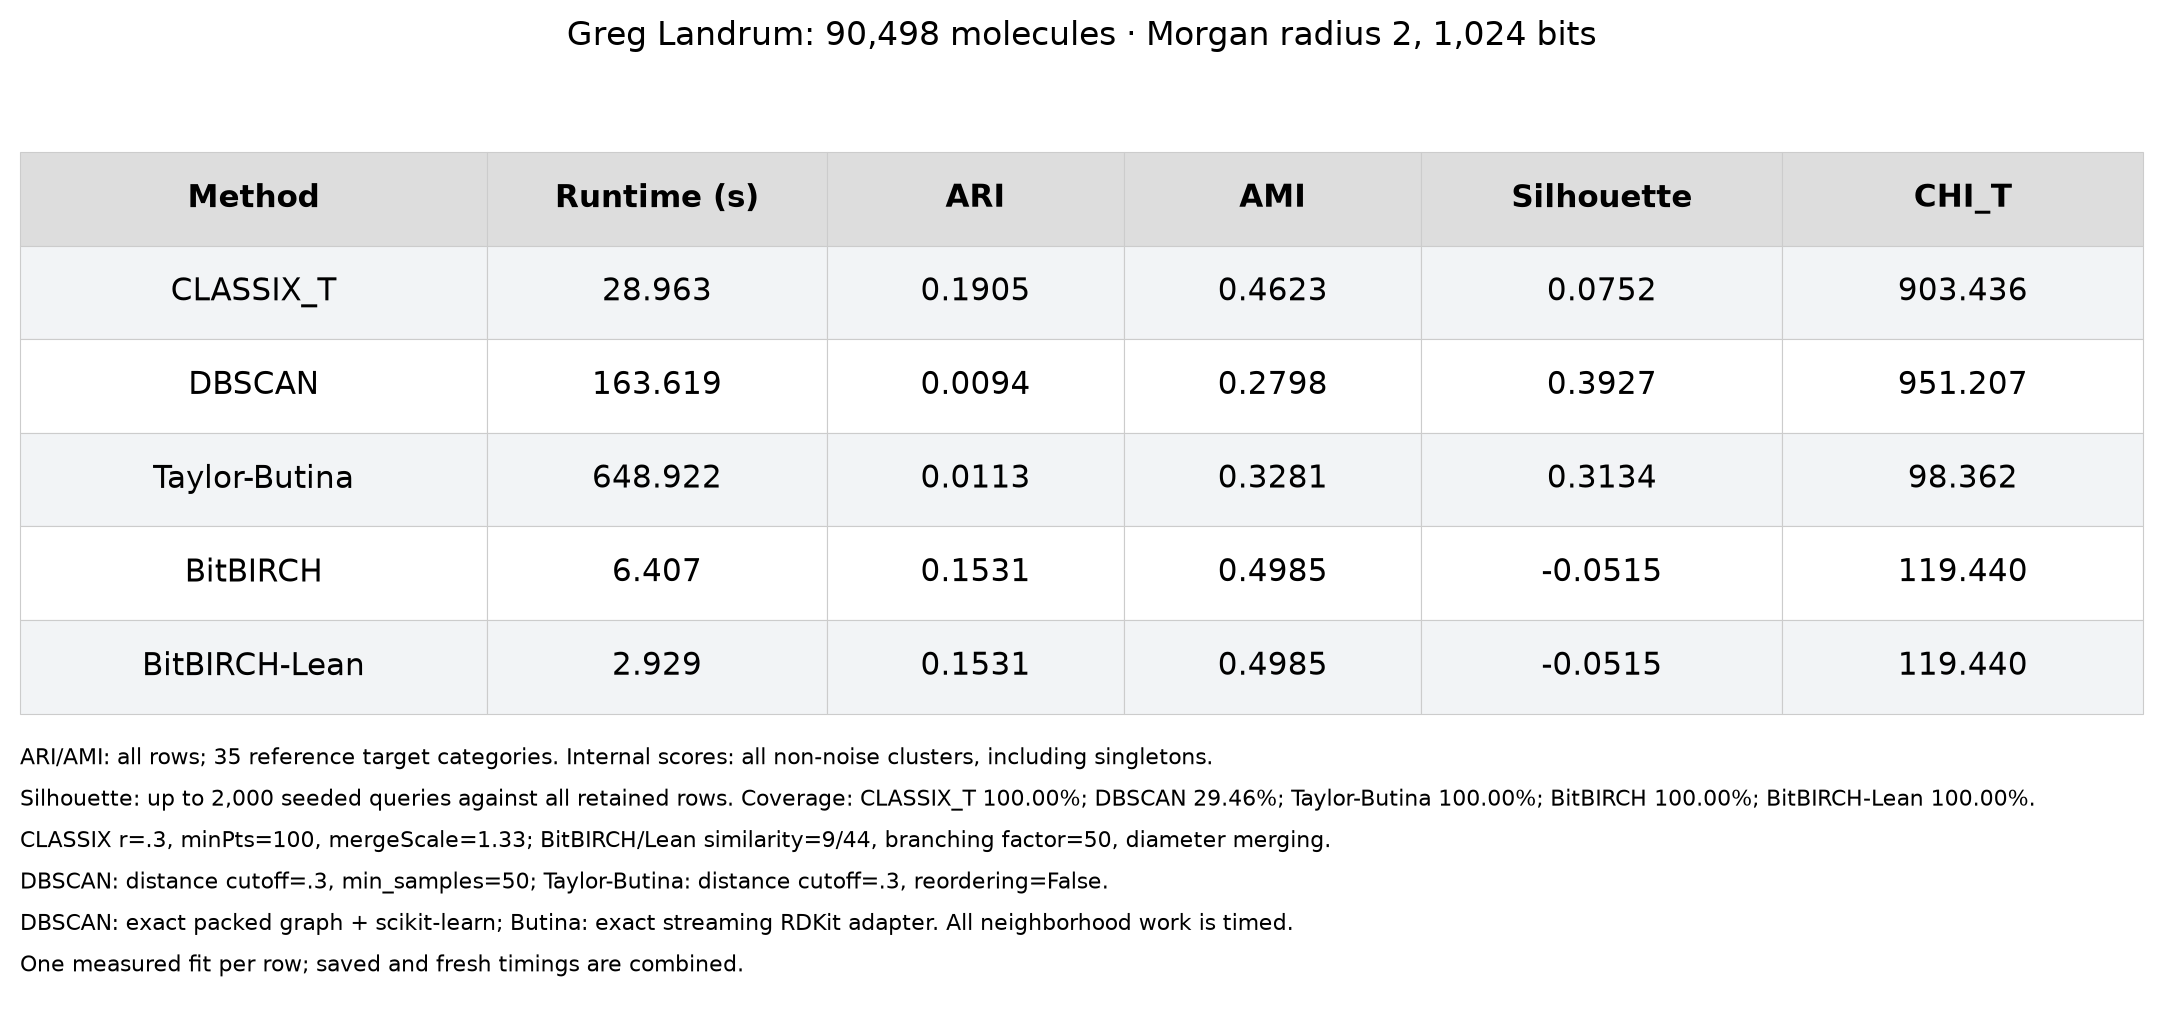

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(NOTEBOOK_DIR/"plots/landrum/landrum_comparison_table.png")))


In [ ]:
SOURCES = {}


## Complete readable reproduction source


In [ ]:
# Readable source: requirements.txt
SOURCES['requirements.txt'] = r'''# CPython 3.12, Windows x64. Install the bundled BBLean wheel separately; see README.
cloudpickle==3.1.2
colorama==0.4.6
contourpy==1.4.0
cycler==0.12.1
fonttools==4.65.0
joblib==1.6.0
kiwisolver==1.5.1
markdown-it-py==4.2.0
matplotlib==3.11.2
mdurl==0.1.2
narwhals==2.26.0
numpy==2.5.3
packaging==26.3
pillow==12.3.0
psutil==7.2.2
Pygments==2.21.0
pyparsing==3.3.3
python-dateutil==2.9.0.post0
rdkit==2026.3.6
rich==15.0.0
scikit-learn==1.9.1
scipy==1.18.1
six==1.17.0
threadpoolctl==3.7.0
tqdm==4.70.1
typing_extensions==4.16.0
'''


In [ ]:
# Readable source: code/job_limit.py
SOURCES['code/job_limit.py'] = r'''"""Windows job-object commit limit for a paused benchmark process tree.

The controller must start its child with CREATE_NO_WINDOW and keep the actual
worker paused on a READY/GO handshake until assign_job returns. Pass the actual
worker PID from READY, not the outer Windows venv-launcher PID: an already-running
launcher can use a separate nested job for its child, preventing both processes
from being added to a common new job. Only that explicitly identified worker is
assigned; subsequently created children inherit the job. The worker must have
no pre-existing subprocesses that require bounding. Process-tree discovery is
deliberately disabled: Windows parent PID snapshots can identify unrelated old
processes after a parent PID is reused. No breakaway or host-wide limit is
enabled. The outer launcher holds no benchmark arrays.

The memory limit concerns committed memory, not working-set size. Assignment
does not retroactively reject allocations made before joining the job; attach
before substantial allocations when a strict whole-run bound is needed.

API:
    job = assign_job(pid=ready["worker_pid"], max_bytes=4 * 1024**3)
    ... send GO, wait for the child ...
    close_job(job)  # also kills any remaining assigned descendants

Alternatively pass an existing process handle as the first positional argument.
An integer positional argument is a HANDLE, never interpreted as a PID.

References:
https://learn.microsoft.com/en-us/windows/win32/api/winnt/ns-winnt-jobobject_extended_limit_information
https://learn.microsoft.com/en-us/windows/win32/api/jobapi2/nf-jobapi2-assignprocesstojobobject
"""
import ctypes
from ctypes import wintypes
import os

if os.name != "nt":
    raise OSError("This benchmark resource limiter requires Windows")

_kernel = ctypes.WinDLL("kernel32", use_last_error=True)
_SIZE_T = ctypes.c_size_t
_ULONG_PTR = ctypes.c_size_t
_PROCESS_RIGHTS = 0x0001 | 0x0100 | 0x1000  # TERMINATE, SET_QUOTA, QUERY_LIMITED
_JOB_INFO_EXTENDED = 9
_JOB_OBJECT_LIMIT_JOB_MEMORY = 0x00000200
_JOB_OBJECT_LIMIT_KILL_ON_JOB_CLOSE = 0x00002000


class _BasicLimit(ctypes.Structure):
    _fields_ = [
        ("PerProcessUserTimeLimit", ctypes.c_int64),
        ("PerJobUserTimeLimit", ctypes.c_int64),
        ("LimitFlags", wintypes.DWORD),
        ("MinimumWorkingSetSize", _SIZE_T),
        ("MaximumWorkingSetSize", _SIZE_T),
        ("ActiveProcessLimit", wintypes.DWORD),
        ("Affinity", _ULONG_PTR),
        ("PriorityClass", wintypes.DWORD),
        ("SchedulingClass", wintypes.DWORD),
    ]


class _IoCounters(ctypes.Structure):
    _fields_ = [(name, ctypes.c_uint64) for name in (
        "ReadOperationCount", "WriteOperationCount", "OtherOperationCount",
        "ReadTransferCount", "WriteTransferCount", "OtherTransferCount",
    )]


class _ExtendedLimit(ctypes.Structure):
    _fields_ = [
        ("BasicLimitInformation", _BasicLimit),
        ("IoInfo", _IoCounters),
        ("ProcessMemoryLimit", _SIZE_T),
        ("JobMemoryLimit", _SIZE_T),
        ("PeakProcessMemoryUsed", _SIZE_T),
        ("PeakJobMemoryUsed", _SIZE_T),
    ]


_kernel.CreateJobObjectW.argtypes = [ctypes.c_void_p, wintypes.LPCWSTR]
_kernel.CreateJobObjectW.restype = wintypes.HANDLE
_kernel.SetInformationJobObject.argtypes = [wintypes.HANDLE, ctypes.c_int, ctypes.c_void_p, wintypes.DWORD]
_kernel.SetInformationJobObject.restype = wintypes.BOOL
_kernel.QueryInformationJobObject.argtypes = [wintypes.HANDLE, ctypes.c_int, ctypes.c_void_p, wintypes.DWORD, ctypes.c_void_p]
_kernel.QueryInformationJobObject.restype = wintypes.BOOL
_kernel.AssignProcessToJobObject.argtypes = [wintypes.HANDLE, wintypes.HANDLE]
_kernel.AssignProcessToJobObject.restype = wintypes.BOOL
_kernel.IsProcessInJob.argtypes = [wintypes.HANDLE, wintypes.HANDLE, ctypes.POINTER(wintypes.BOOL)]
_kernel.IsProcessInJob.restype = wintypes.BOOL
_kernel.OpenProcess.argtypes = [wintypes.DWORD, wintypes.BOOL, wintypes.DWORD]
_kernel.OpenProcess.restype = wintypes.HANDLE
_kernel.GetProcessId.argtypes = [wintypes.HANDLE]
_kernel.GetProcessId.restype = wintypes.DWORD
_kernel.CloseHandle.argtypes = [wintypes.HANDLE]
_kernel.CloseHandle.restype = wintypes.BOOL


def _failure(operation):
    code = ctypes.get_last_error()
    detail = ctypes.FormatError(code).strip()
    return OSError(code, f"{operation}: {detail}; benchmark must not proceed without its job limit")


def _open_process(pid):
    handle = _kernel.OpenProcess(_PROCESS_RIGHTS, False, pid)
    if not handle:
        raise _failure(f"OpenProcess({pid})")
    return handle


def process_in_job(job, *, pid):
    """Check a READY worker PID is contained before sending GO."""
    handle = _open_process(pid)
    try:
        present = wintypes.BOOL()
        if not _kernel.IsProcessInJob(handle, job, ctypes.byref(present)):
            raise _failure(f"IsProcessInJob({pid})")
        return bool(present.value)
    finally:
        _kernel.CloseHandle(handle)


def assign_job(process_handle=None, max_bytes=4 * 1024**3, *, pid=None,
               include_existing_descendants=False):
    """Bound the explicit worker; its future children inherit the same job.

    Exactly one of process_handle and pid is required. The worker must have no
    existing subprocesses requiring this limit. include_existing_descendants=True
    is rejected before opening/assigning any process; PID-only tree discovery is
    unsafe when Windows reuses PIDs. A failure, including incompatible
    enclosing/nested jobs, raises; partially assigned processes are terminated.
    The caller owns only the returned job handle, not a passed process handle.
    """
    if (process_handle is None) == (pid is None):
        raise ValueError("Pass exactly one process_handle or keyword pid")
    if include_existing_descendants is not False:
        raise ValueError("Existing-descendant discovery is disabled; pass the actual READY worker with no pre-existing subprocesses")
    if not isinstance(max_bytes, int) or not 0 < max_bytes <= ctypes.c_size_t(-1).value:
        raise ValueError("max_bytes must be a positive SIZE_T integer")
    own_process_handle = process_handle is None
    if own_process_handle:
        process_handle = _open_process(pid)
    job = None
    try:
        root_pid = int(_kernel.GetProcessId(process_handle))
        if not root_pid:
            raise _failure("GetProcessId")
        if root_pid == os.getpid():
            raise ValueError("Refusing to assign the controller itself to a kill-on-close job")
        job = _kernel.CreateJobObjectW(None, None)
        if not job:
            raise _failure("CreateJobObjectW")
        limits = _ExtendedLimit()
        limits.BasicLimitInformation.LimitFlags = (
            _JOB_OBJECT_LIMIT_JOB_MEMORY | _JOB_OBJECT_LIMIT_KILL_ON_JOB_CLOSE
        )
        limits.JobMemoryLimit = max_bytes
        if not _kernel.SetInformationJobObject(job, _JOB_INFO_EXTENDED, ctypes.byref(limits), ctypes.sizeof(limits)):
            raise _failure("SetInformationJobObject")
        if not _kernel.AssignProcessToJobObject(job, process_handle):
            raise _failure(f"AssignProcessToJobObject({root_pid}); nested-job incompatibility is possible")
        # No enumeration: only the READY process is assigned. Windows ensures
        # subsequently created children inherit the same aggregate job limit.
        return job
    except BaseException:
        if job:
            _kernel.CloseHandle(job)
        raise
    finally:
        if own_process_handle:
            _kernel.CloseHandle(process_handle)


def job_snapshot(job):
    """Return diagnostic Windows job counters.

    Peak counters can include a subsequently denied allocation attempt, so they
    may exceed the configured quota; do not interpret them as resident memory.
    """
    limits = _ExtendedLimit()
    if not _kernel.QueryInformationJobObject(job, _JOB_INFO_EXTENDED, ctypes.byref(limits), ctypes.sizeof(limits), None):
        raise _failure("QueryInformationJobObject")
    return {
        "memory_limit_bytes": int(limits.JobMemoryLimit),
        "peak_job_commit_bytes": int(limits.PeakJobMemoryUsed),
        "peak_process_commit_bytes": int(limits.PeakProcessMemoryUsed),
        "limit_flags": int(limits.BasicLimitInformation.LimitFlags),
    }


def close_job(job):
    """Close a valid job handle; any still-running member processes are killed."""
    if job and not _kernel.CloseHandle(job):
        raise _failure("CloseHandle(job)")
'''


In [ ]:
# Readable source: code/memory_win.py
SOURCES['code/memory_win.py'] = r'''"""Windows process counters; private commit is distinct from resident memory."""
import ctypes
from ctypes import wintypes


class Counters(ctypes.Structure):
    _fields_ = [("cb", wintypes.DWORD), ("PageFaultCount", wintypes.DWORD)] + [
        (name, ctypes.c_size_t) for name in (
            "PeakWorkingSetSize", "WorkingSetSize", "QuotaPeakPagedPoolUsage",
            "QuotaPagedPoolUsage", "QuotaPeakNonPagedPoolUsage",
            "QuotaNonPagedPoolUsage", "PagefileUsage", "PeakPagefileUsage", "PrivateUsage")]


kernel = ctypes.WinDLL("kernel32", use_last_error=True)
psapi = ctypes.WinDLL("psapi", use_last_error=True)
kernel.GetCurrentProcess.restype = wintypes.HANDLE
kernel.OpenProcess.argtypes = [wintypes.DWORD, wintypes.BOOL, wintypes.DWORD]
kernel.OpenProcess.restype = wintypes.HANDLE
kernel.CloseHandle.argtypes = [wintypes.HANDLE]
kernel.CloseHandle.restype = wintypes.BOOL
psapi.GetProcessMemoryInfo.argtypes = [wintypes.HANDLE, ctypes.POINTER(Counters), wintypes.DWORD]
psapi.GetProcessMemoryInfo.restype = wintypes.BOOL


def open_process(pid):
    handle = kernel.OpenProcess(0x1000, False, pid)
    if not handle:
        raise ctypes.WinError(ctypes.get_last_error())
    return handle


def close_process(handle):
    kernel.CloseHandle(handle)


def snapshot(handle=None):
    counters = Counters()
    counters.cb = ctypes.sizeof(counters)
    if not psapi.GetProcessMemoryInfo(handle or kernel.GetCurrentProcess(), ctypes.byref(counters), counters.cb):
        raise ctypes.WinError(ctypes.get_last_error())
    return {
        "private_commit_bytes": counters.PrivateUsage,
        "working_set_bytes": counters.WorkingSetSize,
        "lifetime_peak_private_commit_bytes": counters.PeakPagefileUsage,
        "lifetime_peak_working_set_bytes": counters.PeakWorkingSetSize,
    }
'''


In [ ]:
# Readable source: code/quality.py
SOURCES['code/quality.py'] = r'''"""Adjusted Rand index from the contingency table, using Python integers."""
import numpy as np


def adjusted_rand_index(truth, labels):
    _, a = np.unique(truth, return_inverse=True)
    _, b = np.unique(labels, return_inverse=True)
    table = np.zeros((int(a.max())+1, int(b.max())+1), dtype=np.int64)
    np.add.at(table, (a, b), 1)
    def pairs(counts):
        return sum(int(x)*(int(x)-1)//2 for x in counts.flat)
    total = len(a)*(len(a)-1)//2
    cells, rows, cols = pairs(table), pairs(table.sum(axis=1)), pairs(table.sum(axis=0))
    denominator = total*(rows+cols)-2*rows*cols
    return 1.0 if denominator == 0 else 2*(total*cells-rows*cols)/denominator
'''


In [ ]:
# Readable source: code/state_checks.py
SOURCES['code/state_checks.py'] = r'''"""Validation after measurement, using bounded temporary buffers for hashes."""
import hashlib
import json
import numpy as np


def array_hash(array):
    array = np.ascontiguousarray(array)
    return hashlib.sha256(memoryview(array).cast("B")).hexdigest()


def logical_hash(data, n_features, packing=None):
    result = hashlib.sha256()
    for start in range(0, len(data), 256):
        block = data[start:start+256]
        if packing:
            block = np.unpackbits(block, axis=1, count=n_features, bitorder=packing)
        block = np.ascontiguousarray(block, dtype=np.int32)
        result.update(memoryview(block).cast("B"))
    return result.hexdigest()


def state_fingerprint(model, n_features, packed=False):
    fields = ("labels", "aggregation_labels", "splist", "group_sizes", "group_labels",
              "initial_merging_labels", "ind", "unsort_ind", "Adj")
    state = {}
    for name in fields:
        value = getattr(model, name)
        if name == "Adj" and hasattr(value, "iter_row_blocks"):
            digest = hashlib.sha256()
            for block in value.iter_row_blocks(rows=max(1, min(128, (8*1024*1024)//max(1, value.shape[1])))):
                digest.update(memoryview(np.ascontiguousarray(block)).cast("B"))
            state[name] = {"shape": list(value.shape), "dtype": "int8", "sha256": digest.hexdigest()}
            continue
        array = np.asarray(value)
        state[name] = {"shape": list(array.shape), "dtype": str(array.dtype), "sha256": array_hash(array)}
    state["logical_centers"] = logical_hash(model.spdata, n_features, "little" if packed else None)
    state["aggregation_dict"] = hashlib.sha256(json.dumps(model.aggregation_dict, sort_keys=True, default=lambda v: int(v)).encode()).hexdigest()
    return state
'''


In [ ]:
# Readable source: code/classix/classix_t_packed_adjbits.py
SOURCES['code/classix/classix_t_packed_adjbits.py'] = r'''# Temporary storage-only prototype; source and focused diff are recorded.
import sys
from pathlib import Path
sys.path.insert(0, str(Path(__file__).resolve().parent))
from packed_adjacency import PackedAdjacency
#%%
import numpy as np
from time import time
from tqdm import tqdm
from copy import deepcopy
from collections import deque
import scipy.sparse as sparse
from scipy import sparse
from fractions import Fraction
from packed_native import packed_submatxvec, row_popcounts

class CLASSIX_T_PACKED:
    def __init__(self, sorting="popcount", radius=0.3, minPts=1, group_merging="tanimoto_distance", norm=True, mergeScale=1.4, post_alloc=True, mergeTinyGroups=True, verbose=1, short_log_form=True, use_spmv=True):
        self.group_merging = group_merging
        self.mergeScale = mergeScale
        self.mergeTinyGroups = mergeTinyGroups
        self.sorting = sorting
        self.radius = radius
        self.minPts = minPts
        self.norm = norm

        self.post_alloc = post_alloc
        self.mergeTinyGroups = mergeTinyGroups
        self.verbose = verbose
        self.truncate = short_log_form


    
    def __str__(self):
        return f"CLASSIX_T(sorting={self.sorting}, radius={self.radius}, minPts={self.minPts}, group_merging={self.group_merging}, mergeScale={self.mergeScale}, mergeTinyGroups={self.mergeTinyGroups})"
    
    def __repr__(self):
        return f"CLASSIX_T(sorting={self.sorting}, radius={self.radius}, minPts={self.minPts}, group_merging={self.group_merging}, mergeScale={self.mergeScale}, mergeTinyGroups={self.mergeTinyGroups})"
    
    def fit(self, data, r=None, mergeScale=None, minPts=None):
        total_time = time()
        if r is not None:
            self.radius = r
        
        if mergeScale is not None:
            self.mergeScale = mergeScale

        if minPts is not None:
            self.minPts = minPts

        # Input is np.packbits(binary_rows, axis=1, bitorder='little').
        # Any padding bits in the final byte must be zero.
        data = np.asarray(data)
        if data.ndim != 2 or data.dtype != np.uint8:
            raise ValueError("Expected a 2D uint8 array of packed binary fingerprints")
        if not data.shape[0] or not data.shape[1]:
            raise ValueError("Packed input must have at least one row and one byte")
        data = np.ascontiguousarray(data)
        n, fdim = data.shape
        sort_vals = row_popcounts(data).astype(np.int64, copy=False)

        # print(sort_vals)

        self.ind = np.argsort(sort_vals, kind='stable')
        self.unsort_ind = np.argsort(self.ind, kind='stable')
        sort_vals = sort_vals[self.ind] 
        data = data[self.ind,:] # sort data

        # print(data)

        print("\nOWN AGGREGATION")


        ips_time = 0.0
        search_time = 0.0
        loop_time = 0.0
        conversion_time = 0.0
        
        st = time()
        lab = 0

        # labels of the data points. Initially all are -1 to keep track of unallocated points
        self.labels = np.array([-1]*n)
        nr_dist = 0
        # Indices of group starting pts, equivalent of the gc list in the original code
        self.splist = []
        rhs = 1/(1-self.radius)+1; # rhs of tanimoto distance inequality
        rhsi = 1/rhs

        rhs_n = 2 - self.radius
        rhs_d = 1 - self.radius

        # Do a small check to see if radius is a rational number:
        # If it is, we can use the rhs_n and rhs_d values to avoid floating point errors!

        self.group_sizes = [] # group sizes
        self.group_starting_pts = [] # group starting pts in the sorted array

        # Packed rows are used directly: no CSR construction is required.
        self.aggregation_dict = {}
        
        
        # Aggregation
        for i in tqdm(range(n)):
            
            if self.labels[i] >= 0:
                continue
                
            clustc = data[i,:]
            
            # What if we take the starting point as a slice of the sparse array instead?
            # clustc = datas[i,:]
            #
            self.labels[i] = lab

            # num_group = 1
            self.splist.append(i)
            self.group_sizes.append(1)
            
            search_radius = sort_vals[i]/(1-self.radius) # Only the right side limit is needed
            
            st1 = time()
            last_j = np.searchsorted(sort_vals, search_radius, side='right')
            self.aggregation_dict[i] = last_j

            search_time += time() - st1

            st1 = time()

            # ips = data[i+1:last_j,:]@clustc.T
            ips = packed_submatxvec(data, i+1, last_j, clustc)

            ips_time += time() - st1
            # Let's make the product with rhsi times sort_vals the condition.
            # lhs = sort_vals[i+1:last_j]
            
            nr_dist += last_j - i - 1
            
            st_c = time()

            vec = ips/(sort_vals[i+1:last_j]+sort_vals[i])
            conversion_time += time() - st_c
            
            st1 = time()

            """
            Create a custom C function that takes in a range of indices, a vector, and a scalar value.
            If the value of the vector at index i is greater than 0, it will check if the value is greater than the scalar value,
            
            Maybe just try boolean masks first?
            Note: self.labels has size = n
                  vec has size = last_j - i - 1

            The boolean mask of vec needs to padded with False values to match the size of self.labels

            Then we can take the intersection of the two boolean masks.

            ```
            vec_mask = vec >= rhsi
            assigned_mask = self.labels >= 0
            
            ```

            """

            notAssigned = self.labels < 0
            vec_mask = vec >= rhsi
            vec_mask = np.pad(vec_mask, (i+1, n - last_j), 'constant', constant_values=False)
            reassignMask = np.logical_and(notAssigned, vec_mask)
            self.group_sizes[-1] += np.sum(reassignMask)
            self.labels[reassignMask] = lab


            # for j in range(i+1, last_j):
            #     if self.labels[j] >= 0:
            #         continue

            #     # if sort_vals[j]+sort_vals[i]<=rhs*ips[j-i-1]:
            #     if (sort_vals[j]+sort_vals[i])*rhs_d<=rhs_n*ips[j-i-1]: # No division!
            #         # num_group += 1
            #         self.labels[j] = lab
            #         self.group_sizes[-1] += 1
                            
            loop_time += time() - st1

            lab += 1
            
        print("time for ips:", ips_time)
        print("time for search:", search_time)
        print("time for conversion:", conversion_time)
        print("time for loop:", loop_time)
        print("nr_dist:", nr_dist)

        self.aggregation_labels = deepcopy(np.array(self.labels))
        self.search_time = search_time
        self.ips_time = ips_time
        self.aggregation_time = time()-st
        
        # merging
        st = time()

        self.spdata = data[self.splist,:]
        # Group representatives also remain packed.
        spdata_len = len(self.splist)
        self.group_centers = self.spdata

        # Scores of the group starting points
        sort_vals_sp = sort_vals[self.splist]

        # Group labels of the group starting points
        label_sp = self.labels[self.splist]
        scale = self.mergeScale

        
        

        self.Adj = PackedAdjacency(len(self.splist))
        
        t1 = 0.0
        t2 = 0.0
        t3 = 0.0
        minPts = self.minPts

        for i in tqdm(range(len(self.splist))):
            if not self.mergeTinyGroups:
                if self.group_sizes[i] < minPts:
                    continue
                
            xi = self.spdata[i, :]
            search_radius = sort_vals_sp[i]/(1-self.mergeScale*self.radius)

            st1 = time()
            last_j = np.searchsorted(sort_vals_sp, search_radius, side='right')
            first_j = i
            ips = packed_submatxvec(self.spdata, first_j, last_j, xi)
            # ips = np.matmul(self.spdata[first_j:last_j,:],xi.T)
            tanimoto_distance = 1 - ips/(sort_vals_sp[i] + sort_vals_sp[first_j:last_j] - ips)
            # tanimoto_distance = 1 - tanimoto_score
            t1 += time() - st1

            st2 = time()
            inds = np.where(tanimoto_distance <= scale*self.radius)

            if not self.mergeTinyGroups:
                inds = inds[0][self.group_sizes[inds[0]] >= minPts]
                inds = i + inds
            
            else:
                inds = i + inds[0]



            self.Adj[i, inds] = 1
            self.Adj[inds, i] = 1

            spl = np.unique(label_sp[ inds ])

            minlab = np.min(spl)

            t2 += time() - st2

            st3 = time()
            for label in spl:
                label_sp[label_sp==label] = minlab
            t3 += time() - st3
            # continue

        self.initial_merging_labels = deepcopy(label_sp)

        print("  merging time:", time()-st)
        self.merging_time = time()-st
        
        # Cluster redistribution
        print(" minPts Merging")
        st = time()
        ############################################################################################################

        labels_sp_copy = deepcopy(label_sp)
        ul = np.unique(label_sp)
        cs = np.zeros(len(ul))
        self.group_sizes = np.array(self.group_sizes)
        for i in range(len(ul)):
            id = np.where(label_sp==ul[i])
            label_sp[id] = i
            cs[i] = np.sum(self.group_sizes[id])

        small_clusters = np.where(cs<self.minPts)[0]

        # print("small clusters", small_clusters)

        labels_sp_copy_2 = deepcopy(label_sp)

        for i in small_clusters:
            ii = np.where(labels_sp_copy_2==i)[0]
            for iii in ii:
                xi = self.spdata[iii, :]
                # d = Tanimoto distances to all other group centers
                # ips = np.matmul(self.spdata, xi.T)
                ips = packed_submatxvec(self.spdata, 0, spdata_len, xi)
                d = 1 - ips/(sort_vals_sp[iii] + sort_vals_sp - ips)
                
                o = np.argsort(d, kind='stable')
                # merge with the closest group that has more than minPts
                for j in o:
                    if cs[labels_sp_copy_2[j]]>=minPts:
                        label_sp[iii] = labels_sp_copy_2[j]
                        # Instead of having a separate Adjanceny matrix for the points merged with minPts criteria
                        # we can just update the old Adjacency matrix here. The issue is that the distance matrix will
                        # have some weird discrepancies.
                        self.Adj[iii, j] = 2
                        self.Adj[j, iii] = 2
                        break

        ul = np.unique(label_sp)
        cs = np.zeros(len(ul))
        for i in range(len(ul)):
            id = np.where(label_sp==ul[i])
            label_sp[id] = i
            cs[i] = np.sum(self.group_sizes[id])

        # print("final cluster sizes", cs)

        print("  minPts merging time:", time()-st)
        
        for idx, label in enumerate(self.labels):
            self.labels[idx] = label_sp[label]

        ############################################################################################################

        self.labels = self.labels[self.unsort_ind]
        # print(self.labels)
        self.aggregation_labels = self.aggregation_labels[self.unsort_ind]
        self.group_labels = label_sp
        self.group_centre_pts = self.spdata
        self.group_centers = self.splist
        print("Total time:", time()-total_time)
        return self

    def explain(self, ind1=None, ind2=None):
        if ind1 is None and ind2 is None:
            # If there are no specific points to explain, print the general information
            print(f"The data was clustered into {len(self.group_labels)} groups. These were further merged into {len(np.unique(self.group_labels))} clusters.")

        if ind1 is not None and ind2 is None:
            # If only one index is provided, print the cluster information for that index
            print(f"The data point at index {ind1} was assigned to cluster {self.labels[ind1]}")

        if ind1 is not None and ind2 is not None:
            # If two indices are provided, print the cluster information
            if self.labels[ind1] == self.labels[ind2]:
                # If the two data points belong to the same cluster, check if they are in the same group
                print(f"The data points at indices {ind1} and {ind2} belong to the same cluster.")
                agg_label_1 = self.aggregation_labels[ind1]
                agg_label_2 = self.aggregation_labels[ind2]
                if agg_label_1 == agg_label_2:
                    # If the two data points are in the same group, print the information
                    print(f"The data points at indices {ind1} and {ind2} are in the same group {agg_label_1}.")
                    return None

                else:
                    # If the two data points are in different groups, find the shortest connection path between the two groups
                    print(f"The data points at indices {ind1} and {ind2} are in different groups.")
                    connected_path = self.bfs_shortest_path(self.Adj, agg_label_1, agg_label_2)
                    if connected_path is not None:
                        # If a connection path is found, print the path
                        print(f'The connections between {ind1} and {ind2} are via this path: {connected_path[0]} ', end="")
                        for k in range(len(connected_path)-1):
                            if self.Adj[connected_path[k]-1, connected_path[k+1]-1] == 2:
                                print(f'(minPts) -> {connected_path[k+1]}', end="")
                            else:
                                print(f' -> {connected_path[k+1]}', end="")

                        return connected_path
                    
                    else:
                        # If no connection path is found, print that there is no connection, there must be something wrong with the code
                        print(f"No connection path found between {ind1} and {ind2}, although they belong to different groups in the same cluster. Please check the program for bugs!")
                        return None

            else:
                print(f"The data points at indices {ind1} and {ind2} belong to different clusters.")


    def bfs_shortest_path(self, adj_matrix, start, goal):
        # Convert start and goal from 1-based to 0-based indices
        start -= 1
        goal -= 1
        
        # Initialize the queue with the start node and a path containing only the start node
        queue = deque([(start, [start])])
        
        # Keep track of visited nodes to avoid cycles
        visited = set()
        
        while queue:
            # Dequeue a node and the path that led to it
            current_node, path = queue.popleft()
            
            # If the current node is the goal, return the path
            if current_node == goal:
                return [node + 1 for node in path]  # Convert back to 1-based indices
            
            # Mark the current node as visited
            visited.add(current_node)
            
            # Enqueue all unvisited neighbors
            for neighbor, connected in enumerate(adj_matrix[current_node]):
                if connected and neighbor not in visited:
                    queue.append((neighbor, path + [neighbor]))

        return None
# %%
'''


In [ ]:
# Readable source: code/classix/LICENSE
SOURCES['code/classix/LICENSE'] = r'''MIT License

Copyright (c) 2026 Kaustubh Roy

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
'''


In [ ]:
# Readable source: code/classix/packed_adjacency.py
SOURCES['code/classix/packed_adjacency.py'] = r'''"""CLASSIX adjacency with packed connections and sparse minPts edge markers.

Each logical entry is 0, 1, or 2. One bit records whether an edge exists; sparse
row-to-column sets mark edges whose logical value is 2. The connection buffer is
exactly G * ceil(G / 8) bytes for a G by G matrix. Sparse marker overhead is
separate and exposed as a Python-object size estimate. No dense graph is
allocated by construction, reads of individual edges, or writes. Decoding a row
returns an independent int8 array, not a writable view.

Supported writes match CLASSIX's existing operations:
    graph[i, columns] = 1
    graph[rows, j] = 1
    graph[i, j] = 2
The same forms accept 0 to clear edges. Repeated indices and different bits in
one byte are handled correctly using unbuffered NumPy ufunc.at updates.

Call iter_row_blocks(rows=...) for bounded logical hashing or validation.
Implicit conversion of the whole graph to a dense NumPy array is prohibited.
"""
import operator
import sys

import numpy as np


def _integer(value, name):
    if isinstance(value, (bool, np.bool_)):
        raise TypeError(f"{name} must be an integer, not a boolean")
    try:
        return operator.index(value)
    except TypeError as error:
        raise TypeError(f"{name} must be an integer") from error


class PackedAdjacency:
    """Logical int8 adjacency: one bit/entry plus sparse markers for value 2."""

    __slots__ = ("_n", "_row_bytes", "_connections", "_minpts")
    dtype = np.dtype(np.int8)
    ndim = 2

    def __init__(self, groups):
        groups = _integer(groups, "groups")
        if groups < 0:
            raise ValueError("groups must be nonnegative")
        self._n = groups
        self._row_bytes = (groups + 7) // 8
        self._connections = np.zeros((groups, self._row_bytes), dtype=np.uint8)
        self._minpts = {}

    @property
    def shape(self):
        return (self._n, self._n)

    @property
    def size(self):
        return self._n * self._n

    @property
    def nbytes(self):
        """Exact connection-buffer bytes; sparse marker objects are separate."""
        return self._connections.nbytes

    @property
    def connection_bits(self):
        """Read-only packed rows marking every connection, including minPts edges."""
        view = self._connections.view()
        view.flags.writeable = False
        return view

    @property
    def marker_count(self):
        """Number of directed edges marked as minPts edges."""
        return sum(len(columns) for columns in self._minpts.values())

    @property
    def marker_storage_bytes(self):
        """Estimated sparse-marker Python object bytes, for reporting only.

        Counts the dictionary, sets, row/column integers once by object identity.
        It excludes allocator overhead and may include shared/interned integers;
        therefore this is an estimate, not measured process memory. Cost is O(M)
        in stored directed markers, so avoid querying inside the clustering loop.
        """
        seen = set()
        def size_once(value):
            identity = id(value)
            if identity in seen:
                return 0
            seen.add(identity)
            return sys.getsizeof(value)
        total = size_once(self._minpts)
        for row, columns in self._minpts.items():
            total += size_once(row) + size_once(columns)
            total += sum(size_once(column) for column in columns)
        return total

    @property
    def logical_nbytes(self):
        """Bytes the equivalent dense int8 matrix would require."""
        return self.size

    def __len__(self):
        return self._n

    def __repr__(self):
        return f"PackedAdjacency(shape={self.shape}, nbytes={self.nbytes}, marker_count={self.marker_count})"

    def __array__(self, dtype=None, copy=None):
        raise TypeError("Whole-graph conversion is disabled; use iter_row_blocks(rows=...) or graph[i]")

    def _index(self, index):
        index = _integer(index, "index")
        if index < 0:
            index += self._n
        if not 0 <= index < self._n:
            raise IndexError("adjacency index out of bounds")
        return index

    def _selection(self, selection):
        if isinstance(selection, (int, np.integer)) and not isinstance(selection, (bool, np.bool_)):
            return self._index(selection)
        values = np.asarray(selection)
        if values.ndim != 1:
            raise TypeError("indices must be a scalar integer or a one-dimensional integer array")
        if values.size == 0:
            return np.empty(0, dtype=np.intp)
        if values.dtype.kind not in "iu":
            raise TypeError("indices must have an integer dtype")
        # Check unsigned values before casting to np.intp to prevent wraparound.
        if np.any(values >= self._n) or (values.dtype.kind == "i" and np.any(values < -self._n)):
            raise IndexError("adjacency index out of bounds")
        values = values.astype(np.intp, copy=False)
        if np.any(values < 0):
            values = np.where(values < 0, values + self._n, values)
        return values

    def _pair(self, key):
        if not isinstance(key, tuple) or len(key) != 2:
            raise IndexError("edge access requires exactly two indices")
        row, column = (self._selection(index) for index in key)
        if isinstance(row, np.ndarray) and isinstance(column, np.ndarray):
            raise TypeError("at most one index may be a vector")
        return row, column

    def __getitem__(self, key):
        if not isinstance(key, tuple):
            row = self._index(key)
            decoded = np.unpackbits(self._connections[row], bitorder="little", count=self._n).view(np.int8)
            markers = self._minpts.get(row)
            if markers:
                decoded[np.fromiter(markers, dtype=np.intp, count=len(markers))] = 2
            return decoded
        row, column = self._pair(key)
        byte_index = column >> 3
        offset = column & 7
        result = (self._connections[row, byte_index] >> offset) & 1
        if np.ndim(result) == 0:
            return np.int8(2 if column in self._minpts.get(row, ()) else result)
        result = np.asarray(result, dtype=np.int8)
        if not self._minpts:
            return result
        if isinstance(row, int):
            markers = self._minpts.get(row)
            if markers:
                mask = np.fromiter((int(c) in markers for c in column), dtype=bool, count=len(column))
                result[mask] = 2
        else:
            mask = np.fromiter((column in self._minpts.get(int(r), ()) for r in row), dtype=bool, count=len(row))
            result[mask] = 2
        return result

    def _write_marker(self, row, column, marked):
        if marked:
            markers = self._minpts.get(row)
            if markers is None:
                self._minpts[row] = {column}
            else:
                markers.add(column)
        else:
            markers = self._minpts.get(row)
            if markers is not None:
                markers.discard(column)
                if not markers:
                    del self._minpts[row]

    def __setitem__(self, key, value):
        value = _integer(value, "edge value")
        if not 0 <= value <= 2:
            raise ValueError("edge values must be 0, 1, or 2")
        row, column = self._pair(key)
        if isinstance(row, int) and isinstance(column, int):
            byte_index = column >> 3
            mask = np.uint8(1 << (column & 7))
            clear_mask = np.bitwise_not(mask)
            current = self._connections[row, byte_index]
            self._connections[row, byte_index] = current | mask if value else current & clear_mask
            self._write_marker(row, column, value == 2)
            return
        if isinstance(column, np.ndarray):
            byte_indices = column >> 3
            masks = np.left_shift(np.uint8(1), (column & 7).astype(np.uint8))
            target = (row, byte_indices)
        else:
            masks = np.uint8(1 << (column & 7))
            target = (row, column >> 3)
        if value:
            np.bitwise_or.at(self._connections, target, masks)
        else:
            np.bitwise_and.at(self._connections, target, np.bitwise_not(masks))
        if isinstance(row, int):
            if value == 2 and column.size:
                markers = self._minpts.get(row)
                if markers is None:
                    self._minpts[row] = set(map(int, column))
                else:
                    markers.update(map(int, column))
            elif row in self._minpts:
                markers = self._minpts[row]
                markers.difference_update(map(int, column))
                if not markers:
                    del self._minpts[row]
        elif value == 2 or self._minpts:
            # Normal vector writes during merging incur no Python per-edge loop
            # while the marker dictionary is empty. minPts writes are scalar in
            # CLASSIX; support vector marker writes for a complete tested API.
            for item in map(int, row):
                self._write_marker(item, column, value == 2)

    def iter_row_blocks(self, rows=64):
        """Yield dense int8 row chunks with shape at most (rows, G).

        One decoded int8 chunk is allocated. Callers should process chunks sequentially rather than
        collecting them, to keep memory bounded.
        """
        rows = _integer(rows, "rows")
        if rows <= 0:
            raise ValueError("rows must be positive")
        for start in range(0, self._n, rows):
            stop = min(start + rows, self._n)
            decoded = np.unpackbits(self._connections[start:stop], axis=1,
                                    bitorder="little", count=self._n).view(np.int8)
            for row in range(start, stop):
                markers = self._minpts.get(row)
                if markers:
                    decoded[row - start, np.fromiter(markers, dtype=np.intp, count=len(markers))] = 2
            yield decoded
'''


In [ ]:
# Readable source: code/classix/packed_kernel.c
SOURCES['code/classix/packed_kernel.c'] = r'''/* Isolated binary-fingerprint prototype. Does not modify the original source.
 * Input: row-major np.packbits(..., axis=1, bitorder="little") uint8 arrays.
 * Padding bits must be zero. memcpy avoids alignment/aliasing assumptions.
 */
#include <stdint.h>
#include <stddef.h>
#include <string.h>
#include <intrin.h>

#define EXPORT __declspec(dllexport)

EXPORT int hardware_popcount_available(void) {
    int regs[4];
    __cpuid(regs, 1);
    return (regs[2] & (1 << 23)) != 0;
}

static __forceinline unsigned int portable_popcount64(uint64_t value) {
    value -= (value >> 1) & UINT64_C(0x5555555555555555);
    value = (value & UINT64_C(0x3333333333333333)) +
            ((value >> 2) & UINT64_C(0x3333333333333333));
    value = (value + (value >> 4)) & UINT64_C(0x0f0f0f0f0f0f0f0f);
    return (unsigned int)((value * UINT64_C(0x0101010101010101)) >> 56);
}

static __forceinline unsigned int popcount64(uint64_t value, int hardware) {
    return hardware ? (unsigned int)__popcnt64(value) : portable_popcount64(value);
}

EXPORT void row_popcounts(const uint8_t *packed, int nrows, int nbytes,
                          int32_t *output) {
    const int hardware = hardware_popcount_available();
    for (int row = 0; row < nrows; ++row) {
        const uint8_t *current = packed + (size_t)row * (size_t)nbytes;
        int32_t count = 0;
        int column = 0;
        for (; column + 8 <= nbytes; column += 8) {
            uint64_t word;
            memcpy(&word, current + column, sizeof(word));
            count += (int32_t)popcount64(word, hardware);
        }
        for (; column < nbytes; ++column) {
            count += (int32_t)popcount64(current[column], hardware);
        }
        output[row] = count;
    }
}

EXPORT void packed_submatxvec(const uint8_t *packed, int nbytes,
                             int start_row, int end_row,
                             const uint8_t *vector, int32_t *output) {
    const int hardware = hardware_popcount_available();
    for (int row = start_row; row < end_row; ++row) {
        const uint8_t *current = packed + (size_t)row * (size_t)nbytes;
        int32_t intersection = 0;
        int column = 0;
        for (; column + 8 <= nbytes; column += 8) {
            uint64_t lhs, rhs;
            memcpy(&lhs, current + column, sizeof(lhs));
            memcpy(&rhs, vector + column, sizeof(rhs));
            intersection += (int32_t)popcount64(lhs & rhs, hardware);
        }
        for (; column < nbytes; ++column) {
            intersection += (int32_t)popcount64(current[column] & vector[column], hardware);
        }
        output[row - start_row] = intersection;
    }
}
'''


In [ ]:
# Readable source: code/classix/packed_native.py
SOURCES['code/classix/packed_native.py'] = r'''"""Strict ctypes interfaces for the isolated packed-bit trial.

The original interface deliberately matches the original Python wrapper's hot
path and assumes valid immutable SciPy CSR arrays and row/vector bounds. Call
validate_original_csr once before timing; ctypes argtypes still enforce dtype,
dimensionality, and contiguity. Extra per-call validation would introduce
artificial overhead absent from the published wrapper.
"""
from ctypes import CDLL, c_int
from pathlib import Path

import numpy as np

_ROOT = Path(__file__).resolve().parent
_packed = CDLL(str(_ROOT / "packed_kernel.dll"))
_original = CDLL(str(_ROOT / "original_spmv.dll"))
_int32_1d = np.ctypeslib.ndpointer(dtype=np.int32, ndim=1, flags="C_CONTIGUOUS")
_uint8_1d = np.ctypeslib.ndpointer(dtype=np.uint8, ndim=1, flags="C_CONTIGUOUS")
_uint8_2d = np.ctypeslib.ndpointer(dtype=np.uint8, ndim=2, flags="C_CONTIGUOUS")
_packed.hardware_popcount_available.argtypes = []
_packed.hardware_popcount_available.restype = c_int
_packed.row_popcounts.argtypes = [_uint8_2d, c_int, c_int, _int32_1d]
_packed.row_popcounts.restype = None
_packed.packed_submatxvec.argtypes = [
    _uint8_2d, c_int, c_int, c_int, _uint8_1d, _int32_1d
]
_packed.packed_submatxvec.restype = None
_original.multiply.argtypes = [
    _int32_1d, _int32_1d, _int32_1d, c_int, c_int, _int32_1d, _int32_1d
]
_original.multiply.restype = None
HARDWARE_POPCOUNT = bool(_packed.hardware_popcount_available())
_INT_MAX = np.iinfo(np.int32).max


def _array(value, dtype, ndim, name):
    if not isinstance(value, np.ndarray):
        raise TypeError(f"{name} must be a numpy array")
    if value.dtype != dtype or value.ndim != ndim or not value.flags.c_contiguous:
        raise TypeError(f"{name} must be a C-contiguous {ndim}D {np.dtype(dtype)} array")
    return value


def _bounds(start, end, nrows):
    if not isinstance(start, (int, np.integer)) or not isinstance(end, (int, np.integer)):
        raise TypeError("row bounds must be integers")
    if not 0 <= start <= end <= nrows <= _INT_MAX:
        raise ValueError("invalid row bounds or too many rows for native int32 API")


def _packed_shape(data):
    _array(data, np.uint8, 2, "data")
    nrows, nbytes = data.shape
    if nrows > _INT_MAX or nbytes > _INT_MAX // 8:
        raise ValueError("packed shape exceeds native int32 API")
    return nrows, nbytes


def row_popcounts(data):
    nrows, nbytes = _packed_shape(data)
    output = np.empty(nrows, dtype=np.int32)
    _packed.row_popcounts(data, nrows, nbytes, output)
    return output


def packed_submatxvec(data, start, end, vector):
    nrows, nbytes = _packed_shape(data)
    _bounds(start, end, nrows)
    _array(vector, np.uint8, 1, "vector")
    if vector.size != nbytes:
        raise ValueError("packed vector length differs from packed matrix row width")
    output = np.empty(end - start, dtype=np.int32)
    _packed.packed_submatxvec(data, nbytes, start, end, vector, output)
    return output


def validate_original_csr(values, indptr, indices, nfeatures):
    """Validate full CSR index contents once, outside timing boundaries."""
    _array(values, np.int32, 1, "values")
    _array(indptr, np.int32, 1, "indptr")
    _array(indices, np.int32, 1, "indices")
    if indptr.size == 0 or values.size != indices.size:
        raise ValueError("invalid CSR array lengths")
    if indptr[0] != 0 or indptr[-1] != values.size or np.any(indptr[1:] < indptr[:-1]):
        raise ValueError("invalid CSR row pointers")
    if indices.size and (indices.min() < 0 or indices.max() >= nfeatures):
        raise ValueError("CSR column indices exceed vector bounds")
    if indptr.size - 1 > _INT_MAX:
        raise ValueError("too many CSR rows")


def original_spsubmatxvec(values, indptr, indices, start, end, vector):
    """Original hot path; callers supply valid SciPy CSR arrays and bounds."""
    output = np.zeros(end - start).astype(np.int32)
    _original.multiply(values, indptr, indices, start, end, vector, output)
    return output
'''


In [ ]:
# Readable source: code/classix/spsubmatxvec.c
SOURCES['code/classix/spsubmatxvec.c'] = r'''void multiply(
    const int *m_data, const int *m_indptr, const int *m_indices,
    int start_row, int end_row, const int *v_data, int *result) {
    
    int j = 0;
    int val = 0;
    int num_vals_matrix = 0;
    int idx = 0;
    int m_indptri = 0;
    
    for (int i = start_row; i < end_row; i++) {
        m_indptri = m_indptr[i];
        num_vals_matrix = m_indptr[i+1] - m_indptri;
        val = 0;
        for (j = m_indptri; j < m_indptri + num_vals_matrix; j++) { 
            idx = m_indices[j];
            val += m_data[j] * v_data[idx];
        }
        result[i-start_row] = val;
    }
}'''


In [ ]:
# Readable source: code/native_silhouette.py
SOURCES['code/native_silhouette.py'] = r'''"""Serial native packed Tanimoto/Jaccard distances and silhouette reduction.

Use prepare_packed once per dataset, prepare_labels once per partition, then
distance_block and reduce_block on at most 128 query indices per block. Every
retained reference row participates. Do not mutate prepared arrays afterwards.
No query sampling or clustering occurs in this module.
"""
from __future__ import annotations

import ctypes as ct
from dataclasses import dataclass
import hashlib
from pathlib import Path
import platform

import numpy as np

ROOT = Path(__file__).resolve().parents[1]
DLL_PATH = ROOT / "native" / ("silhouette_kernel.dll" if platform.system() == "Windows" else "libsilhouette_kernel.so")
MAX_QUERIES = 128
_library = None


def _native():
    global _library
    if _library is None:
        library = ct.CDLL(str(DLL_PATH))
        u8 = ct.POINTER(ct.c_uint8)
        i32 = ct.POINTER(ct.c_int32)
        i64 = ct.POINTER(ct.c_int64)
        f64 = ct.POINTER(ct.c_double)
        library.packed_row_popcounts.argtypes = [u8, ct.c_int64, ct.c_int64, i64]
        library.packed_row_popcounts.restype = ct.c_int
        library.tanimoto_distance_block.argtypes = [u8, i64, ct.c_int64, ct.c_int64, i64, ct.c_int64, f64]
        library.tanimoto_distance_block.restype = ct.c_int
        library.reduce_silhouette_block.argtypes = [f64, ct.c_int64, ct.c_int64, i32, i64, ct.c_int64, i64, f64, f64, f64]
        library.reduce_silhouette_block.restype = ct.c_int
        library.silhouette_has_hardware_popcount.argtypes = []
        library.silhouette_has_hardware_popcount.restype = ct.c_int
        _library = library
    return _library


def _pointer(array, ctype):
    return array.ctypes.data_as(ct.POINTER(ctype))


def _check(code, operation):
    if code:
        raise RuntimeError(f"Native {operation} failed with status {code}")


def _indices(indices, n):
    value = np.asarray(indices)
    if value.ndim != 1 or value.dtype.kind not in "iu":
        raise TypeError("Query indices must be a one-dimensional integer array")
    if len(value) > MAX_QUERIES:
        raise ValueError(f"At most {MAX_QUERIES} query rows are allowed per distance/reduction block")
    if len(value) and (np.any(value < 0) or np.any(value >= n)):
        raise IndexError("Query index outside the reference rows")
    return np.ascontiguousarray(value, dtype=np.int64)


def validate_packed(packed, n_features=None):
    """Validate packing once; optional true feature count checks zero tail bits."""
    value = np.asarray(packed)
    if value.dtype != np.uint8 or value.ndim != 2 or not value.flags.c_contiguous:
        raise TypeError("packed must be a C-contiguous two-dimensional uint8 array")
    if not all(value.shape):
        raise ValueError("packed must contain at least one row and one byte per row")
    if n_features is not None:
        if not isinstance(n_features, (int, np.integer)) or n_features < 1:
            raise ValueError("n_features must be a positive integer")
        if value.shape[1] != (int(n_features) + 7) // 8:
            raise ValueError("Packed byte width does not match n_features")
        used = int(n_features) % 8
        if used and np.any(value[:, -1] & np.uint8(255 ^ ((1 << used) - 1))):
            raise ValueError("Nonzero tail padding: expected little-endian packbits and zero unused bits")
    return value


@dataclass(frozen=True)
class PackedReference:
    packed: np.ndarray
    popcounts: np.ndarray
    n_features: int | None

    def distance_block(self, query_indices):
        return distance_block(self, query_indices)


@dataclass(frozen=True)
class LabelState:
    labels: np.ndarray
    counts: np.ndarray


def prepare_packed(packed, n_features=None):
    """Validate once and cache exact row popcounts; no full dataset copy."""
    value = validate_packed(packed, n_features)
    counts = np.empty(value.shape[0], dtype=np.int64)
    _check(_native().packed_row_popcounts(_pointer(value, ct.c_uint8), *value.shape,
                                         _pointer(counts, ct.c_int64)), "row popcounts")
    view = value.view()
    view.flags.writeable = False
    counts.flags.writeable = False
    return PackedReference(view, counts, int(n_features) if n_features is not None else None)


def prepare_labels(labels, counts=None):
    """Check compact 0..K-1 cluster IDs and -1 noise once per partition."""
    value = np.asarray(labels)
    if value.ndim != 1 or value.dtype.kind not in "iu" or not len(value):
        raise TypeError("labels must be a nonempty one-dimensional integer array")
    if np.any(value < -1) or np.any(value > np.iinfo(np.int32).max):
        raise ValueError("Labels must be -1 or nonnegative int32 cluster IDs")
    value = np.ascontiguousarray(value, dtype=np.int32)
    retained = value[value >= 0]
    if not len(retained):
        raise ValueError("No retained cluster members")
    unique, actual = np.unique(retained, return_counts=True)
    if not np.array_equal(unique, np.arange(len(unique), dtype=np.int32)):
        raise ValueError("Non-noise labels must be compact 0..K-1")
    actual = np.ascontiguousarray(actual, dtype=np.int64)
    if len(actual) < 2:
        raise ValueError("Silhouette requires at least two retained clusters")
    if counts is not None:
        supplied = np.asarray(counts)
        if supplied.ndim != 1 or supplied.dtype.kind not in "iu" or not np.array_equal(supplied, actual):
            raise ValueError("Cluster counts do not match retained reference labels")
    view = value.view()
    view.flags.writeable = False
    actual.flags.writeable = False
    return LabelState(view, actual)


def distance_block(packed, query_indices, *, n_features=None):
    """Return exact float64 Jaccard distances M×N, including zero/zero = 0.

    Pass PackedReference to avoid revalidating packing and recomputing popcounts.
    Query indices may be out of order or repeated and refer to reference rows.
    """
    reference = packed if isinstance(packed, PackedReference) else prepare_packed(packed, n_features)
    if n_features is not None and reference.n_features != int(n_features):
        raise ValueError("Prepared feature count differs; prepare with the correct n_features first")
    n, width = reference.packed.shape
    queries = _indices(query_indices, n)
    output = np.empty((len(queries), n), dtype=np.float64)
    if len(queries):
        _check(_native().tanimoto_distance_block(_pointer(reference.packed, ct.c_uint8),
            _pointer(reference.popcounts, ct.c_int64), n, width, _pointer(queries, ct.c_int64),
            len(queries), _pointer(output, ct.c_double)), "distance block")
    return output


def reduce_block(distances, state, query_indices, *, check_distances=True):
    """Return (silhouette, a, b) against all retained reference rows.

    state must come from prepare_labels. check_distances=False skips a full D
    scan and is intended only for untouched distance_block output (or row subsets
    thereof) whose validity is already established. Shape/dtype/query/noise checks
    always run. Input arrays must remain unchanged after their preparation.
    """
    if not isinstance(state, LabelState):
        raise TypeError("state must be produced by prepare_labels")
    value = np.asarray(distances)
    queries = _indices(query_indices, len(state.labels))
    if value.dtype != np.float64 or value.shape != (len(queries), len(state.labels)) or not value.flags.c_contiguous:
        raise TypeError("distances must be C-contiguous float64 with shape (len(queries), len(labels))")
    if np.any(state.labels[queries] < 0):
        raise ValueError("Noise query rows must be removed before silhouette reduction")
    if check_distances and (not np.isfinite(value).all() or np.any(value < 0) or np.any(value > 1)):
        raise ValueError("Expected finite Tanimoto distances in [0,1]")
    silhouette, within, nearest = [np.empty(len(queries), dtype=np.float64) for _ in range(3)]
    if len(queries):
        _check(_native().reduce_silhouette_block(_pointer(value, ct.c_double), len(queries), len(state.labels),
            _pointer(state.labels, ct.c_int32), _pointer(state.counts, ct.c_int64), len(state.counts),
            _pointer(queries, ct.c_int64), _pointer(silhouette, ct.c_double), _pointer(within, ct.c_double),
            _pointer(nearest, ct.c_double)), "silhouette reduction")
    return silhouette, within, nearest


def silhouette_reduce(distances, labels, counts, query_indices, *, check_distances=True):
    """Convenience checked API; prepare_labels/reduce_block amortize validation."""
    state = labels if isinstance(labels, LabelState) else prepare_labels(labels, counts)
    if isinstance(labels, LabelState) and counts is not None and not np.array_equal(counts, labels.counts):
        raise ValueError("Supplied counts differ from prepared counts")
    return reduce_block(distances, state, query_indices, check_distances=check_distances)


def native_metadata():
    source = Path(__file__).with_name("silhouette_kernel.c")
    sha = lambda path: hashlib.sha256(path.read_bytes()).hexdigest()
    return {"dll": str(DLL_PATH), "dll_sha256": sha(DLL_PATH), "c_source_sha256": sha(source),
            "wrapper_sha256": sha(Path(__file__)), "hardware_popcount": bool(_native().silhouette_has_hardware_popcount()),
            "threading": "serial C loops; no OpenMP or BLAS", "max_queries_per_block": MAX_QUERIES,
            "zero_union_distance": 0.0, "singleton_silhouette": 0.0,
            "reference_policy": "all non-noise reference members; self excluded by source row index"}
'''


In [ ]:
# Readable source: code/silhouette_kernel.c
SOURCES['code/silhouette_kernel.c'] = r'''/* Serial packed-binary Jaccard distances and full-reference silhouette reduction.
   Build with MSVC x64. No OpenMP, numerical libraries or clustering code. */
#include <stdint.h>
#include <stddef.h>
#include <stdlib.h>
#include <string.h>
#include <float.h>
#if defined(_MSC_VER)
#include <intrin.h>
#define API __declspec(dllexport)
#define INLINE __forceinline
#else
#define API __attribute__((visibility("default")))
#define INLINE inline
#endif

static INLINE uint64_t software_popcount(uint64_t x) {
    x -= (x >> 1) & UINT64_C(0x5555555555555555);
    x = (x & UINT64_C(0x3333333333333333)) + ((x >> 2) & UINT64_C(0x3333333333333333));
    x = (x + (x >> 4)) & UINT64_C(0x0f0f0f0f0f0f0f0f);
    return (x * UINT64_C(0x0101010101010101)) >> 56;
}

API int silhouette_has_hardware_popcount(void) {
#if defined(_MSC_VER) && defined(_M_X64)
    int info[4];
    __cpuid(info, 1);
    return (info[2] & (1 << 23)) != 0;
#elif defined(__GNUC__) && (defined(__x86_64__) || defined(__i386__))
    return __builtin_cpu_supports("popcnt") != 0;
#else
    return 0;
#endif
}

static INLINE uint64_t popcount(uint64_t x, int hardware) {
#if defined(_MSC_VER) && defined(_M_X64)
    if (hardware) return (uint64_t)__popcnt64(x);
#else
    (void)hardware;
#endif
    return software_popcount(x);
}

static INLINE uint64_t load_word(const uint8_t *p) {
    uint64_t result;
    memcpy(&result, p, sizeof(result));
    return result;
}

API int packed_row_popcounts(const uint8_t *packed, int64_t n, int64_t bytes,
                             int64_t *counts) {
    int64_t row, k;
    int hardware = silhouette_has_hardware_popcount();
    if (!packed || !counts || n < 1 || bytes < 1) return 1;
    if ((uint64_t)n > SIZE_MAX / (uint64_t)bytes) return 2;
    for (row = 0; row < n; ++row) {
        const uint8_t *p = packed + (size_t)row * (size_t)bytes;
        uint64_t total = 0;
        for (k = 0; k + 8 <= bytes; k += 8) total += popcount(load_word(p + k), hardware);
        for (; k < bytes; ++k) total += software_popcount(p[k]);
        counts[row] = (int64_t)total;
    }
    return 0;
}

API int tanimoto_distance_block(const uint8_t *packed, const int64_t *popcounts,
                                int64_t n, int64_t bytes, const int64_t *queries,
                                int64_t m, double *output) {
    int64_t qi, row, k;
    int hardware = silhouette_has_hardware_popcount();
    if (!packed || !popcounts || !queries || !output || n < 1 || bytes < 1 || m < 0 || m > 128) return 1;
    if ((uint64_t)n > SIZE_MAX / (uint64_t)bytes || (uint64_t)n > SIZE_MAX / sizeof(double) / (uint64_t)(m ? m : 1)) return 2;
    for (qi = 0; qi < m; ++qi) {
        int64_t q = queries[qi];
        const uint8_t *a;
        double *out = output + (size_t)qi * (size_t)n;
        if (q < 0 || q >= n) return 3;
        a = packed + (size_t)q * (size_t)bytes;
        for (row = 0; row < n; ++row) {
            const uint8_t *b = packed + (size_t)row * (size_t)bytes;
            uint64_t intersection = 0;
            int64_t union_count;
            for (k = 0; k + 32 <= bytes; k += 32) {
                intersection += popcount(load_word(a+k) & load_word(b+k), hardware);
                intersection += popcount(load_word(a+k+8) & load_word(b+k+8), hardware);
                intersection += popcount(load_word(a+k+16) & load_word(b+k+16), hardware);
                intersection += popcount(load_word(a+k+24) & load_word(b+k+24), hardware);
            }
            for (; k + 8 <= bytes; k += 8) intersection += popcount(load_word(a+k) & load_word(b+k), hardware);
            for (; k < bytes; ++k) intersection += software_popcount((uint64_t)(a[k] & b[k]));
            union_count = popcounts[q] + popcounts[row] - (int64_t)intersection;
            out[row] = union_count ? (double)(union_count - (int64_t)intersection) / (double)union_count : 0.0;
        }
    }
    return 0;
}

API int reduce_silhouette_block(const double *distances, int64_t m, int64_t n,
                                const int32_t *labels, const int64_t *counts,
                                int64_t clusters, const int64_t *queries,
                                double *silhouettes, double *within, double *nearest) {
    int64_t qi, row, cluster;
    double *sums;
    if (!distances || !labels || !counts || !queries || !silhouettes || !within || !nearest ||
        m < 0 || m > 128 || n < 1 || clusters < 2) return 1;
    if ((uint64_t)clusters > SIZE_MAX / sizeof(double)) return 2;
    for (cluster = 0; cluster < clusters; ++cluster) if (counts[cluster] < 1) return 3;
    sums = (double *)malloc((size_t)clusters * sizeof(double));
    if (!sums) return 4;
    for (qi = 0; qi < m; ++qi) {
        int64_t q = queries[qi];
        int32_t own;
        const double *distance = distances + (size_t)qi * (size_t)n;
        double a, b = DBL_MAX;
        if (q < 0 || q >= n) { free(sums); return 5; }
        own = labels[q];
        if (own < 0 || own >= clusters) { free(sums); return 6; }
        memset(sums, 0, (size_t)clusters * sizeof(double));
        for (row = 0; row < n; ++row) {
            int32_t label = labels[row];
            if (label < -1 || label >= clusters) { free(sums); return 7; }
            if (label >= 0 && row != q) sums[label] += distance[row];
        }
        a = counts[own] > 1 ? sums[own] / (double)(counts[own] - 1) : 0.0;
        for (cluster = 0; cluster < clusters; ++cluster) {
            double average;
            if (cluster == own) continue;
            average = sums[cluster] / (double)counts[cluster];
            if (average < b) b = average;
        }
        within[qi] = a;
        nearest[qi] = b;
        silhouettes[qi] = counts[own] == 1 || (a == 0.0 && b == 0.0) ? 0.0 : (b - a) / (a > b ? a : b);
    }
    free(sums);
    return 0;
}
'''


In [ ]:
# Readable source: code/build_silhouette.ps1
SOURCES['code/build_silhouette.ps1'] = r'''$ErrorActionPreference = 'Stop'
$studyDir = (Resolve-Path -LiteralPath (Join-Path $PSScriptRoot '..')).Path
$nativeDir = Join-Path $studyDir 'native'
$source = Join-Path $PSScriptRoot 'silhouette_kernel.c'
$vswhere = 'C:\Program Files (x86)\Microsoft Visual Studio\Installer\vswhere.exe'
$vsPath = (& $vswhere -latest -products '*' -requires Microsoft.VisualStudio.Component.VC.Tools.x86.x64 -property installationPath)
if (-not $vsPath) { throw 'A local MSVC x64 toolchain was not found.' }
$toolset = Get-ChildItem -LiteralPath (Join-Path $vsPath 'VC\Tools\MSVC') -Directory | Sort-Object Name -Descending | Select-Object -First 1
$compilerDir = Join-Path $toolset.FullName 'bin\Hostx64\x64'
$compiler = Join-Path $compilerDir 'cl.exe'
$kitRoot = 'C:\Program Files (x86)\Windows Kits\10'
$kitVersion = Get-ChildItem -LiteralPath (Join-Path $kitRoot 'Include') -Directory | Sort-Object Name -Descending | Select-Object -First 1
$includes = @((Join-Path $toolset.FullName 'include'), (Join-Path $kitVersion.FullName 'ucrt'), (Join-Path $kitVersion.FullName 'shared'), (Join-Path $kitVersion.FullName 'um'))
$libs = @((Join-Path $toolset.FullName 'lib\x64'), (Join-Path $kitRoot ('Lib\' + $kitVersion.Name + '\ucrt\x64')), (Join-Path $kitRoot ('Lib\' + $kitVersion.Name + '\um\x64')))
New-Item -ItemType Directory -Path $nativeDir -Force | Out-Null
$savedPath = $env:PATH
$savedInclude = $env:INCLUDE
$savedLib = $env:LIB
try {
    $env:PATH = $compilerDir + ';' + $savedPath
    $env:INCLUDE = $includes -join ';'
    $env:LIB = $libs -join ';'
    Push-Location -LiteralPath $nativeDir
    try {
        $flags = @('/nologo', '/O2', '/Oi', '/MT', '/LD', '/W4', '/TC', $source, '/Fosilhouette_kernel.obj', '/Fesilhouette_kernel.dll', '/link', '/INCREMENTAL:NO')
        & $compiler @flags 2>&1 | Tee-Object -FilePath 'build.log'
        if ($LASTEXITCODE -ne 0) { throw 'Silhouette kernel compilation failed.' }
        [ordered]@{
            built_at_utc = [DateTime]::UtcNow.ToString('o')
            compiler = $compiler
            compiler_file_version = (Get-Item -LiteralPath $compiler).VersionInfo.FileVersion
            toolset = $toolset.Name
            windows_sdk = $kitVersion.Name
            architecture = 'x64'
            flags = $flags
            source_sha256 = (Get-FileHash -LiteralPath $source -Algorithm SHA256).Hash.ToLowerInvariant()
            dll_sha256 = (Get-FileHash -LiteralPath 'silhouette_kernel.dll' -Algorithm SHA256).Hash.ToLowerInvariant()
            cpu_policy = 'Runtime POPCNT detection; portable software fallback'
            threading = 'serial; no OpenMP or BLAS'
        } | ConvertTo-Json -Depth 5 | Set-Content -LiteralPath 'build_metadata.json' -Encoding UTF8
    } finally { Pop-Location }
} finally {
    $env:PATH = $savedPath
    $env:INCLUDE = $savedInclude
    $env:LIB = $savedLib
}
'''


In [ ]:
# Readable source: vendor/bitbirch/bitbirch/__init__.py
SOURCES['vendor/bitbirch/bitbirch/__init__.py'] = r''''''


In [ ]:
# Readable source: vendor/bitbirch/bitbirch/bitbirch.py
SOURCES['vendor/bitbirch/bitbirch/bitbirch.py'] = r'''# BitBIRCH is an open-source clustering module based on iSIM
#
# Please, cite the BitBIRCH paper: https://www.biorxiv.org/content/10.1101/2024.08.10.607459v1
#
# BitBIRCH is free software; you can redistribute it and/or modify
# it under the terms of the GNU Lesser General Public License as published by
# the Free Software Foundation, version 3.
#
# BitBIRCH is distributed in the hope that it will be useful,
# but WITHOUT ANY WARRANTY; without even the implied warranty of
# MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
# GNU Lesser General Public License for more details.
#
# BitBIRCH authors (PYTHON): Ramon Alain Miranda Quintana <ramirandaq@gmail.com>, <quintana@chem.ufl.edu>
#                            Vicky (Vic) Jung <jungvicky@ufl.edu>
#                            Kenneth Lopez Perez <klopezperez@chem.ufl.edu>
#                            Kate Huddleston <kdavis2@chem.ufl.edu>
#
# BitBIRCH License: LGPL-3.0 https://www.gnu.org/licenses/lgpl-3.0.en.html#license-text
#
### Part of the tree-management code was derived from https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html
### Authors: Manoj Kumar <manojkumarsivaraj334@gmail.com>
###          Alexandre Gramfort <alexandre.gramfort@telecom-paristech.fr>
###          Joel Nothman <joel.nothman@gmail.com>
### License: BSD 3 clause

import numpy as np
from scipy import sparse
from bitbirch.pruning import lazyPrune

def set_merge(merge_criterion, tolerance=0.05):
    """
    Sets merge_accept function for merge_subcluster, based on user specified merge_criteria. 

    Radius: merge subcluster based on comparison to centroid of the cluster
    Diameter: merge subcluster based on instant Tanimoto similarity of cluster
    Tolerance: applies tolerance threshold to diameter merge criteria, which will merge subcluster with stricter threshold for newly added molecules

    Parameters:
    -----------
    merge_criterion: str(); 
                        radius, diameter or tolerance
    tolerance: float; 
                        sets penalty value for similarity threshold when callng tolerance merge criteria

    Returns:
    --------
    merge_accept(): function 
                        if cluster is accepted to merge, merge the cluster based on the criteria specified
    """
    if merge_criterion == 'radius':
        def merge_accept(threshold, new_ls, new_centroid, new_n, old_ls, nom_ls, old_n, nom_n):
            jt_sim = jt_isim(new_ls + new_centroid, new_n + 1) * (new_n + 1) - jt_isim(new_ls, new_n) * (new_n - 1)
            return jt_sim >= threshold*2
    elif merge_criterion == 'diameter':
        def merge_accept(threshold, new_ls, new_centroid, new_n, old_ls, nom_ls, old_n, nom_n): 
            jt_radius = jt_isim(new_ls, new_n)
            return jt_radius >= threshold
    elif merge_criterion == 'tolerance_tough':
        def merge_accept(threshold, new_ls, new_centroid, new_n, old_ls, nom_ls, old_n, nom_n):
            jt_radius = jt_isim(new_ls, new_n)
            if jt_radius < threshold:
                return False
            else:
                if old_n == 1 and nom_n == 1:
                    return True
                elif nom_n == 1:
                    return (jt_isim(old_ls + nom_ls, old_n + 1) * (old_n + 1) - jt_isim(old_ls, old_n) * (old_n - 1))/2 >= jt_isim(old_ls, old_n) - tolerance and (jt_radius >= threshold)
                else:
                    return (jt_isim(old_ls + nom_ls, old_n + nom_n) * (old_n + nom_n) * (old_n + nom_n - 1) 
                    - jt_isim(old_ls, old_n) * old_n * (old_n - 1)
                    - jt_isim(nom_ls, nom_n) * nom_n * (nom_n - 1))/(2 * old_n * nom_n) >= jt_isim(old_ls, old_n) - tolerance and (jt_radius >= threshold)
    elif merge_criterion == 'tolerance':
        def merge_accept(threshold, new_ls, new_centroid, new_n, old_ls, nom_ls, old_n, nom_n):
            jt_radius = jt_isim(new_ls, new_n)
            if jt_radius < threshold:
                return False
            else:
                if old_n == 1 and nom_n == 1:
                    return True
                elif nom_n == 1:
                    return (jt_isim(old_ls + nom_ls, old_n + 1) * (old_n + 1) - jt_isim(old_ls, old_n) * (old_n - 1))/2 >= jt_isim(old_ls, old_n) - tolerance and (jt_radius >= threshold)
                else:
                    return True
    globals()['merge_accept'] = merge_accept

def jt_isim(c_total, n_objects):
    """iSIM Tanimoto calculation
    
    https://pubs.rsc.org/en/content/articlelanding/2024/dd/d4dd00041b
    
    Parameters
    ----------
    c_total : np.ndarray
              Sum of the elements column-wise
              
    n_objects : int
                Number of elements
                
    Returns
    ----------
    isim : float
           iSIM Jaccard-Tanimoto value
    """
    sum_kq = np.sum(c_total)
    sum_kqsq = np.dot(c_total, c_total)
    a = (sum_kqsq - sum_kq)/2

    return a/(a + n_objects * sum_kq - sum_kqsq)

def max_separation(X):
    """Finds two objects in X that are very separated
    This is an approximation (not guaranteed to find
    the two absolutely most separated objects), but it is
    a very robust O(N) implementation. Quality of clustering
    does not diminish in the end.
    
    Algorithm:
    a) Find centroid of X
    b) mol1 is the molecule most distant from the centroid
    c) mol2 is the molecule most distant from mol1
    
    Returns
    -------
    (mol1, mol2) : (int, int)
                   indices of mol1 and mol2
    1 - sims_mol1 : np.ndarray
                   Distances to mol1
    1 - sims_mol2: np.ndarray
                   Distances to mol2
    These are needed for node1_dist and node2_dist in _split_node
    """
    # Get the centroid of the set
    n_samples = len(X)
    linear_sum = np.sum(X, axis = 0)
    centroid = calc_centroid(linear_sum, n_samples)

    # Get the similarity of each molecule to the centroid
    pop_counts = np.sum(X, axis = 1)
    a_centroid = np.dot(X, centroid)
    sims_med = a_centroid / (pop_counts + np.sum(centroid) - a_centroid)

    # Get the least similar molecule to the centroid
    mol1 = np.argmin(sims_med)

    # Get the similarity of each molecule to mol1
    a_mol1 = np.dot(X, X[mol1])
    sims_mol1 = a_mol1 / (pop_counts + pop_counts[mol1] - a_mol1)

    # Get the least similar molecule to mol1
    mol2 = np.argmin(sims_mol1)

    # Get the similarity of each molecule to mol2
    a_mol2 = np.dot(X, X[mol2])
    sims_mol2 = a_mol2 / (pop_counts + pop_counts[mol2] - a_mol2)
    
    return (mol1, mol2), sims_mol1, sims_mol2

def calc_centroid(linear_sum, n_samples):
    """Calculates centroid
    
    Parameters
    ----------
    
    linear_sum : np.ndarray
                 Sum of the elements column-wise
    n_samples : int
                Number of samples
                
    Returns
    -------
    centroid : np.ndarray
               Centroid fingerprints of the given set
    """
    return np.where(linear_sum >= n_samples * 0.5 , 1, 0)

def _iterate_sparse_X(X):
    """This little hack returns a densified row when iterating over a sparse
    matrix, instead of constructing a sparse matrix for every row that is
    expensive.
    """
    n_samples, n_features = X.shape
    X_indices = X.indices
    X_data = X.data
    X_indptr = X.indptr

    for i in range(n_samples):
        row = np.zeros(n_features)
        startptr, endptr = X_indptr[i], X_indptr[i + 1]
        nonzero_indices = X_indices[startptr:endptr]
        row[nonzero_indices] = X_data[startptr:endptr]
        yield row

def _split_node(node, threshold, branching_factor, singly):
    """The node has to be split if there is no place for a new subcluster
    in the node.
    1. Two empty nodes and two empty subclusters are initialized.
    2. The pair of distant subclusters are found.
    3. The properties of the empty subclusters and nodes are updated
       according to the nearest distance between the subclusters to the
       pair of distant subclusters.
    4. The two nodes are set as children to the two subclusters.
    """
    new_subcluster1 = _BFSubcluster()
    new_subcluster2 = _BFSubcluster()
    new_node1 = _BFNode(
        threshold=threshold,
        branching_factor=branching_factor,
        is_leaf=node.is_leaf,
        n_features=node.n_features,
        dtype=node.init_centroids_.dtype,
    )
    new_node2 = _BFNode(
        threshold=threshold,
        branching_factor=branching_factor,
        is_leaf=node.is_leaf,
        n_features=node.n_features,
        dtype=node.init_centroids_.dtype,
    )
    new_subcluster1.child_ = new_node1
    new_subcluster2.child_ = new_node2

    if node.is_leaf:
        if node.prev_leaf_ is not None:
            node.prev_leaf_.next_leaf_ = new_node1
        new_node1.prev_leaf_ = node.prev_leaf_
        new_node1.next_leaf_ = new_node2
        new_node2.prev_leaf_ = new_node1
        new_node2.next_leaf_ = node.next_leaf_
        if node.next_leaf_ is not None:
            node.next_leaf_.prev_leaf_ = new_node2  
    
    # O(N) implementation of max separation
    farthest_idx, node1_dist, node2_dist = max_separation(node.centroids_)    
    # Notice that max_separation is returning similarities and not distances
    node1_closer = node1_dist > node2_dist
    # Make sure node1 is closest to itself even if all distances are equal.
    # This can only happen when all node.centroids_ are duplicates leading to all
    # distances between centroids being zero.
    node1_closer[farthest_idx[0]] = True

    for idx, subcluster in enumerate(node.subclusters_):
        if node1_closer[idx]:
            new_node1.append_subcluster(subcluster)
            new_subcluster1.update(subcluster)
            if not singly:
                subcluster.parent_ = new_subcluster1
        else:
            new_node2.append_subcluster(subcluster)
            new_subcluster2.update(subcluster)
            if not singly:
                subcluster.parent_ = new_subcluster2
    return new_subcluster1, new_subcluster2


class _BFNode:
    """Each node in a BFTree is called a BFNode.

    The BFNode can have a maximum of branching_factor
    number of BFSubclusters.

    Parameters
    ----------
    threshold : float
        Threshold needed for a new subcluster to enter a BFSubcluster.

    branching_factor : int
        Maximum number of BF subclusters in each node.

    is_leaf : bool
        We need to know if the BFNode is a leaf or not, in order to
        retrieve the final subclusters.

    n_features : int
        The number of features.

    Attributes
    ----------
    subclusters_ : list
        List of subclusters for a particular BFNode.

    prev_leaf_ : _BFNode
        Useful only if is_leaf is True.

    next_leaf_ : _BFNode
        next_leaf. Useful only if is_leaf is True.
        the final subclusters.

    init_centroids_ : ndarray of shape (branching_factor + 1, n_features)
        Manipulate ``init_centroids_`` throughout rather than centroids_ since
        the centroids are just a view of the ``init_centroids_`` .

    centroids_ : ndarray of shape (branching_factor + 1, n_features)
        View of ``init_centroids_``.

    """

    def __init__(self, *, threshold, branching_factor, is_leaf, n_features, dtype):
        self.threshold = threshold
        self.branching_factor = branching_factor
        self.is_leaf = is_leaf
        self.n_features = n_features

        # The list of subclusters, centroids and squared norms
        # to manipulate throughout.
        self.subclusters_ = []
        self.init_centroids_ = np.zeros((branching_factor + 1, n_features), dtype=dtype)
        self.prev_leaf_ = None
        self.next_leaf_ = None

    def append_subcluster(self, subcluster):
        n_samples = len(self.subclusters_)
        self.subclusters_.append(subcluster)
        self.init_centroids_[n_samples] = subcluster.centroid_
        
        # Keep centroids as views. In this way
        # if we change init_centroids, it is sufficient
        self.centroids_ = self.init_centroids_[: n_samples + 1, :]
        
    def update_split_subclusters(self, subcluster, new_subcluster1, new_subcluster2, singly):
        """Remove a subcluster from a node and update it with the
        split subclusters.
        """
        if not singly:
            new_subcluster1.parent_ = self.subclusters_[0].parent_
            new_subcluster2.parent_ = self.subclusters_[0].parent_

        ind = self.subclusters_.index(subcluster)
        self.subclusters_[ind] = new_subcluster1
        self.init_centroids_[ind] = new_subcluster1.centroid_
        self.centroids_[ind] = new_subcluster1.centroid_
        self.append_subcluster(new_subcluster2)

    def insert_bf_subcluster(self, subcluster, set_bits, ps, singly):
        """Insert a new subcluster into the node."""
        if not self.subclusters_:
            self.append_subcluster(subcluster)
            return False

        threshold = self.threshold
        branching_factor = self.branching_factor
        # We need to find the closest subcluster among all the
        # subclusters so that we can insert our new subcluster.
        a = np.dot(self.centroids_, subcluster.centroid_)
        sim_matrix = a / (np.sum(self.centroids_, axis = 1) + set_bits - a)
        closest_index = np.argmax(sim_matrix)
        closest_subcluster = self.subclusters_[closest_index]

        # If the subcluster has a child, we need a recursive strategy.
        if closest_subcluster.child_ is not None:
            ps = closest_subcluster
            split_child = closest_subcluster.child_.insert_bf_subcluster(subcluster, set_bits, ps, singly)

            if not split_child:
                # If it is determined that the child need not be split, we
                # can just update the closest_subcluster
                closest_subcluster.update(subcluster)
                self.init_centroids_[closest_index] = self.subclusters_[closest_index].centroid_
                self.centroids_[closest_index] = self.subclusters_[closest_index].centroid_
                return False

            # things not too good. we need to redistribute the subclusters in
            # our child node, and add a new subcluster in the parent
            # subcluster to accommodate the new child.
            else:
                new_subcluster1, new_subcluster2 = _split_node(
                    closest_subcluster.child_,
                    threshold,
                    branching_factor,
                    singly
                )
                self.update_split_subclusters(
                    closest_subcluster, new_subcluster1, new_subcluster2, singly
                )

                if len(self.subclusters_) > self.branching_factor:
                    return True
                return False

        # good to go!
        else:
            merged = closest_subcluster.merge_subcluster(subcluster, self.threshold)
            if merged:
                self.centroids_[closest_index] = closest_subcluster.centroid_
                self.init_centroids_[closest_index] = closest_subcluster.centroid_
                if not singly:
                    closest_subcluster.parent_ = ps
                return False

            # not close to any other subclusters, and we still
            # have space, so add.
            elif len(self.subclusters_) < self.branching_factor:
                self.append_subcluster(subcluster)
                if not singly:
                    closest_subcluster.parent_ = ps
                return False

            # We do not have enough space nor is it closer to an
            # other subcluster. We need to split.
            else:
                self.append_subcluster(subcluster)
                return True


class _BFSubcluster:
    """Each subcluster in a BFNode is called a BFSubcluster.

    A BFSubcluster can have a BFNode has its child.

    Parameters
    ----------
    linear_sum : ndarray of shape (n_features,), default=None
        Sample. This is kept optional to allow initialization of empty
        subclusters.

    Attributes
    ----------
    n_samples_ : int
        Number of samples that belong to each subcluster.

    linear_sum_ : ndarray
        Linear sum of all the samples in a subcluster. Prevents holding
        all sample data in memory.

    centroid_ : ndarray of shape (branching_factor + 1, n_features)
        Centroid of the subcluster. Prevent recomputing of centroids when
        ``BFNode.centroids_`` is called.
    
    mol_indices : list, default=[]
        List of indices of molecules included in the given cluster.

    child_ : _BFNode
        Child Node of the subcluster. Once a given _BFNode is set as the child
        of the _BFNode, it is set to ``self.child_``.
    """

    def __init__(self, *, linear_sum = None, mol_indices = []):
        if linear_sum is None:
            self.n_samples_ = 0
            self.centroid_ = self.linear_sum_ = 0
            self.mol_indices = []
        else:
            self.n_samples_ = 1
            self.centroid_ = self.linear_sum_ = linear_sum
            self.mol_indices = mol_indices
        
        self.child_ = None
        self.parent_ = None

    def update(self, subcluster):
        self.n_samples_ += subcluster.n_samples_
        self.linear_sum_ += subcluster.linear_sum_
        self.mol_indices += subcluster.mol_indices
        self.centroid_ = calc_centroid(self.linear_sum_, self.n_samples_)

    def merge_subcluster(self, nominee_cluster, threshold):
        """Check if a cluster is worthy enough to be merged. If
        yes then merge.
        """
        new_ls = self.linear_sum_ + nominee_cluster.linear_sum_
        new_n = self.n_samples_ + nominee_cluster.n_samples_
        new_centroid = calc_centroid(new_ls, new_n)
        
        if merge_accept(threshold, new_ls, new_centroid, new_n, self.linear_sum_, nominee_cluster.linear_sum_, self.n_samples_, nominee_cluster.n_samples_):
            (
                self.n_samples_,
                self.linear_sum_,
                self.centroid_,
                self.mol_indices
            ) = (new_n, new_ls, new_centroid, self.mol_indices + nominee_cluster.mol_indices)
            return True
        return False


class BitBirch():
    """Implements the BitBIRCH clustering algorithm.
    
    BitBIRCH paper: 

    Memory- and time-efficient, online-learning algorithm.
    It constructs a tree data structure with the cluster centroids being read off the leaf.
    
    Parameters
    ----------
    threshold : float, default=0.5
        The similarity radius of the subcluster obtained by merging a new sample and the
        closest subcluster should be greater than the threshold. Otherwise a new
        subcluster is started. Setting this value to be very low promotes
        splitting and vice-versa.

    branching_factor : int, default=50
        Maximum number of BF subclusters in each node. If a new samples enters
        such that the number of subclusters exceed the branching_factor then
        that node is split into two nodes with the subclusters redistributed
        in each. The parent subcluster of that node is removed and two new
        subclusters are added as parents of the 2 split nodes.

    Attributes
    ----------
    root_ : _BFNode
        Root of the BFTree.

    dummy_leaf_ : _BFNode
        Start pointer to all the leaves.

    subcluster_centers_ : ndarray
        Centroids of all subclusters read directly from the leaves.

    Notes
    -----
    The tree data structure consists of nodes with each node consisting of
    a number of subclusters. The maximum number of subclusters in a node
    is determined by the branching factor. Each subcluster maintains a
    linear sum, mol_indices and the number of samples in that subcluster.
    In addition, each subcluster can also have a node as its child, if the
    subcluster is not a member of a leaf node.

    For a new point entering the root, it is merged with the subcluster closest
    to it and the linear sum, mol_indices and the number of samples of that
    subcluster are updated. This is done recursively till the properties of
    the leaf node are updated.
    """


    def __init__(
        self,
        *,
        threshold=0.5,
        branching_factor=50,
    ):
        self.threshold = threshold
        self.branching_factor = branching_factor
        self.index_tracker = 0
        self.first_call = True

    def fit(self, X, singly=True):
        """
        Build a BF Tree for the input data.

        Parameters
        ----------
        X : {array-like, sparse matrix} of shape (n_samples, n_features)
            Input data.

        Returns
        -------
        self
            Fitted estimator.
        """

        # TODO: Add input verification

        return self._fit(X, singly)

    def _fit(self, X, singly=True):
        threshold = self.threshold
        branching_factor = self.branching_factor

        n_features = X.shape[1]
        d_type = X.dtype

        # If partial_fit is called for the first time or fit is called, we
        # start a new tree.
        if self.first_call:
            # The first root is the leaf. Manipulate this object throughout.
            self.root_ = _BFNode(
                threshold=threshold,
                branching_factor=branching_factor,
                is_leaf=True,
                n_features=n_features,
                dtype=d_type,
            )
    
            # To enable getting back subclusters.
            self.dummy_leaf_ = _BFNode(
                threshold=threshold,
                branching_factor=branching_factor,
                is_leaf=True,
                n_features=n_features,
                dtype=d_type,
            )
            self.dummy_leaf_.next_leaf_ = self.root_
            self.root_.prev_leaf_ = self.dummy_leaf_

        # Cannot vectorize. Enough to convince to use cython.
        if not sparse.issparse(X):
            iter_func = iter
        else:
            iter_func = _iterate_sparse_X

        for sample in iter_func(X):
            set_bits = np.sum(sample)
            subcluster = _BFSubcluster(linear_sum=sample, mol_indices = [self.index_tracker])
            split = self.root_.insert_bf_subcluster(subcluster, set_bits,subcluster.parent_, singly)

            if split:
                new_subcluster1, new_subcluster2 = _split_node(
                    self.root_, threshold, branching_factor, singly
                )
                del self.root_
                self.root_ = _BFNode(
                    threshold=threshold,
                    branching_factor=branching_factor,
                    is_leaf=False,
                    n_features=n_features,
                    dtype=d_type,
                )
                self.root_.append_subcluster(new_subcluster1)
                self.root_.append_subcluster(new_subcluster2)

                if not singly:
                    for i in new_subcluster1.child_.subclusters_:
                        i.parent_ = new_subcluster1
                    for i in new_subcluster2.child_.subclusters_:
                        i.parent_ = new_subcluster2

            self.index_tracker += 1

        centroids = np.concatenate([leaf.centroids_ for leaf in self._get_leaves()])
        self.subcluster_centers_ = centroids
        self._n_features_out = self.subcluster_centers_.shape[0]
        
        self.first_call = False
        return self
    
    def fit_reinsert(self, X, reinsert_indices, singly=False):
        """X corresponds to only the molecules that will be reinserted into the tree
        reinsert indices are the indices of the molecules that will be reinserted into the tree"""
        threshold = self.threshold
        branching_factor = self.branching_factor

        n_features = X.shape[1]
        d_type = X.dtype

        # If partial_fit is called for the first time or fit is called, we
        # start a new tree.
        if self.first_call:
            # The first root is the leaf. Manipulate this object throughout.
            self.root_ = _BFNode(
                threshold=threshold,
                branching_factor=branching_factor,
                is_leaf=True,
                n_features=n_features,
                dtype=d_type,
            )
    
            # To enable getting back subclusters.
            self.dummy_leaf_ = _BFNode(
                threshold=threshold,
                branching_factor=branching_factor,
                is_leaf=True,
                n_features=n_features,
                dtype=d_type,
            )
            self.dummy_leaf_.next_leaf_ = self.root_
            self.root_.prev_leaf_ = self.dummy_leaf_

        # Cannot vectorize. Enough to convince to use cython.
        if not sparse.issparse(X):
            iter_func = iter
        else:
            iter_func = _iterate_sparse_X

        for sample, mol_ind in zip(iter_func(X), reinsert_indices):
            set_bits = np.sum(sample)
            subcluster = _BFSubcluster(linear_sum=sample, mol_indices = [mol_ind])
            split = self.root_.insert_bf_subcluster(subcluster, set_bits, subcluster.parent_, False)
            if split:
                new_subcluster1, new_subcluster2 = _split_node(
                    self.root_, threshold, branching_factor, False
                )
                del self.root_
                self.root_ = _BFNode(
                    threshold=threshold,
                    branching_factor=branching_factor,
                    is_leaf=False,
                    n_features=n_features,
                    dtype=d_type,
                )
                self.root_.append_subcluster(new_subcluster1)
                self.root_.append_subcluster(new_subcluster2)

                if not singly:
                    for i in new_subcluster1.child_.subclusters_:
                        i.parent_ = new_subcluster1
                    for i in new_subcluster2.child_.subclusters_:
                        i.parent_ = new_subcluster2

        centroids = np.concatenate([leaf.centroids_ for leaf in self._get_leaves()])
        self.subcluster_centers_ = centroids
        self._n_features_out = self.subcluster_centers_.shape[0]
        
        self.first_call = False
        return self
    
    def fit_BFs(self, X):
        """
        Method to fit a BitBirch model with the given BitFeatyres.

        Parameters:
        -----------
        X : list of BitFeatures

        Returns:
        --------
        self
        """

        # Check that the input is a list of BitFeatures
        if type(X) != list or len(X[0]) != 3:
            raise ValueError('The input must be a list of BitFeatures')
        
        threshold = self.threshold
        branching_factor = self.branching_factor

        n_features = len(X[0][1])
        d_type = X[0][1].dtype

        # If partial_fit is called for the first time or fit is called, we
        # start a new tree.
        if self.first_call:
            # The first root is the leaf. Manipulate this object throughout.
            self.root_ = _BFNode(
                threshold=threshold,
                branching_factor=branching_factor,
                is_leaf=True,
                n_features=n_features,
                dtype=d_type,
            )
    
            # To enable getting back subclusters.
            self.dummy_leaf_ = _BFNode(
                threshold=threshold,
                branching_factor=branching_factor,
                is_leaf=True,
                n_features=n_features,
                dtype=d_type,
            )
            self.dummy_leaf_.next_leaf_ = self.root_
            self.root_.prev_leaf_ = self.dummy_leaf_

        for sample in iter(X):

            cluster = _BFSubcluster()
            cluster.n_samples_, cluster.linear_sum_, cluster.mol_indices = sample[0], sample[1], sample[2]
            cluster.centroid_ = calc_centroid(cluster.linear_sum_, cluster.n_samples_)

            set_bits = np.sum(cluster.centroid_)
            split = self.root_.insert_bf_subcluster(cluster, set_bits, cluster.parent_, True)

            if split:
                new_subcluster1, new_subcluster2 = _split_node(
                    self.root_, threshold, branching_factor, True
                )
                del self.root_
                self.root_ = _BFNode(
                    threshold=threshold,
                    branching_factor=branching_factor,
                    is_leaf=False,
                    n_features=n_features,
                    dtype=d_type,
                )
                self.root_.append_subcluster(new_subcluster1)
                self.root_.append_subcluster(new_subcluster2)
            self.index_tracker += 1

        centroids = np.concatenate([leaf.centroids_ for leaf in self._get_leaves()])
        self.subcluster_centers_ = centroids
        self._n_features_out = self.subcluster_centers_.shape[0]
        
        self.first_call = False
        return self


    def _get_leaves(self):
        """
        Retrieve the leaves of the BF Node.

        Returns
        -------
        leaves : list of shape (n_leaves,)
            List of the leaf nodes.
        """
        leaf_ptr = self.dummy_leaf_.next_leaf_
        leaves = []
        while leaf_ptr is not None:
            leaves.append(leaf_ptr)
            leaf_ptr = leaf_ptr.next_leaf_
        return leaves
    
    def get_centroids_mol_ids(self):
        """Method to return a dictionary containing the centroids and mol indices of the leaves"""
        if self.first_call:
            raise ValueError('The model has not been fitted yet.')
        
        centroids = []
        mol_ids = []
        for leaf in self._get_leaves():
            for subcluster in leaf.subclusters_:
                centroids.append(subcluster.centroid_)
                mol_ids.append(subcluster.mol_indices)

        dict_centroids_mol_ids = {'centroids': centroids, 'mol_ids': mol_ids}

        return dict_centroids_mol_ids
    
    def get_centroids(self):
        """Method to return a list of Numpy arrays containing the centroids' fingerprints"""
        if self.first_call:
            raise ValueError('The model has not been fitted yet.')
        
        centroids = []
        for leaf in self._get_leaves():
            for subcluster in leaf.subclusters_:
                centroids.append(subcluster.centroid_)

        return centroids
    
    def get_cluster_mol_ids(self):
        """Method to return the indices of molecules in each cluster"""
        if self.first_call:
            raise ValueError('The model has not been fitted yet.')
        
        clusters_mol_id = []
        for leaf in self._get_leaves():
            for subcluster in leaf.subclusters_:
                clusters_mol_id.append(subcluster.mol_indices)

        # Sort the clusters by the number of samples in the cluster
        clusters_mol_id = sorted(clusters_mol_id, key = lambda x: len(x), reverse = True)

        return clusters_mol_id
    
    def _get_BFs(self):
        """Method to return the BitFeatures of the leaves"""
        if self.first_call:
            raise ValueError('The model has not been fitted yet.')
        
        BFs = []
        for leaf in self._get_leaves():
            for subcluster in leaf.subclusters_:
                BFs.append(subcluster)

        # Sort the BitFeatures by the number of samples in the cluster
        BFs = sorted(BFs, key = lambda x: x.n_samples_, reverse = True)

        return BFs
         
    def prepare_data_BFs(self, fps, initial_mol = 0):
        """Method to prepare the BitFeatures of the largest cluster and the rest of the clusters"""
        if self.first_call:
            raise ValueError('The model has not been fitted yet.')
        
        BFs = self._get_BFs()
        big, rest = BFs[0], BFs[1:]

        data = []
        for BF in rest:
            data.append([BF.n_samples_, BF.linear_sum_.astype(np.int64), BF.mol_indices])

        bigs = []
        for mol in big.mol_indices:
            bigs.append([1, fps[mol - initial_mol].astype(np.int64), [mol]])

        return data, bigs
    
    def get_assignments(self, n_mols):
        clustered_ids = self.get_cluster_mol_ids()

        assignments = np.full(n_mols, -1, dtype=int)
        for i, cluster in enumerate(clustered_ids):
            assignments[cluster] = i + 1

        # Check that there are no unassigned molecules
        assert np.all(assignments != -1)

        return assignments
    
#Refinement functionality 

    def _get_prune_indices(self):
        """Method to return the indices of molecules in the largest cluster, specifically to be used in fit_reinsert."""
        largest_cluster = max(
            (
                (leaf_idx, cluster_idx, len(cluster.mol_indices))
                for leaf_idx, leaf in enumerate(self._get_leaves())
                for cluster_idx, cluster in enumerate(leaf.subclusters_)
            ),
            key=lambda x: x[2],  # Sort by the cluster size
            default=(None, None, 0),  # Default if no clusters are found
        )
        prune_indices = lazyPrune(largest_cluster[0], largest_cluster[1], self) 
        return prune_indices

    def prune(self, X):
        """
        Retrieves the molecules in the largest cluster and "prunes" the tree by redistributing these molecules. 

        Parameters
        ----------
        X : {array-like, sparse matrix} of shape (n_samples, n_features)
            Input data.

        Returns
        -------
        self
            Fitted estimator.
        """
        mol_indices = self._get_prune_indices()
        cluster_fps = X[mol_indices]
        self.fit_reinsert(cluster_fps, mol_indices)
        return self 

    def _calc_centroid(self, X, cluster):
        """Calculates centroid
    
        Parameters
        ----------
        X : {array-like, sparse matrix} of shape (n_samples, n_features)
                Input data.
        cluster: np.array of the molecule indices within the cluster
                
        Returns
        -------
        centroid : np.ndarray
               Centroid fingerprints of the given set
    """

        full_fp = X[cluster]
        linear_sum = np.sum(full_fp, axis=0)
        n_samples = len(full_fp)
        return calc_centroid(linear_sum, n_samples)

    def _get_top_cluster_params(self, X, top):
        """Method to recieve the cluster mol indices, centroids, and fingerprints of the top user-specified clusters.
        
        Parameters
        ----------
        X : {array-like, sparse matrix} of shape (n_samples, n_features)
            Input data.
        
        top: int
            default: 20; specifies number of top largest clusters to reassign

        Returns
        -------
        top_clusters: sorted list
            list of len top; containing the cluster mol ids of given clusters

        centroids: np.array; shape (top, n_features)
            centroids of the top clusters

        mol_indices: list of indices with the top clusters; len of number of molecules in all top clusters

        data_top_clusters: np.array; shape (n_molecules, n_features)
            fingerprints of the molecules in the top clusters
        """
        top_clusters = sorted(self.get_cluster_mol_ids(), key=len, reverse=True)[:top]
        centroids = np.array([self._calc_centroid(X, c) for c in top_clusters])
        mol_indices = [i for c in top_clusters for i in c]
        data_top_clusters = np.array([X[i] for i in mol_indices])
        assert data_top_clusters.shape[0] == len(mol_indices)

        return top_clusters, centroids, mol_indices, data_top_clusters

    def _get_sim_matrix(self, data_top_clusters, centroids):
        """Method to receive the similarity matrix of the user-sepcified top clusters for reassign.
        
        Parameters
        ----------
        data_top_clusters: np.array; shape (n_molecules, n_features)
            fingerprints of the molecules in the top clusters

        centroids: np.array; shape (top, n_features)
            centroids of the top clusters

        Returns
        -------
        row_max: np.array; shape(n_molecules)
            Each entry is the index of the cluster centroid to which the molecule was closest
        """
        pop_counts = np.sum(centroids, axis=1)
        pop_mols = np.sum(data_top_clusters, axis=1).reshape(-1,1)
        ei = np.einsum("ij,kj->ik", data_top_clusters, centroids)
        tanis = ei/(pop_counts + pop_mols -ei)
        row_max = np.argmax(tanis, axis=1)
        assert row_max.shape == data_top_clusters.shape[0:1]
        
        return row_max

        
    def reassign(self, X, top=20, quick=False):
        """
        Reassign molecules across the user-specified (default 20) top largest clusters in the tree based on the tanimoto similarity matrix. 

        Parameters
        ----------
        X : {array-like, sparse matrix} of shape (n_samples, n_features)
            Input data.

        top: int
            default: 20; specifies number of top largest clusters to reassign

        quick: boolean
            default: False; if quick specifed, the whole tree will not be return, but a dictionary of top cluster data will be returned

        Return
        ------
        quick return: dict
            dictionary sorted by largest to smallest newly reassigned top clusters

        self
            Fitted estimator.
        """
        top_clusters, centroids, mol_indices, data_top_clusters = self._get_top_cluster_params(X, top)
        row_max = self._get_sim_matrix(data_top_clusters, centroids)


        final_clusters = {i: [] for i in np.unique(row_max)}
        for mol, cluster_idx in zip(mol_indices, row_max):
            final_clusters[cluster_idx].append(mol)
        
        if quick:
            return dict(sorted(final_clusters.items(), key=lambda item: len(item[1]), reverse=True))    #Return dict sorted by largest to smallest newly reassigned top clusters
        
        else:
            sub_clusters = [sc for leaf in self._get_leaves() for sc in leaf.subclusters_]
            assert len(sub_clusters) == len(self.get_cluster_mol_ids())
           
            top_sub_clusters = sorted(sub_clusters, key=lambda c: c.n_samples_, reverse=True)[:top]
   
            for sc, tc in zip(top_sub_clusters, top_clusters):
                assert sc.n_samples_ == len(tc)

            for cluster, c_ids in zip(top_sub_clusters, final_clusters.values()):
                cluster.n_samples_ = len(c_ids)
                cluster.linear_sum = np.sum(X[c_ids], axis=0)
                cluster.mol_indices = c_ids
                cluster.centroid_ = calc_centroid(cluster.linear_sum_, cluster.n_samples_)
        return self
            
'''


In [ ]:
# Readable source: vendor/bitbirch/bitbirch/pruning.py
SOURCES['vendor/bitbirch/bitbirch/pruning.py'] = '# BitBIRCH is an open-source clustering module based on iSIM\n#\n# Please, cite the BitBIRCH paper: https://www.biorxiv.org/content/10.1101/2024.08.10.607459v1\n#\n# BitBIRCH is free software; you can redistribute it and/or modify\n# it under the terms of the GNU Lesser General Public License as published by\n# the Free Software Foundation, version 3.\n#\n# BitBIRCH is distributed in the hope that it will be useful,\n# but WITHOUT ANY WARRANTY; without even the implied warranty of\n# MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the\n# GNU Lesser General Public License for more details.\n#\n# BitBIRCH authors (PYTHON): Ramon Alain Miranda Quintana <ramirandaq@gmail.com>, <quintana@chem.ufl.edu>\n#                            Vicky (Vic) Jung <jungvicky@ufl.edu>\n#                            Kenneth Lopez Perez <klopezperez@chem.ufl.edu>\n#                            Kate Huddleston <kdavis2@chem.ufl.edu>\n#\n# BitBIRCH License: LGPL-3.0 https://www.gnu.org/licenses/lgpl-3.0.en.html#license-text\n\nimport numpy as np\nimport copy\n\n# when deleting from init_centroids, we need to make sure that the elements are shifted\n# to the left to fill the space and make sure the empty space on the right is 0 because\n# init_centroids is an array with a pre-defined size\ndef shift_delete(array, index):\n    for i in range(index, len(array)-1):\n        array[i]=array[i+1]\n    array[-1]=0\n    \ndef recursivelyTraverse(node, children):\n    if node is None:\n        return\n    \n    for i in node.subclusters_:\n        children.append(i)\n        recursivelyTraverse(i.child_, children)\n\ndef pSubPath(subcluster, pSubs, brc):\n    # figure out the path of subclusters from leaf level to root\n\n    if subcluster is None:\n        return \n    \n    if subcluster.parent_ is None:\n        pSubs.append(brc.root_.subclusters_.index(subcluster))\n    else:\n        pSubs.append(subcluster.parent_.child_.subclusters_.index(subcluster))\n    \n    pSubPath(subcluster.parent_, pSubs, brc)\n\n# in order to preserve the insertion order of pNodes, make sure python is updated to 3.7+\ndef pNodePath(pSubs, pNodes, root):\n    temp=root\n\n    for i in pSubs[:0:-1]:\n        index=temp.subclusters_.index(i)\n        pNodes[temp]=index\n        temp=temp.subclusters_[index].child_\n\n\ndef calc_centroid(linear_sum, n_samples):\n    """Calculates centroid\n    \n    Parameters\n    ----------\n    \n    linear_sum : np.ndarray\n                 Sum of the elements column-wise\n    n_samples : int\n                Number of samples\n                \n    Returns\n    -------\n    centroid : np.ndarray\n               Centroid fingerprints of the given set\n    """\n    return np.where(linear_sum >= n_samples * 0.5 , 1, 0)\n\ndef lazyPrune(leaf_index, subc_index, brc):\n    #from bitbirch_tools import bitbirch_double_link_tolerance as bitbirch\n    # path from leaf level to root, indices are marked \n    pSubs=[]\n    pSubPath(brc._get_leaves()[leaf_index].subclusters_[subc_index], pSubs, brc)\n\n    # traverse all the way down to the leaf node\n    node=brc.root_\n    for index in pSubs[:0:-1]:\n        node=node.subclusters_[index].child_\n\n    \n    # information needed to update all preceding subclusters\n    cluster_ls = node.subclusters_[subc_index].linear_sum_\n    cluster_n = node.subclusters_[subc_index].n_samples_\n    cluster_mol_indices = node.subclusters_[subc_index].mol_indices\n    \n    \'\'\'# IMPORTANT: tree must have at least three levels, at least that is what is assumed when inputting dataset\n    parent_sub = node.subclusters_[0].parent_       # needed to traverse node upwards\n    parent_node = parent_sub.parent_.child_         # needed to reassign leaf nodes\'\'\'\n\n    parent_sub = node.subclusters_[0].parent_\n    if parent_sub.parent_ is None:\n        parent_node = brc.root_\n    else:\n        parent_node = parent_sub.parent_.child_\n    \n    # eliminate the biggest subcluster from the leaf node\n    node.subclusters_.pop(subc_index)\n    node.centroids_ = np.delete(node.centroids_, subc_index, 0)\n    shift_delete(node.init_centroids_, subc_index)\n\n    if len(node.subclusters_) == 0:\n        parent_sub.child_ = None\n\n    # rearrange leaf pointers if need to\n\n    # if the leaf node disappears, we assign parent node to replace leaf node\n    num_childs=0\n    for i in parent_node.subclusters_:\n        if i.child_ is not None:\n            num_childs+=1\n    if num_childs == 0:\n        parent_node.is_leaf = True\n        if node.prev_leaf_ is not None:\n            node.prev_leaf_.next_leaf_ = parent_node\n        parent_node.prev_leaf_ = node.prev_leaf_\n        parent_node.next_leaf_ = node.next_leaf_\n        if node.next_leaf_ is not None:\n            node.next_leaf_.prev_leaf_ = parent_node\n\n    # leaf node disappears and there are no reassignments\n    elif len(node.subclusters_) == 0:\n        if node.prev_leaf_ is not None:\n            node.prev_leaf_.next_leaf_ = node.next_leaf_\n        if node.next_leaf_ is not None:\n            node.next_leaf_.prev_leaf_ = node.prev_leaf_\n\n\n    if parent_sub.parent_ is None:\n        node = brc.root_\n    else:\n        node = parent_sub.parent_.child_ \n\n  \n    # here, we update all the preceding subclusters all the way up to the root\n    for index in pSubs[1:]:\n        sub=node.subclusters_[index]\n \n        sub.linear_sum_ -= cluster_ls\n        sub.n_samples_ -= cluster_n\n        sub.centroid_ = calc_centroid(sub.linear_sum_, sub.n_samples_)\n        sub.mol_indices = [x for x in sub.mol_indices if x not in cluster_mol_indices]\n        \n        node.centroids_[index] = sub.centroid_\n        node.init_centroids_[index] = sub.centroid_\n\n        if sub.parent_ is None:\n            break\n        elif sub.parent_.parent_ is None:\n            node=brc.root_\n        else:\n            node=sub.parent_.parent_.child_\n\n    return cluster_mol_indices\n\n'


In [ ]:
# Readable source: vendor/bitbirch/LICENSE
SOURCES['vendor/bitbirch/LICENSE'] = r'''GNU LESSER GENERAL PUBLIC LICENSE
                       Version 3, 29 June 2007

 Copyright (C) 2007 Free Software Foundation, Inc. <https://fsf.org/>
 Everyone is permitted to copy and distribute verbatim copies
 of this license document, but changing it is not allowed.


  This version of the GNU Lesser General Public License incorporates
the terms and conditions of version 3 of the GNU General Public
License, supplemented by the additional permissions listed below.

  0. Additional Definitions.

  As used herein, "this License" refers to version 3 of the GNU Lesser
General Public License, and the "GNU GPL" refers to version 3 of the GNU
General Public License.

  "The Library" refers to a covered work governed by this License,
other than an Application or a Combined Work as defined below.

  An "Application" is any work that makes use of an interface provided
by the Library, but which is not otherwise based on the Library.
Defining a subclass of a class defined by the Library is deemed a mode
of using an interface provided by the Library.

  A "Combined Work" is a work produced by combining or linking an
Application with the Library.  The particular version of the Library
with which the Combined Work was made is also called the "Linked
Version".

  The "Minimal Corresponding Source" for a Combined Work means the
Corresponding Source for the Combined Work, excluding any source code
for portions of the Combined Work that, considered in isolation, are
based on the Application, and not on the Linked Version.

  The "Corresponding Application Code" for a Combined Work means the
object code and/or source code for the Application, including any data
and utility programs needed for reproducing the Combined Work from the
Application, but excluding the System Libraries of the Combined Work.

  1. Exception to Section 3 of the GNU GPL.

  You may convey a covered work under sections 3 and 4 of this License
without being bound by section 3 of the GNU GPL.

  2. Conveying Modified Versions.

  If you modify a copy of the Library, and, in your modifications, a
facility refers to a function or data to be supplied by an Application
that uses the facility (other than as an argument passed when the
facility is invoked), then you may convey a copy of the modified
version:

   a) under this License, provided that you make a good faith effort to
   ensure that, in the event an Application does not supply the
   function or data, the facility still operates, and performs
   whatever part of its purpose remains meaningful, or

   b) under the GNU GPL, with none of the additional permissions of
   this License applicable to that copy.

  3. Object Code Incorporating Material from Library Header Files.

  The object code form of an Application may incorporate material from
a header file that is part of the Library.  You may convey such object
code under terms of your choice, provided that, if the incorporated
material is not limited to numerical parameters, data structure
layouts and accessors, or small macros, inline functions and templates
(ten or fewer lines in length), you do both of the following:

   a) Give prominent notice with each copy of the object code that the
   Library is used in it and that the Library and its use are
   covered by this License.

   b) Accompany the object code with a copy of the GNU GPL and this license
   document.

  4. Combined Works.

  You may convey a Combined Work under terms of your choice that,
taken together, effectively do not restrict modification of the
portions of the Library contained in the Combined Work and reverse
engineering for debugging such modifications, if you also do each of
the following:

   a) Give prominent notice with each copy of the Combined Work that
   the Library is used in it and that the Library and its use are
   covered by this License.

   b) Accompany the Combined Work with a copy of the GNU GPL and this license
   document.

   c) For a Combined Work that displays copyright notices during
   execution, include the copyright notice for the Library among
   these notices, as well as a reference directing the user to the
   copies of the GNU GPL and this license document.

   d) Do one of the following:

       0) Convey the Minimal Corresponding Source under the terms of this
       License, and the Corresponding Application Code in a form
       suitable for, and under terms that permit, the user to
       recombine or relink the Application with a modified version of
       the Linked Version to produce a modified Combined Work, in the
       manner specified by section 6 of the GNU GPL for conveying
       Corresponding Source.

       1) Use a suitable shared library mechanism for linking with the
       Library.  A suitable mechanism is one that (a) uses at run time
       a copy of the Library already present on the user's computer
       system, and (b) will operate properly with a modified version
       of the Library that is interface-compatible with the Linked
       Version.

   e) Provide Installation Information, but only if you would otherwise
   be required to provide such information under section 6 of the
   GNU GPL, and only to the extent that such information is
   necessary to install and execute a modified version of the
   Combined Work produced by recombining or relinking the
   Application with a modified version of the Linked Version. (If
   you use option 4d0, the Installation Information must accompany
   the Minimal Corresponding Source and Corresponding Application
   Code. If you use option 4d1, you must provide the Installation
   Information in the manner specified by section 6 of the GNU GPL
   for conveying Corresponding Source.)

  5. Combined Libraries.

  You may place library facilities that are a work based on the
Library side by side in a single library together with other library
facilities that are not Applications and are not covered by this
License, and convey such a combined library under terms of your
choice, if you do both of the following:

   a) Accompany the combined library with a copy of the same work based
   on the Library, uncombined with any other library facilities,
   conveyed under the terms of this License.

   b) Give prominent notice with the combined library that part of it
   is a work based on the Library, and explaining where to find the
   accompanying uncombined form of the same work.

  6. Revised Versions of the GNU Lesser General Public License.

  The Free Software Foundation may publish revised and/or new versions
of the GNU Lesser General Public License from time to time. Such new
versions will be similar in spirit to the present version, but may
differ in detail to address new problems or concerns.

  Each version is given a distinguishing version number. If the
Library as you received it specifies that a certain numbered version
of the GNU Lesser General Public License "or any later version"
applies to it, you have the option of following the terms and
conditions either of that published version or of any later version
published by the Free Software Foundation. If the Library as you
received it does not specify a version number of the GNU Lesser
General Public License, you may choose any version of the GNU Lesser
General Public License ever published by the Free Software Foundation.

  If the Library as you received it specifies that a proxy can decide
whether future versions of the GNU Lesser General Public License shall
apply, that proxy's public statement of acceptance of any version is
permanent authorization for you to choose that version for the
Library.
'''


In [ ]:
# Readable source: code/run_benchmark.py
SOURCES['code/run_benchmark.py'] = r'''"""Fresh, serial Windows chemical benchmarks with preserved records.

Default --check validates the selected design, prepared array headers, dependencies
and native imports, without fitting. --run executes only explicit case schedules.
Writes stay beneath runs/<name>. PAUSE stops at the next fit boundary;
STOP_CURRENT preserves and interrupts the current attempt. Remove the control
file and repeat the same command to resume. No fit deadline is imposed by default.
"""
import argparse
from contextlib import contextmanager
from datetime import datetime, timezone
import hashlib
import importlib
import importlib.metadata
import json
import os
from pathlib import Path
import platform
import queue
import statistics
import subprocess
import sys
import threading
import time
import traceback

sys.dont_write_bytecode = True
HERE = Path(__file__).resolve().parent
ROOT = HERE.parent
BASE = ROOT
RUN_DIR = None
PLAN_PATH = ROOT / "plan.json"
DATA_DIR = BASE / "data" / "prepared"
METHODS = ("dbscan", "classix_packed", "bitbirch", "bblean", "butina")
PACKAGES = ("numpy", "scipy", "scikit-learn", "rdkit", "bblean", "threadpoolctl", "tqdm")
TERMINAL = {"timeout", "memory_limit", "algorithm_error", "worker_error",
            "startup_timeout", "validation_timeout", "validation_error"}


def read(path):
    return json.loads(Path(path).read_text(encoding="utf-8-sig"))


def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def save(value, path):
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    temporary.replace(path)


def require(condition, message):
    if not condition:
        raise ValueError(message)


def case_methods(case):
    return case.get("methods", list(case["method_repeat_ids"]))


def safe_identifier(value):
    return isinstance(value, str) and bool(value) and all(char.isalnum() or char in "_-" for char in value)


def load_design():
    plan = read(PLAN_PATH)
    require(plan.get("methods") and len(plan["methods"]) == len(set(plan["methods"]))
            and set(plan["methods"]) <= set(METHODS), "Plan methods must be recognized and unique")
    require(plan.get("seed", 101) == 101, "Fixed experiment seed must be101")
    cases = plan["cases"]
    require(cases and len(cases) == len({case["case_id"] for case in cases}), "Cases must be nonempty and unique")
    plan.setdefault("fit_timeout_seconds", None)
    plan.setdefault("job_memory_limit_bytes", 20 * 1024**3)
    require(plan["fit_timeout_seconds"] is None or plan["fit_timeout_seconds"] > 0, "Invalid fit deadline")
    require(isinstance(plan["job_memory_limit_bytes"], int) and 0 < plan["job_memory_limit_bytes"] <= 20 * 1024**3,
            "Job memory limit must be positive and no greater than 20 GiB")
    if "butina" in plan["methods"]:
        require(plan.get("butina_implementation") == "streaming_exact_static_rdkit", "Explicitly label the streaming exact static-order Butina implementation")
    parameter_keys = {"classix_packed": "classix", "classix_euclidean": "classix_euclidean",
                      "bitbirch": "bitbirch", "bblean": "bitbirch", "dbscan": "dbscan", "butina": "butina"}
    for case in cases:
        require(safe_identifier(case["case_id"]) and safe_identifier(case["data_id"]), "Unsafe case or dataset ID")
        require(all(isinstance(case[key], int) and case[key] > 0 for key in ("rows", "features")), "Invalid dimensions")
        require(type(case.get("seed", plan.get("seed", 101))) is int and case.get("seed", plan.get("seed", 101)) == 101, "Fixed-case seed must be101")
        methods = case_methods(case)
        require(methods and len(methods) == len(set(methods)) and set(methods) <= set(plan["methods"]), "Invalid case method subset")
        require(set(case["method_repeat_ids"]) == set(methods), "Schedule keys must match case methods")
        for method in methods:
            require(isinstance(case[parameter_keys[method]], dict), "Missing method parameters")
            ids = case["method_repeat_ids"][method]
            require(isinstance(ids, list) and ids and all(type(value) is int and value >= -1 for value in ids)
                    and ids == sorted(set(ids)) and any(value >= 0 for value in ids), "Invalid repetition schedule")
            measured = [value for value in ids if value >= 0]
            require(measured == list(range(len(measured))), "Measured repeats must start at zero without gaps")
    return plan


def validate_prepared(case, methods):
    """Read small manifests and NPY headers only; no data generation or array scan."""
    import numpy as np
    directory = DATA_DIR / case["data_id"]
    manifest_path = directory / "manifest.json"
    manifest = read(manifest_path)
    require(manifest["shape"] == [case["rows"], case["features"]], "Prepared dimensions differ from case")
    if "data_id" in manifest:
        require(manifest["data_id"] == case["data_id"], "Prepared dataset ID differs")
    kinds = {"classix_packed": "packed_little", "classix_euclidean": "float64" if "float64" in manifest["files"] else "int32",
             "bitbirch": "int64", "bblean": "packed_big", "dbscan": "packed_little", "butina": "packed_little"}
    required = {kinds[method] for method in methods} | {"int32"}
    if manifest["files"].get("truth"):
        required.add("truth")
    file_records = {}
    for kind in sorted(required):
        record = manifest["files"][kind]
        path = (directory / record["file"]).resolve()
        require(path.is_relative_to(directory.resolve()) and path.is_file(), "Missing or unsafe prepared array path")
        with path.open("rb") as stream:
            version = np.lib.format.read_magic(stream)
            require(version in ((1, 0), (2, 0)), "Expected a numeric NPY v1/v2 array")
            reader = np.lib.format.read_array_header_1_0 if version == (1, 0) else np.lib.format.read_array_header_2_0
            shape, fortran, dtype = reader(stream)
            offset = stream.tell()
        require(not dtype.hasobject and not fortran, "Arrays must be C-contiguous and not use pickle")
        expected_shape = (case["rows"],) if kind == "truth" else (case["rows"], (case["features"]+7)//8 if kind.startswith("packed_") else case["features"])
        require(shape == expected_shape, "Prepared array shape differs: " + kind)
        expected_dtype = {"int32": "int32", "int64": "int64", "float64": "float64", "packed_little": "uint8", "packed_big": "uint8"}.get(kind)
        require(expected_dtype is None or dtype == np.dtype(expected_dtype), "Prepared dtype differs: " + kind)
        payload = int(dtype.itemsize)
        for size in shape:
            payload *= size
        require(path.stat().st_size == offset + payload and record["bytes"] == payload, "Prepared array size differs")
        require(isinstance(record.get("sha256"), str) and len(record["sha256"]) == 64, "Missing logical array hash")
        file_records[kind] = {"shape": list(shape), "dtype": str(dtype), "payload_bytes": payload}
    return {"data_id": case["data_id"], "manifest": str(manifest_path), "manifest_sha256": sha(manifest_path),
            "truth_available": bool(manifest["files"].get("truth")), "arrays": file_records,
            "note": "Header and manifest validation; full logical input hash is checked after each fit."}


def select_cases(plan, requested):
    known = {case["case_id"] for case in plan["cases"]}
    require(not requested or set(requested) <= known, "Unknown case ID; --check lists available cases")
    return [case for case in plan["cases"] if not requested or case["case_id"] in requested]


def output_root(value):
    root = Path(value).resolve()
    allowed = (ROOT / "runs").resolve()
    require(root != allowed and root.is_relative_to(allowed),
            "--output-dir must be a named folder beneath runs; recorded evidence is read-only")
    return root


def environment_check(plan, cases, methods):
    """Import selected dependencies, validate input headers; never fit."""
    require(os.name == "nt" and platform.machine().lower() in ("amd64", "x86_64") and sys.maxsize > 2**32,
            "Use 64-bit x86 Windows with the recorded native binaries")
    for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
        os.environ[name] = "1"
    versions = {name: importlib.metadata.version(name) for name in PACKAGES}
    sys.path.insert(0, str(HERE / "classix"))
    sys.path.insert(0, str(BASE / "vendor" / "bitbirch"))
    modules = {"numpy", "scipy", "memory_win", "job_limit"}
    lookup = {"classix_packed": ("classix_t_packed_adjbits",), "dbscan": ("sklearn.cluster", "packed_dbscan"),
              "bitbirch": ("bitbirch.bitbirch",), "bblean": ("bblean",),
              "butina": ("rdkit.DataStructs", "rdkit.ML.Cluster.Butina", "streaming_butina")}
    for method in methods:
        modules.update(lookup[method])
    for name in sorted(modules):
        importlib.import_module(name)
    if "bblean" in methods:
        similarity = importlib.import_module("bblean.similarity")
        require(similarity._jt_sim_arr_vec_packed.__module__ == "bblean._cpp_similarity", "BBLean native packed-bit kernel required")
    schedule_counts = {method: {"warmups": sum(-1 in case["method_repeat_ids"].get(method, []) for case in cases),
        "measured": sum(sum(value >= 0 for value in case["method_repeat_ids"].get(method, [])) for case in cases)} for method in methods}
    prepared = [validate_prepared(case, [method for method in methods if method in case_methods(case)]) for case in cases]
    hardware = None
    if "classix_packed" in methods or "dbscan" in methods:
        hardware = bool(importlib.import_module("packed_native").HARDWARE_POPCOUNT)
    return {"status": "passed", "prepared_data": prepared, "python": sys.version, "executable": sys.executable,
            "platform": platform.platform(), "machine": platform.machine(), "processor": platform.processor(), "packages": versions,
            "hardware_popcount": hardware, "selected_cases": len(cases), "selected_methods": methods,
            "case_ids": [case["case_id"] for case in cases], "selected_datasets": len({case["data_id"] for case in cases}),
            "repetitions": schedule_counts, "fit_timeout_seconds": plan["fit_timeout_seconds"],
            "job_memory_limit_bytes": plan["job_memory_limit_bytes"],
            "note": "Imports/header checks only; no fingerprint generation or clustering."}


def protocol(plan, environment, pilot_rows=None):
    names = ("run_benchmark.py", "worker.py", "memory_win.py", "job_limit.py", "quality.py",
             "state_checks.py", "packed_dbscan.py", "streaming_butina.py")
    files = [HERE / name for name in names]
    files += [path for path in (HERE / "classix").rglob("*") if path.is_file() and path.suffix in (".py", ".dll", ".c")]
    external = [path for path in (BASE/"vendor/bitbirch").rglob("*") if path.is_file() and path.suffix in (".py", ".pyd", ".dll")]
    # Record installed native and Python implementations without copying vendor trees.
    import bblean, sklearn, rdkit
    for module in (bblean, sklearn, rdkit):
        directory = Path(module.__file__).resolve().parent
        if module.__name__ == "bblean":
            external += [path for path in directory.rglob("*") if path.is_file() and path.suffix in (".py", ".pyd", ".dll")]
        elif module.__name__ == "sklearn":
            external += [path for path in (directory/"cluster").glob("*dbscan*") if path.is_file() and path.suffix in (".py", ".pyd")]
        else:
            external += [path for path in (directory/"DataStructs").glob("*") if path.is_file() and path.suffix in (".py", ".pyd")]
            external.append(directory/"ML/Cluster/Butina.py")
    return {"kind": "landrum_fixed_benchmark", "schema": 1, "plan_sha256": sha(PLAN_PATH),
            "source_sha256": {path.relative_to(ROOT).as_posix(): sha(path) for path in sorted(set(files))},
            "external_source_sha256": {str(path): sha(path) for path in sorted(set(external))},
            "prepared_manifests": {item["data_id"]: item["manifest_sha256"] for item in environment["prepared_data"]},
            "packages": environment["packages"], "python": sys.version, "platform": platform.platform(),
            "fit_timeout_seconds": plan["fit_timeout_seconds"], "job_memory_limit_bytes": plan["job_memory_limit_bytes"],
            "threads": 1, "pilot_rows": pilot_rows,
            "repetitions": "one measured fit per method, no warmup; diagnostic prefix" if pilot_rows else "explicit per-case method_repeat_ids",
            "timing_scope": plan.get("timed_operations", "Estimator construction, fit and complete assignment extraction; input loading, fingerprint representation preparation and validation excluded."),
            "input_order": "Prepared dataset order, unchanged", "default_random_seed": plan.get("seed", 101),
            "butina_implementation": plan.get("butina_implementation"),
            "dbscan_implementation": "sklearn_precomputed_exact_packed_radius_graph",
            "dbscan_note": "All pairwise packed Jaccard radius-graph construction and sklearn DBSCAN fitting are included in fit timing; no approximate neighbors.",
            "butina_note": "Streaming exact fixed-order Butina neighbor-count/assignment implementation, not stock RDKit condensed-distance storage. No new Butina optimization is claimed for the other methods."}


def execute(case, variant, repeat, plan, output_directory, pilot_rows=None):
    labels_path = output_directory / f"{variant}_{repeat}.npy"
    command = [sys.executable, str(HERE/"worker.py"), "--case", case["case_id"], "--variant", variant, "--output", str(labels_path), "--data-dir", str(DATA_DIR), "--plan", str(PLAN_PATH)]
    if pilot_rows:
        command += ["--rows", str(pilot_rows)]
    environment = dict(os.environ, PYTHONDONTWRITEBYTECODE="1", PYTHONHASHSEED="0")
    for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
        environment[variable] = "1"
    process = subprocess.Popen(command, stdin=subprocess.PIPE, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, encoding="utf-8", errors="replace", bufsize=1, env=environment, creationflags=subprocess.CREATE_NO_WINDOW)
    messages = queue.Queue()
    def reader():
        for line in process.stdout:
            messages.put(line.rstrip())
        messages.put(None)
    threading.Thread(target=reader, daemon=True).start()
    result = {"case_id": case["case_id"], "variant": variant, "repeat": repeat, "warmup": repeat < 0,
              "status": "running", "logs": [], "limits": {"fit_seconds": plan["fit_timeout_seconds"], "job_memory_bytes": plan["job_memory_limit_bytes"]}}
    phase, phase_start = "startup", time.perf_counter()
    job, handle = None, None
    sampled = {"samples": 0, "target_interval_seconds": .02, "max_interval_seconds": 0,
               "peak_private_commit_bytes": 0, "peak_working_set_bytes": 0}
    last_sample_time = None
    def sample():
        nonlocal last_sample_time
        now, values = time.perf_counter(), snapshot(handle)
        if last_sample_time is not None:
            sampled["max_interval_seconds"] = max(sampled["max_interval_seconds"], now-last_sample_time)
        last_sample_time = now
        sampled["samples"] += 1
        for metric in ("private_commit", "working_set"):
            key = "peak_"+metric+"_bytes"
            sampled[key] = max(sampled[key], values[metric+"_bytes"])
    heartbeat = time.perf_counter()
    last_control_check = time.perf_counter() - 2
    try:
        while True:
            elapsed = time.perf_counter()-phase_start
            if job is not None and time.perf_counter() - last_control_check >= 1:
                last_control_check = time.perf_counter()
                if (RUN_DIR / "STOP_CURRENT").exists():
                    result["status"] = "interrupted"
                    result["interruption_phase"] = phase
                    result["elapsed_in_phase_seconds"] = elapsed
                    break
            if time.perf_counter() - heartbeat >= 15:
                save({"case": case["case_id"], "variant": variant, "repeat": repeat,
                      "phase": phase, "elapsed_in_phase_seconds": elapsed,
                      "sampled_memory": sampled, "updated_utc": datetime.now(timezone.utc).isoformat()}, RUN_DIR/"active_fit.json")
                heartbeat = time.perf_counter()
            deadline = plan["fit_timeout_seconds"] if phase == "fit" else 300
            if deadline is not None and elapsed > deadline:
                result["status"] = "timeout" if phase == "fit" else phase+"_timeout"
                result["timeout_phase"] = phase
                result["elapsed_in_phase_seconds"] = elapsed
                break
            if phase == "fit" and handle:
                try:
                    sample()
                except OSError:
                    pass  # Read queued final/error output if the worker just exited.
            try:
                line = messages.get(timeout=.02 if phase == "fit" else .1)
            except queue.Empty:
                if process.poll() is not None and not messages.qsize():
                    break
                continue
            if line is None:
                break
            if not line.startswith("BENCH_JSON "):
                result["logs"].append(line)
                continue
            event = json.loads(line[len("BENCH_JSON "):])
            kind = event.pop("event")
            result[kind] = event
            if kind == "ready":
                # Monitor/constrain the actual Python PID, not its venv launcher.
                actual_pid = event["pid"]
                job = assign_job(pid=actual_pid, max_bytes=plan["job_memory_limit_bytes"])
                handle = open_process(actual_pid)
                result["monitored_pid"] = actual_pid
                result["launcher_pid"] = process.pid
                sample()
                phase, phase_start = "fit", time.perf_counter()
                process.stdin.write("GO\n")
                process.stdin.flush()
            elif kind == "fit_done":
                sample()
                phase, phase_start = "validation", time.perf_counter()
                process.stdin.write("VALIDATE\n")
                process.stdin.flush()
            elif kind == "fit_error":
                is_memory = "MemoryError" in event["error_type"] or "Unable to allocate" in event["message"]
                result["status"] = "memory_limit" if is_memory else "algorithm_error"
            elif kind == "validation_error":
                result["status"] = "validation_error"
            elif kind == "validated":
                result["status"] = "ok"
        if result["status"] == "running":
            result["status"] = "worker_error"
    finally:
        if job is not None:
            close_job(job)
        if process.poll() is None:
            try:
                process.wait(timeout=5)
            except subprocess.TimeoutExpired:
                process.kill()
        result["exit_code"] = process.wait(timeout=10)
        if handle:
            close_process(handle)
    if sampled["samples"]:
        result["sampled_memory"] = sampled
    if "fit_done" in result:
        result["native_peaks_attained_in_fit_window"] = {metric:
            result["fit_done"]["after_fit"]["lifetime_peak_"+metric+"_bytes"] > result["ready"]["before_fit"]["lifetime_peak_"+metric+"_bytes"]
            for metric in ("private_commit", "working_set")}
    save({"case": case["case_id"], "variant": variant, "repeat": repeat,
          "finished": True, "status": result["status"],
          "updated_utc": datetime.now(timezone.utc).isoformat()}, RUN_DIR/"active_fit.json")
    return result


def summarize(runs, methods):
    output = []
    for method in methods:
        all_runs = [r for r in runs if r["variant"] == method]
        failures = [r for r in all_runs if r["status"] != "ok"]
        measured = [r for r in all_runs if r["status"] == "ok" and not r["warmup"]]
        row = {"method": method, "status": failures[-1]["status"] if failures else "ok" if measured else "pending", "measured_repeats": len(measured),
               "warning_runs": sum(bool(r["logs"]) for r in all_runs)}
        if measured:
            values = [r["fit_done"]["clustering_seconds"] for r in measured]
            row.update(median_seconds=statistics.median(values), min_seconds=min(values), max_seconds=max(values), all_seconds=values,
                ami_values=sorted({r["validated"].get("ami") for r in measured if r["validated"].get("ami") is not None}),
                ari_values=sorted({r["validated"]["ari"] for r in measured if r["validated"]["ari"] is not None}), cluster_counts=sorted({r["validated"]["clusters"] for r in measured}),
                aggregation_groups=sorted({r["validated"]["aggregation_groups"] for r in measured if r["validated"]["aggregation_groups"] is not None}),
                median_peak_private_bytes=statistics.median(r["fit_done"]["after_fit"]["lifetime_peak_private_commit_bytes"] for r in measured),
                median_peak_working_set_bytes=statistics.median(r["fit_done"]["after_fit"]["lifetime_peak_working_set_bytes"] for r in measured),
                private_peak_verified_in_fit_window=all(r["native_peaks_attained_in_fit_window"]["private_commit"] for r in measured),
                working_set_peak_verified_in_fit_window=all(r["native_peaks_attained_in_fit_window"]["working_set"] for r in measured))
            row["truth_available"] = all(r["validated"].get("truth_available", False) for r in measured)
            row["ari_unavailable_reasons"] = sorted({r["validated"]["ari_unavailable_reason"] for r in measured if r["validated"].get("ari_unavailable_reason")})
            row["noise_counts"] = sorted({r["validated"]["noise_points"] for r in measured})
        output.append(row)
    return output


def saved_path(checked, kind):
    relative = checked.get("output_relative_" + kind)
    return RUN_DIR / relative if relative else Path(checked[kind])


def method_finished(runs, ids):
    if not runs:
        return False
    sequence = [run["repeat"] for run in runs]
    require(sequence == ids[:len(sequence)], "Saved repeats are not a unique ordered prefix of the recorded schedule")
    require(all(run["warmup"] == (run["repeat"] == -1) for run in runs), "Warmup flag differs")
    failed = [index for index, run in enumerate(runs) if run["status"] != "ok"]
    if failed:
        require(failed == [len(runs) - 1] and runs[-1]["status"] in TERMINAL,
                "Invalid terminal failure or additional attempts after failure")
        return True
    return sequence == ids


def verify_run(run, current_protocol, partitions, state_reference):
    require(run["protocol"] == current_protocol, "Existing run uses a different reproduction protocol; select a new output folder")
    if run["status"] != "ok":
        return state_reference
    checked = run["validated"]
    require(saved_path(checked, "assignments_file").is_file(), "Saved assignments are missing")
    partition = checked["canonical_partition_sha256"]
    require(partitions.setdefault(run["variant"], partition) == partition, "Partition changed between repetitions")
    if checked["state_file"]:
        state = read(saved_path(checked, "state_file"))
        if state_reference is None:
            state_reference = state
        require(state == state_reference, "CLASSIX state changed between repetitions")
        checked["classix_state_repeats_consistent"] = True
    return state_reference


@contextmanager
def prevent_idle_sleep():
    """Match the historical runner's Windows power request outside fit timing."""
    import ctypes
    kernel = ctypes.WinDLL("kernel32", use_last_error=True)
    kernel.SetThreadExecutionState.argtypes = [ctypes.c_uint32]
    kernel.SetThreadExecutionState.restype = ctypes.c_uint32
    if not kernel.SetThreadExecutionState(0x80000001):
        raise ctypes.WinError(ctypes.get_last_error())
    try:
        yield
    finally:
        kernel.SetThreadExecutionState(0x80000000)


def controlled_pause(case_id=None):
    if any((RUN_DIR / name).exists() for name in ("PAUSE", "STOP_CURRENT")):
        save({"paused": True, "case": case_id, "utc": datetime.now(timezone.utc).isoformat()}, RUN_DIR / "live_progress.json")
        print("Paused. Remove PAUSE/STOP_CURRENT in this output folder and rerun the same command to resume.", flush=True)
        return True
    return False


def run_cases(plan, cases, methods, current_protocol, pilot_rows=None):
    results_dir = RUN_DIR / "results"
    results_dir.mkdir(exist_ok=True)
    for case_index, case in enumerate(cases):
        case_id = case["case_id"]
        available_methods = case_methods(case)
        selected_methods = [method for method in methods if method in available_methods]
        schedules = {method: [0] for method in available_methods} if pilot_rows else case["method_repeat_ids"]
        path = results_dir / (case_id + ".json")
        if path.exists():
            result = read(path)
            require(result["case"] == case and result["protocol"] == current_protocol,
                    "Saved case or protocol differs; use a new output folder")
        else:
            result = {"case": case, "runs": [], "pilot_rows": pilot_rows,
                      "measured_repeats_requested": {method: sum(value >= 0 for value in ids) for method, ids in schedules.items()}, "protocol": current_protocol,
                      "method_repeat_ids": schedules, "reproduction": True}
        prepared = validate_prepared(case, selected_methods)
        require(result.get("data_manifest_sha256", prepared["manifest_sha256"]) == prepared["manifest_sha256"], "Prepared manifest changed since the saved results")
        require(result["method_repeat_ids"] == schedules, "Saved repetition schedule differs")
        partitions, state_reference = {}, None
        require(all(run["variant"] in available_methods for run in result["runs"]), "Unexpected saved method")
        for run in result["runs"]:
            state_reference = verify_run(run, current_protocol, partitions, state_reference)
        finished = {method: method_finished([run for run in result["runs"] if run["variant"] == method], schedules[method])
                    for method in available_methods}
        if all(finished[method] for method in selected_methods):
            print("REUSE " + case_id, flush=True)
            continue
        if controlled_pause(case_id):
            return False
        result["data_manifest"] = prepared["manifest"]
        result["data_manifest_sha256"] = prepared["manifest_sha256"]
        result["output_relative_data_manifest"] = Path(os.path.relpath(prepared["manifest"], RUN_DIR)).as_posix()
        save(result, path)
        existing = {(run["variant"], run["repeat"]) for run in result["runs"]}
        for repeat in sorted({value for method in selected_methods for value in schedules[method]}):
            offset = max(repeat, 0) % len(selected_methods)
            for variant in selected_methods[offset:] + selected_methods[:offset]:
                if finished[variant] or repeat not in schedules[variant] or (variant, repeat) in existing:
                    continue
                if controlled_pause(case_id):
                    return False
                stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
                assignments = results_dir / (case_id + "_assignments") / f"{variant}_{repeat}_{stamp}"
                save({"case_index": case_index + 1, "case_total": len(cases), "case": case_id,
                      "variant": variant, "repeat": repeat, "started_utc": datetime.now(timezone.utc).isoformat()},
                     RUN_DIR / "live_progress.json")
                run = execute(case, variant, repeat, plan, assignments, pilot_rows)
                run["protocol"] = current_protocol
                if "validated" in run:
                    checked = run["validated"]
                    for kind in ("assignments_file", "state_file"):
                        if checked.get(kind):
                            checked["output_relative_" + kind] = Path(checked[kind]).relative_to(RUN_DIR).as_posix()
                if run["status"] == "interrupted":
                    attempts = RUN_DIR / "interrupted_attempts"
                    attempts.mkdir(exist_ok=True)
                    save(run, attempts / f"{case_id}_{variant}_{repeat}_{stamp}.json")
                    save({"paused": True, "interrupted_current_fit": True, "case": case_id,
                          "variant": variant, "repeat": repeat}, RUN_DIR / "live_progress.json")
                    print("Interrupted attempt preserved; rerun after removing the control file to retry.", flush=True)
                    return False
                try:
                    state_reference = verify_run(run, current_protocol, partitions, state_reference)
                except Exception as error:
                    run["status"] = "validation_error"
                    run["validation_error"] = {"error_type": type(error).__name__, "message": str(error)}
                result["runs"].append(run)
                existing.add((variant, repeat))
                finished[variant] = method_finished([value for value in result["runs"] if value["variant"] == variant], schedules[variant])
                result["summary"] = summarize(result["runs"], available_methods)
                result["completed"] = all(finished.values())
                save(result, path)
                print(json.dumps({"case": case_id, "variant": variant, "repeat": repeat,
                                  "status": run["status"], "seconds": run.get("fit_done", {}).get("clustering_seconds")}), flush=True)
                if run["status"] == "validation_error":
                    raise RuntimeError("Validation failed; preserved evidence requires review before continuing")
        result["summary"] = summarize(result["runs"], available_methods)
        result["completed"] = all(finished.values())
        save(result, path)
    save({"complete": True, "selected_cases": len(cases), "selected_methods": methods,
          "note": "Completion concerns this selection; per-case completed flags cover the methods explicitly assigned to that case."}, RUN_DIR / "live_progress.json")
    return True


def main():
    global RUN_DIR, PLAN_PATH, DATA_DIR, open_process, close_process, snapshot, assign_job, close_job
    parser = argparse.ArgumentParser(description=__doc__)
    mode = parser.add_mutually_exclusive_group()
    mode.add_argument("--check", action="store_true", help="Check headers, dependencies and design without fitting; default")
    mode.add_argument("--run", action="store_true", help="Run/resume the explicitly scheduled selected cases")
    parser.add_argument("--plan", type=Path, required=True)
    parser.add_argument("--data-dir", type=Path, default=BASE / "data" / "prepared")
    parser.add_argument("--output-dir", type=Path, default=ROOT / "runs" / "benchmark")
    parser.add_argument("--cases", nargs="+", help="Case IDs listed by --check")
    parser.add_argument("--methods", nargs="+", choices=METHODS)
    parser.add_argument("--rows", "--pilot-rows", dest="pilot_rows", type=int,
                        help="Diagnostic prefix only: one measured fit, no warmup; requires --run and --cases")
    args = parser.parse_args()
    PLAN_PATH, DATA_DIR = args.plan.resolve(), args.data_dir.resolve()
    require(DATA_DIR == (BASE / "data" / "prepared").resolve(), "Only the prepared Landrum inputs from this generated work tree are supported")
    plan = load_design()
    require(not args.methods or set(args.methods) <= set(plan["methods"]), "Requested method is absent from this plan")
    methods = [method for method in plan["methods"] if not args.methods or method in args.methods]
    require(methods, "No requested methods are present in this plan")
    cases = [case for case in select_cases(plan, args.cases) if set(case_methods(case)) & set(methods)]
    require(cases, "No selected case uses the requested methods")
    if args.pilot_rows is not None:
        require(args.run and args.cases and 0 < args.pilot_rows <= min(case["rows"] for case in cases),
                "--rows requires --run, explicit --cases, and a positive prefix within each dataset")
    RUN_DIR = output_root(args.output_dir)
    environment = environment_check(plan, cases, methods)
    if args.pilot_rows:
        environment["pilot_rows"] = args.pilot_rows
        environment["repetitions"] = {method: {"warmups": 0, "measured": sum(method in case_methods(case) for case in cases)} for method in methods}
        environment["pilot_note"] = "Functional smoke check only. Full arrays load before slicing, so pilot memory does not describe a standalone small dataset."
    print(json.dumps(environment, indent=2), flush=True)
    if not args.run:
        return 0
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    lock = RUN_DIR / "run.lock"
    descriptor = os.open(lock, os.O_CREAT | os.O_EXCL | os.O_WRONLY)
    os.write(descriptor, json.dumps({"pid": os.getpid(), "utc": datetime.now(timezone.utc).isoformat()}).encode())
    os.close(descriptor)
    try:
        current_protocol = protocol(plan, environment, args.pilot_rows)
        protocol_file = RUN_DIR / "protocol.json"
        if protocol_file.exists():
            require(read(protocol_file) == current_protocol, "Output folder uses a different protocol; choose a new run name")
        else:
            save(current_protocol, protocol_file)
        save(environment, RUN_DIR / "environment.json")
        from memory_win import open_process, close_process, snapshot
        from job_limit import assign_job, close_job
        with prevent_idle_sleep():
            environment["prevents_idle_sleep_during_run"] = True
            save(environment, RUN_DIR / "environment.json")
            run_cases(plan, cases, methods, current_protocol, args.pilot_rows)
        return 0
    except BaseException as error:
        save({"status": "controller_error", "error_type": type(error).__name__, "message": str(error),
              "traceback": traceback.format_exc(), "utc": datetime.now(timezone.utc).isoformat()}, RUN_DIR / "controller_error.json")
        raise
    finally:
        lock.unlink(missing_ok=True)


if __name__ == "__main__":
    raise SystemExit(main())
'''


In [ ]:
# Readable source: code/worker.py
SOURCES['code/worker.py'] = r'''"""One fit with explicit pre-fit/post-fit checkpoints and separate validation."""
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[variable] = "1"
import argparse
import gc
import random
import json
from pathlib import Path
import sys
import traceback
from time import perf_counter
sys.dont_write_bytecode = True
HERE = Path(__file__).resolve().parent
ROOT = HERE.parent
BASE = ROOT
PACKED = HERE / "classix"
from memory_win import snapshot


def send(event, **values):
    print("BENCH_JSON " + json.dumps({"event": event, **values}), flush=True)


def handshake(expected):
    received = sys.stdin.readline().strip()
    if received != expected:
        raise RuntimeError(f"Expected {expected}, received {received}")


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--case", required=True)
    parser.add_argument("--variant", required=True)
    parser.add_argument("--output", type=Path, required=True)
    parser.add_argument("--rows", type=int)
    parser.add_argument("--data-dir", type=Path, required=True)
    parser.add_argument("--plan", type=Path, default=ROOT/"plan.json")
    args = parser.parse_args()
    args.output = args.output.resolve()
    if not args.output.is_relative_to((ROOT / "runs").resolve()) or args.output.suffix != ".npy":
        raise ValueError("Assignments must be a .npy file beneath runs")
    if args.output.exists() or args.output.with_suffix(".state.json").exists():
        raise FileExistsError("Refusing to overwrite a saved assignment or state file")
    import numpy as np
    from threadpoolctl import threadpool_limits, threadpool_info
    plan = json.loads(args.plan.read_text(encoding="utf-8-sig"))
    case = next(c for c in plan["cases"] if c["case_id"] == args.case)
    directory = args.data_dir/case["data_id"]
    manifest = json.loads((directory/"manifest.json").read_text())
    parameters = {}
    library = {}
    if args.variant == "classix_packed":
        sys.path.insert(0, str(PACKED))
        import classix_t_packed_adjbits as module
        estimator = module.CLASSIX_T_PACKED
        kind = "packed_little"
        module.print = lambda *a, **k: None
        module.tqdm = lambda iterable, *a, **k: iterable
        parameters = case["classix"]
    elif args.variant == "classix_euclidean":
        sys.path.insert(0, str(ROOT / "vendor" / "classix_euclidean"))
        import classix as module
        estimator = module.CLASSIX
        parameters = case["classix_euclidean"]
        kind = "float64" if "float64" in manifest["files"] else "int32"
        library = {"module": module.__file__, "version": getattr(module, "__version__", None),
                   "input_note": "Float64 binary fingerprints; CLASSIX preprocessing remains inside fit"}
    elif args.variant == "bitbirch":
        sys.path.insert(0, str(BASE/"vendor"/"bitbirch"))
        from bitbirch import bitbirch as module
        module.set_merge("diameter")
        estimator = module.BitBirch
        parameters = {k: case["bitbirch"][k] for k in ("threshold", "branching_factor")}
        kind = "int64"
        library = {"module": module.__file__, "merge_criterion": "diameter"}
    elif args.variant == "bblean":
        import bblean
        import bblean.similarity as similarity
        assert similarity._jt_sim_arr_vec_packed.__module__ == "bblean._cpp_similarity"
        estimator = bblean.BitBirch
        parameters = case["bitbirch"]
        kind = "packed_big"
        library = {"version": bblean.__version__, "native_kernel": similarity._jt_sim_arr_vec_packed.__module__,
                   "logical_features": case["features"], "native_features": 8*((case["features"]+7)//8),
                   "zero_padding_bits": (-case["features"]) % 8}
    elif args.variant == "dbscan":
        import sklearn
        from packed_dbscan import PackedDBSCAN
        estimator = PackedDBSCAN
        parameters = case["dbscan"]
        kind = "packed_little"
        library = {"version": sklearn.__version__, "metric": "binary_jaccard",
                   "implementation": "sklearn_precomputed_exact_packed_radius_graph",
                   "module": str(HERE / "packed_dbscan.py"),
                   "input_note": "Exact complete radius graph from packed C popcounts, followed by sklearn DBSCAN; all graph construction is timed"}
    elif args.variant == "butina":
        import rdkit
        from rdkit import DataStructs
        from rdkit.ML.Cluster import Butina
        from streaming_butina import cluster_fingerprints
        parameters = case["butina"]
        kind = "packed_little"
        library = {"version": rdkit.__version__, "implementation": plan["butina_implementation"],
                   "module": str(HERE / "streaming_butina.py"), "reference_module": Butina.__file__, "logical_features": case["features"],
                   "native_features": 8*((case["features"]+7)//8),
                   "zero_padding_bits": (-case["features"]) % 8}
    else:
        raise ValueError(args.variant)
    if args.rows is not None and not (0 < args.rows <= case["rows"]):
        raise ValueError("Diagnostic row count must be within the recorded dataset")
    if manifest["shape"] != [case["rows"], case["features"]]:
        raise ValueError("Manifest dimensions differ from the selected case")
    with threadpool_limits(limits=1):
        pool_info = threadpool_info()
        gc.collect()
        after_import = snapshot()
        data = np.load(directory/manifest["files"][kind]["file"], allow_pickle=False)
        if args.rows is not None:
            data = data[:args.rows].copy()
        representation_started = perf_counter()
        if args.variant == "classix_euclidean":
            data = np.ascontiguousarray(data, dtype=np.float64)
        fingerprints = None
        if args.variant == "butina":
            fingerprints = [DataStructs.CreateFromBinaryText(row.tobytes()) for row in data]
        representation_seconds = perf_counter() - representation_started
        gc.collect()
        # Reproducible randomized preprocessing; data order is left intact.
        seed = int(case.get("seed", plan.get("seed", 101)))
        random.seed(seed)
        np.random.seed(seed)
        before = snapshot()
        send("ready", pid=os.getpid(), variant=args.variant, case=args.case, rows=len(data), features=case["features"],
             input_kind=kind, input_bytes=data.nbytes, parameters=parameters, library=library,
             representation_seconds=representation_seconds, random_seed=seed,
             effective_input_dtype=str(data.dtype), pilot_rows=args.rows,
             truth_available=bool(manifest["files"].get("truth")),
             threadpools=pool_info, after_import=after_import, before_fit=before)
        handshake("GO")
        started = perf_counter()
        try:
            model = None if args.variant == "butina" else estimator(**parameters)
            if args.variant == "butina":
                if parameters["reordering"] is not False:
                    raise ValueError("This fixed-run Butina path requires reordering=False")
                clusters = cluster_fingerprints(fingerprints, parameters["cutoff"], reordering=False)
                fit_end = perf_counter()
                labels = np.full(len(data), -1, dtype=np.int64)
                for cluster_id, members in enumerate(clusters):
                    labels[list(members)] = cluster_id
            elif args.variant in ("dbscan", "classix_euclidean"):
                model.fit(data)
                fit_end = perf_counter()
                labels = model.labels_
            elif args.variant == "bblean":
                # Native 0.10.3 unpacking requires a byte-aligned dimension.
                # Existing packbits padding is zero and preserves similarity.
                model.fit(data, input_is_packed=True, n_features=8*data.shape[1])
                fit_end = perf_counter()
                labels = model.get_assignments()
            elif args.variant == "bitbirch":
                model.fit(data)
                fit_end = perf_counter()
                labels = model.get_assignments(len(data))
            else:
                model.fit(data)
                fit_end = perf_counter()
                labels = model.labels
            ended = perf_counter()
        except Exception as error:
            send("fit_error", error_type=type(error).__name__, message=str(error),
                 elapsed_seconds=perf_counter()-started, memory=snapshot(), traceback=traceback.format_exc())
            return
        after = snapshot()
        send("fit_done", clustering_seconds=ended-started, construction_and_fit_seconds=fit_end-started,
             assignment_seconds=ended-fit_end, after_fit=after)
        handshake("VALIDATE")
        try:
            from quality import adjusted_rand_index
            from state_checks import array_hash, logical_hash, state_fingerprint
            labels = np.asarray(labels, dtype=np.int64)
            assert labels.shape == (len(data),) and np.all(labels >= (-1 if args.variant in ("dbscan", "classix_euclidean") else 0))
            noise_points = int(np.sum(labels == -1))
            ids, counts = np.unique(labels[labels >= 0], return_counts=True)
            truth_record = manifest["files"].get("truth")
            truth_available = bool(truth_record)
            ari = None
            ami = None
            if truth_available:
                truth = np.load(directory/truth_record["file"], allow_pickle=False)[:len(data)]
                assert truth.shape == labels.shape, "Ground-truth dimensions differ"
                ari = adjusted_rand_index(truth, labels)
                from sklearn.metrics import adjusted_mutual_info_score
                ami = float(adjusted_mutual_info_score(truth, labels, average_method="arithmetic"))
            ari_unavailable_reason = None if truth_available else "No external ground-truth labels supplied for this dataset."

            mapping = {}
            canonical = np.empty_like(labels)
            for i, value in enumerate(labels):
                canonical[i] = mapping.setdefault(int(value), len(mapping))
            args.output.parent.mkdir(parents=True, exist_ok=True)
            np.save(args.output, labels)
            bitorder = "little" if kind == "packed_little" else "big" if kind == "packed_big" else None
            logical = logical_hash(data, case["features"], bitorder)
            if args.rows is None:
                assert logical == manifest["files"]["int32"]["sha256"], "Input changed"
            implementation = {}
            if args.variant == "classix_euclidean":
                for role, attribute in (("aggregation", "_aggregate"), ("distance_merging", "_distance_merge")):
                    function = getattr(model, attribute)
                    module_name = function.__module__
                    module_file = Path(sys.modules[module_name].__file__).resolve()
                    assert module_file.suffix.lower() == ".pyd", "Euclidean CLASSIX did not use its native kernel"
                    assert module_file.is_relative_to((ROOT / "vendor" / "classix_euclidean").resolve()), "Unexpected Euclidean kernel origin"
                    implementation[role] = {"module": module_name, "file": str(module_file)}
            state_file = None
            if args.variant == "classix_packed":
                state_file = args.output.with_suffix(".state.json")
                state_file.write_text(json.dumps(state_fingerprint(model, case["features"], args.variant == "classix_packed"), indent=2)+"\n")
            send("validated", ari=ari, ami=ami, ami_average_method="arithmetic", truth_available=truth_available,
                 ari_unavailable_reason=ari_unavailable_reason, implementation=implementation, clusters=len(ids), noise_points=noise_points,
                 singletons=int(np.sum(counts == 1)), largest_cluster=int(counts.max()) if len(counts) else 0,
                 aggregation_groups=len(model.splist) if args.variant == "classix_packed" else None,
                 adjacency_bytes=model.Adj.nbytes if args.variant == "classix_packed" else None,
                 adjacency_storage="connection bits + sparse minPts markers" if args.variant == "classix_packed" else None,
                 minpts_marker_count=model.Adj.marker_count if args.variant == "classix_packed" else None,
                 minpts_marker_storage_bytes=model.Adj.marker_storage_bytes if args.variant == "classix_packed" else None,
                 state_file=str(state_file) if state_file else None,
                 canonical_partition_sha256=array_hash(canonical), logical_input_sha256=logical,
                 input_unchanged=True if args.rows is None else None, assignments_file=str(args.output))
        except Exception as error:
            send("validation_error", error_type=type(error).__name__, message=str(error), traceback=traceback.format_exc())


if __name__ == "__main__":
    main()
'''


In [ ]:
# Readable source: code/streaming_butina.py
SOURCES['code/streaming_butina.py'] = r'''"""Memory-bounded, exact static-order Butina using RDKit Tanimoto kernels.

This is an equivalent adapter, not RDKit's unchanged ClusterData function.
It preserves ClusterData(..., isDistData=True, reordering=False) cluster tuple
order for the same lower-triangle distances computed as 1 - RDKit similarity.
No threshold graph or quadratic distance array is stored. Auxiliary memory is
O(n), excluding the supplied fingerprints and returned cluster membership.
"""
from __future__ import annotations

import math
from typing import Callable, Iterable

import numpy as np
from rdkit import DataStructs


def cluster_fingerprints(
    fingerprints: Iterable,
    dist_thresh: float,
    *,
    reordering: bool = False,
    progress: Callable[[dict], None] | None = None,
    progress_every: int = 1000,
) -> tuple[tuple[int, ...], ...]:
    """Return clusters with exactly RDKit's static neighbor-count tie ordering.

    ``dist_thresh`` is a Tanimoto distance in [0,1]. Reordering=True is deliberately
    unsupported. Progress callbacks receive small dictionaries after completed
    work units; an exception from the callback propagates (allowing cancellation).

    Work: n(n-1)/2 comparisons for fixed neighbor counts, followed by n comparisons
    per selected center whose original neighbor count exceeds one. Input row
    order is never changed. Neighbors are appended in ascending input index;
    candidate centers sort by descending (original neighbor count, input index).
    """
    if reordering is not False:
        raise ValueError('Only reordering=False is implemented and validated.')
    threshold = float(dist_thresh)
    if not math.isfinite(threshold) or not 0 <= threshold <= 1:
        raise ValueError('dist_thresh must be finite and in [0,1].')
    if not isinstance(progress_every, int) or progress_every < 1:
        raise ValueError('progress_every must be a positive integer.')
    fps = fingerprints if isinstance(fingerprints, list) else list(fingerprints)
    n = len(fps)

    def emit(stage, **values):
        if progress is not None:
            progress(dict(stage=stage, rows=n, **values))

    # Stock ClusterData sets diagonal distance to zero, including all-zero
    # fingerprints; count self explicitly rather than relying on self-similarity.
    counts = np.ones(n, dtype=np.int64)
    emit('count_neighbors', completed_rows=0, total_rows=max(0, n - 1))
    for i in range(1, n):
        similarities = DataStructs.BulkTanimotoSimilarity(fps[i], fps[:i])
        distances = 1.0 - np.asarray(similarities, dtype=np.float64)
        near = distances <= threshold
        counts[:i] += near
        counts[i] += np.count_nonzero(near)
        if i % progress_every == 0 or i == n - 1:
            emit('count_neighbors', completed_rows=i, total_rows=n - 1,
                 evaluated_pairs=i * (i + 1) // 2)

    # The list scan is equivalent to stock sorted_indices.pop(0) when
    # reordering=False; no remaining-neighbor counts are recalculated.
    candidates = sorted(((int(count), index) for index, count in enumerate(counts)), reverse=True)
    seen = np.zeros(n, dtype=bool)
    clusters = []
    recomputed_centers = 0
    assigned = 0
    emit('assign_clusters', visited_candidates=0, assigned_points=0, clusters=0)
    for visited, (count, index) in enumerate(candidates, start=1):
        if not seen[index]:
            seen[index] = True
            if count <= 1:
                cluster = (index,)
            else:
                similarities = DataStructs.BulkTanimotoSimilarity(fps[index], fps)
                distances = 1.0 - np.asarray(similarities, dtype=np.float64)
                # flatnonzero has the same ascending order as stock np.where.
                neighbors = np.flatnonzero((distances <= threshold) & ~seen)
                seen[neighbors] = True
                cluster = (index, *neighbors.tolist())
                recomputed_centers += 1
            clusters.append(cluster)
            assigned += len(cluster)
        if visited % progress_every == 0 or visited == n:
            emit('assign_clusters', visited_candidates=visited, assigned_points=assigned,
                 clusters=len(clusters), recomputed_center_rows=recomputed_centers)
    assert assigned == n and bool(np.all(seen))
    emit('complete', clusters=len(clusters), assigned_points=assigned,
         lower_triangle_comparisons=n * (n - 1) // 2,
         recomputed_center_rows=recomputed_centers,
         recomputed_center_comparisons=n * recomputed_centers)
    return tuple(clusters)
'''


In [ ]:
# Readable source: code/packed_dbscan.py
SOURCES['code/packed_dbscan.py'] = r'''"""Exact binary Jaccard radius graph followed by scikit-learn DBSCAN.

This is a distance-construction adapter, not a replacement clustering algorithm.
Every ordered pair is evaluated using the existing CLASSIX packed popcount
kernel. No approximate neighbors, data-dependent pruning, or tuning is used.
Graph construction and scikit-learn fitting both occur inside ``fit`` and must
both be included in reported clustering time. Input packing is separate.

The sibling ``classix`` directory supplies unchanged ``packed_native.py``,
``packed_kernel.dll`` and ``original_spmv.dll`` from the recorded snapshot.
Input is a C-contiguous two-dimensional uint8 packed-bit array. Padding bits
must be zero. Bit order does not affect binary Jaccard distances.
"""

from numbers import Integral, Real
from pathlib import Path
import sys
from time import perf_counter

import numpy as np
from scipy.sparse import csr_matrix
from sklearn.cluster import DBSCAN

_KERNEL_DIRECTORY = Path(__file__).resolve().parent / "classix"
if str(_KERNEL_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(_KERNEL_DIRECTORY))
from packed_native import packed_submatxvec, row_popcounts


def _validate_input(packed, eps):
    if (not isinstance(packed, np.ndarray) or packed.ndim != 2
            or packed.dtype != np.uint8 or not packed.flags.c_contiguous):
        raise TypeError("packed must be a C-contiguous 2D uint8 ndarray")
    if not packed.shape[0] or not packed.shape[1]:
        raise ValueError("packed must contain at least one row and one byte")
    if not isinstance(eps, Real) or not np.isfinite(eps) or eps <= 0:
        raise ValueError("eps must be a finite positive distance")


def build_radius_graph(packed, eps, *, progress=None, progress_every=1000,
                       max_graph_bytes=None):
    """Return a complete symmetric CSR radius graph, including zero edges.

    Distances use ``mismatch / union``, exactly the binary SciPy Jaccard
    formula. Computing ``1 - intersection / union`` instead can change an
    edge at a floating-point threshold. Empty/empty fingerprints have distance
    zero. No sparse-zero elimination is performed: duplicate fingerprints and
    the explicit diagonal must remain neighbors.

    Memory is O(n + number_of_radius_edges); there is no dense n-by-n array.
    ``max_graph_bytes`` caps final CSR array storage, not total process memory.
    Construction temporarily retains row arrays and final CSR arrays together,
    and scikit-learn makes additional copies. A process-level memory limit is
    therefore still needed for a hard overall bound.
    """
    _validate_input(packed, eps)
    if not isinstance(progress_every, Integral) or progress_every < 1:
        raise ValueError("progress_every must be a positive integer")
    if max_graph_bytes is not None and (
            not isinstance(max_graph_bytes, Integral) or max_graph_bytes < 1):
        raise ValueError("max_graph_bytes must be a positive integer or None")

    n = len(packed)
    # int64 addition prevents overflow even at the native API's upper width.
    populations = row_popcounts(packed).astype(np.int64)
    row_indices, row_distances = [], []
    indptr = np.empty(n + 1, dtype=np.int32)
    indptr[0] = 0
    nnz = 0
    max_index = np.iinfo(np.int32).max
    for i in range(n):
        intersections = packed_submatxvec(packed, 0, n, packed[i])
        union = populations + populations[i] - intersections
        mismatch = union - intersections
        distances = np.zeros(n, dtype=np.float64)
        np.divide(mismatch, union, out=distances, where=union != 0)
        indices = np.flatnonzero(distances <= eps).astype(np.int32)
        values = distances[indices]
        # scikit-learn expects precomputed sparse rows sorted by distance.
        # Stable sorting preserves original row order for equal distances.
        order = np.argsort(values, kind="stable")
        indices, values = indices[order], values[order]
        nnz += len(indices)
        graph_bytes = int(nnz * 12 + (n + 1) * 4)
        if nnz > max_index:
            raise MemoryError("Radius graph exceeds int32 CSR edge capacity")
        if max_graph_bytes is not None and graph_bytes > max_graph_bytes:
            raise MemoryError(
                f"Radius graph needs at least {graph_bytes} bytes; "
                f"configured CSR cap is {max_graph_bytes} bytes")
        indptr[i + 1] = nnz
        row_indices.append(indices)
        row_distances.append(values)
        if progress is not None and ((i + 1) % progress_every == 0 or i + 1 == n):
            progress({"stage": "radius_graph", "rows_complete": i + 1,
                      "rows_total": n, "stored_edges": int(nnz),
                      "csr_bytes": graph_bytes})

    indices = np.concatenate(row_indices)
    values = np.concatenate(row_distances)
    del row_indices, row_distances
    graph = csr_matrix((values, indices, indptr), shape=(n, n), copy=False)
    stats = {"rows": n, "ordered_pair_evaluations": n * n,
             "stored_edges_including_diagonal": int(graph.nnz),
             "explicit_zero_edges": int(np.count_nonzero(graph.data == 0)),
             "csr_bytes": int(graph.data.nbytes + graph.indices.nbytes
                              + graph.indptr.nbytes),
             "distance_formula": "(pop_i + pop_j - 2*intersection) / union",
             "zero_union_distance": 0.0,
             "approximate_neighbors": False}
    return graph, stats


class PackedDBSCAN:
    """Exact binary Jaccard DBSCAN with packed C distance construction.

    ``metric='jaccard'`` describes the supplied packed features. The unchanged
    scikit-learn clustering stage receives their exact sparse radius graph with
    ``metric='precomputed'``. Only the single-threaded auto algorithm is used
    in this benchmark. ``labels_`` and ``core_sample_indices_`` are unmodified
    scikit-learn outputs. ``graph_stats_`` records construction diagnostics.
    """

    def __init__(self, eps=0.3, min_samples=50, metric="jaccard",
                 algorithm="auto", n_jobs=1, *, progress=None,
                 progress_every=1000, max_graph_bytes=None):
        self.eps = eps
        self.min_samples = min_samples
        self.metric = metric
        self.algorithm = algorithm
        self.n_jobs = n_jobs
        self.progress = progress
        self.progress_every = progress_every
        self.max_graph_bytes = max_graph_bytes

    def fit(self, packed, y=None):
        _validate_input(packed, self.eps)
        if (not isinstance(self.min_samples, Integral)
                or isinstance(self.min_samples, bool) or self.min_samples < 1):
            raise ValueError("min_samples must be a positive integer")
        if self.metric != "jaccard" or self.algorithm != "auto" or self.n_jobs != 1:
            raise ValueError("This benchmark requires jaccard, auto, n_jobs=1")
        started = perf_counter()
        graph, self.graph_stats_ = build_radius_graph(
            packed, self.eps, progress=self.progress,
            progress_every=self.progress_every,
            max_graph_bytes=self.max_graph_bytes)
        graph_finished = perf_counter()
        self.model_ = DBSCAN(eps=self.eps, min_samples=self.min_samples,
                             metric="precomputed", algorithm="auto", n_jobs=1)
        self.model_.fit(graph)
        self.labels_ = self.model_.labels_
        self.core_sample_indices_ = self.model_.core_sample_indices_
        ended = perf_counter()
        self.graph_stats_.update({"graph_seconds": graph_finished - started,
                                  "sklearn_seconds": ended - graph_finished})
        if self.progress is not None:
            self.progress({"stage": "complete", **self.graph_stats_})
        return self

    def fit_predict(self, packed, y=None):
        return self.fit(packed, y).labels_
'''


In [ ]:
# Readable source: code/prepare_inputs.py
SOURCES['code/prepare_inputs.py'] = r'''"""Generate fresh Morgan inputs from hash-verified original text sources.

Full mode preserves original source order, duplicate molecules and the Landrum
pKi>4 filter. Pilot mode uses a declared prefix and cannot become a full run.
No previous prepared arrays, manifests, results or experiment folders are read.
"""
import argparse
import csv
from datetime import datetime, timezone
import hashlib
import json
import os
from pathlib import Path
import platform
import sys
import time

ROOT = Path(__file__).resolve().parents[1]
SPECS = {
    "landrum": ("landrum_pki_gt4_morgan1024", "BL_Sets_data_rdkitblog.csv", 90498,
                "ddc8dbf5d92b1f8255ef210456c008dd5bf91866bc9f93870592ebcb5868ba1d"),
}


def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024**2), b""):
            h.update(block)
    return h.hexdigest()


def array_sha(array):
    h = hashlib.sha256()
    for start in range(0, len(array), 1024):
        h.update(memoryview(array[start:start+1024]).cast("B"))
    return h.hexdigest()


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--dataset", choices=SPECS, required=True)
    parser.add_argument("--pilot-rows", type=int)
    args = parser.parse_args()
    assert not list((ROOT / "runs").rglob("run.lock")), "Preparation must precede timed stages"
    for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
        os.environ[key] = "1"
    import numpy as np
    import rdkit
    from rdkit import Chem
    from rdkit.Chem import rdFingerprintGenerator
    data_id, filename, expected_rows, expected_hash = SPECS[args.dataset]
    source = ROOT / "data" / "source" / filename
    assert sha(source) == expected_hash, "Original text input hash differs"
    assert args.pilot_rows is None or 0 < args.pilot_rows <= expected_rows
    started = time.perf_counter()
    smiles, row_ids, targets = [], [], []
    with source.open(encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream)
        assert {"", "smiles", "target_chembl_id", "label", "pKi"} <= set(reader.fieldnames)
        for index, row in enumerate(reader):
            pki = float(row["pKi"])
            assert np.isfinite(pki)
            # Preserve retained source order and duplicate rows.
            # Invalid retained molecules stop preparation rather than being dropped.
            if pki > 4:
                smiles.append(row["smiles"])
                targets.append(row["target_chembl_id"])
                row_ids.append(index)
        assert index + 1 == 91663
    target_ids = sorted(set(targets))
    assert len(target_ids) == 35 and len(smiles) == expected_rows
    mapping = {target: index for index, target in enumerate(target_ids)}
    truth = np.asarray([mapping[target] for target in targets], dtype=np.int32)
    count = args.pilot_rows or expected_rows
    directory = ROOT / "data" / "prepared" / data_id
    manifest_path = directory / "manifest.json"
    if manifest_path.exists():
        manifest = json.loads(manifest_path.read_text())
        assert manifest["shape"] == [count, 1024] and manifest["source"]["sha256"] == expected_hash
        assert manifest["pilot_rows"] == args.pilot_rows, "Use different work directories for pilot/full mode"
        for info in manifest["files"].values():
            array = np.load(directory / info["file"], mmap_mode="r", allow_pickle=False)
            assert list(array.shape) == info["shape"] and str(array.dtype) == info["dtype"]
            assert array.nbytes == info["bytes"] and array_sha(array) == info["sha256"]
        print(json.dumps({"dataset": args.dataset, "reused_verified_arrays": True, "rows": count}), flush=True)
        return
    assert not directory.exists() or not any(directory.iterdir()), "Incomplete preparation requires inspection"
    directory.mkdir(parents=True, exist_ok=True)
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
    data = np.empty((count, 1024), dtype=np.uint8)
    for index, text in enumerate(smiles[:count]):
        molecule = Chem.MolFromSmiles(text.strip())
        assert molecule is not None, f"Invalid retained SMILES at row {row_ids[index]}"
        data[index] = generator.GetFingerprintAsNumPy(molecule)
        if (index + 1) % 10000 == 0:
            print(json.dumps({"dataset": args.dataset, "fingerprints": index+1, "total": count}), flush=True)
    assert np.all((data == 0) | (data == 1))
    files = {}
    def save_array(name, array):
        path = directory / (name + ".npy")
        np.save(path, array, allow_pickle=False)
        files[name] = {"file": path.name, "shape": list(array.shape), "dtype": str(array.dtype),
                       "bytes": int(array.nbytes), "sha256": array_sha(array)}
    save_array("int32", data.astype(np.int32))
    save_array("int64", data.astype(np.int64))
    for order in ("little", "big"):
        packed = np.packbits(data, axis=1, bitorder=order)
        assert np.array_equal(np.unpackbits(packed, axis=1, bitorder=order), data)
        save_array("packed_"+order, packed)
    save_array("source_row_ids", np.asarray(row_ids[:count], dtype=np.int64))
    if truth is not None:
        save_array("truth", truth[:count])
    pops = data.sum(axis=1)
    assert not np.any(pops == 0), "The current study requires nonempty fingerprints"
    parameters = {"fingerprint": {"method": "rdFingerprintGenerator.GetMorganGenerator", "radius": 2,
                                  "fpSize": 1024, "other_options": "RDKit defaults"},
                  "order": "original source order; duplicates retained", "seed": 101,
                  "seed_note": "Morgan generation is deterministic; this seed is used for fit reproducibility"}
    if args.dataset == "landrum":
        parameters["filter"] = {"column": "pKi", "operator": ">", "threshold": 4.0}
    manifest = {"data_id": data_id, "shape": [count, 1024], "files": files, "parameters": parameters,
                "source": {"file": "data/source/"+filename, "sha256": expected_hash},
                "zero_rows": 0, "zero_fraction": float(1-data.mean()), "pilot_rows": args.pilot_rows,
                "target_label_mapping": mapping, "generator_info": generator.GetInfoString(),
                "prepared_utc": datetime.now(timezone.utc).isoformat(), "preparation_seconds": time.perf_counter()-started,
                "preparation_source_sha256": sha(Path(__file__)),
                "environment": {"python": sys.version, "numpy": np.__version__, "rdkit": rdkit.__version__, "platform": platform.platform()}}
    manifest_path.write_text(json.dumps(manifest, indent=2)+"\n", encoding="utf-8")
    print(json.dumps({"dataset": args.dataset, "rows": count, "prepared_manifest_sha256": sha(manifest_path)}), flush=True)


if __name__ == "__main__":
    main()
'''


In [ ]:
# Readable source: code/notebook_runner.py
SOURCES['code/notebook_runner.py'] = r'''"""Portable entry points generated from the molecular benchmark notebook.

All paths, inputs and results belong to this newly generated work tree. No
previous experiment folders or historical records are read.
"""
from __future__ import annotations
import hashlib
import json
import os
from pathlib import Path
import shutil
import subprocess
import sys
import urllib.request

ROOT = Path(__file__).resolve().parents[1]
WHEEL_URL = "https://files.pythonhosted.org/packages/b7/2b/f7f088fe70597d72f3705ee050e71110ca3a56e8bb5c1f954025c6f9fac9/bblean-0.10.3-cp312-cp312-win_amd64.whl"
WHEEL_SHA = "36d10341de071024a0585020d5907d12950c93e251c03f74e92a14eee6a78fd9"
SOURCES = {
    "landrum": ("BL_Sets_data_rdkitblog.csv", "ddc8dbf5d92b1f8255ef210456c008dd5bf91866bc9f93870592ebcb5868ba1d"),
}
THREADS = {name: "1" for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS")}

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8*1024**2), b""):
            h.update(block)
    return h.hexdigest()

def save(value, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(value, indent=2, allow_nan=False)+"\n", encoding="utf-8")
    tmp.replace(path)

def command(settings, args, **kwargs):
    env = dict(os.environ, **THREADS, PYTHONDONTWRITEBYTECODE="1", PYTHONHASHSEED="0")
    return subprocess.run([str(settings["python"]), *map(str, args)], cwd=ROOT, env=env,
                          creationflags=subprocess.CREATE_NO_WINDOW if os.name == "nt" else 0,
                          check=True, **kwargs)

def fetch(url, target, expected):
    target = Path(target)
    target.parent.mkdir(parents=True, exist_ok=True)
    if target.exists():
        if sha(target) != expected:
            raise ValueError("Existing input has a different hash: " + str(target))
        return target
    temporary = target.with_suffix(target.suffix + ".download")
    with urllib.request.urlopen(url, timeout=120) as response, temporary.open("wb") as output:
        shutil.copyfileobj(response, output)
    if sha(temporary) != expected:
        raise ValueError("Downloaded source hash differs; inspect " + str(temporary))
    temporary.replace(target)
    return target

def setup(settings):
    """Check the pinned Windows environment, installing only when explicitly set."""
    if os.name != "nt":
        raise RuntimeError("This notebook reproduces the Windows x64 memory/native protocol")
    if not settings.get("python"):
        python = ROOT / ".venv/Scripts/python.exe"
        if not python.exists():
            if sys.version_info[:2] == (3, 12):
                base_python = sys.executable
            else:
                result = subprocess.run(["py", "-3.12", "-c", "import sys;print(sys.executable)"],
                                        capture_output=True, text=True, check=True, creationflags=subprocess.CREATE_NO_WINDOW)
                base_python = result.stdout.strip()
            subprocess.run([base_python, "-m", "venv", str(ROOT / ".venv")], check=True,
                           creationflags=subprocess.CREATE_NO_WINDOW)
        settings["python"] = str(python)
    expected = dict(line.split("==") for line in (ROOT / "requirements.txt").read_text().splitlines()
                    if line and not line.startswith("#"))
    expected["bblean"] = "0.10.3"
    if settings.get("install_dependencies", False):
        command(settings, ["-m", "pip", "install", "-r", ROOT / "requirements.txt"])
        wheel = fetch(WHEEL_URL, ROOT / "downloads" / WHEEL_URL.rsplit("/", 1)[-1], WHEEL_SHA)
        command(settings, ["-m", "pip", "install", "--no-deps", wheel])
    script = "import importlib.metadata as m,json,sys,platform; print(json.dumps({'versions':{n:m.version(n) for n in json.loads(sys.argv[1])},'python':sys.version,'version':list(sys.version_info[:2]),'bits':64 if sys.maxsize>2**32 else 32,'machine':platform.machine(),'platform':platform.platform()}))"
    result = command(settings, ["-c", script, json.dumps(list(expected))], capture_output=True, text=True)
    record = json.loads(result.stdout)
    if record["version"] != [3, 12] or record["bits"] != 64 or record["machine"].lower() not in ("amd64", "x86_64"):
        raise RuntimeError("Use CPython 3.12 x64 on Windows; BBLean's pinned wheel is cp312-win_amd64")
    mismatch = {name: (record["versions"][name], version) for name, version in expected.items()
                if record["versions"][name] != version}
    if mismatch:
        raise RuntimeError("Dependency mismatch (actual, expected): " + repr(mismatch))
    record["note"] = "BBLean wheel is installed without dependencies to reproduce the tested NumPy version; native correctness is checked independently before scoring."
    save(record, ROOT / "environment.json")
    return record

def compiler_environment():
    env = {key.upper(): value for key, value in os.environ.items()}
    if shutil.which("cl.exe") and env.get("VSCMD_ARG_TGT_ARCH", "").lower() == "x64":
        return env
    vswhere = Path(os.environ.get("ProgramFiles(x86)", "C:/Program Files (x86)")) / "Microsoft Visual Studio/Installer/vswhere.exe"
    if not vswhere.exists():
        raise RuntimeError("Install Visual Studio C++ x64 build tools, or start a Developer PowerShell")
    result = subprocess.run([str(vswhere), "-latest", "-products", "*", "-requires", "Microsoft.VisualStudio.Component.VC.Tools.x86.x64", "-property", "installationPath"], capture_output=True, text=True, check=True, creationflags=subprocess.CREATE_NO_WINDOW)
    location = result.stdout.strip()
    if not location:
        raise RuntimeError("vswhere found no x64 C++ toolchain")
    developer = Path(location) / "Common7/Tools/VsDevCmd.bat"
    directory = ROOT / "native-build"
    directory.mkdir(parents=True, exist_ok=True)
    script = directory / "load-msvc-env.cmd"
    script.write_text('@echo off\ncall "'+str(developer)+'" -arch=x64 -host_arch=x64 >nul\nif errorlevel 1 exit /b %errorlevel%\nset\n', encoding="utf-8")
    result = subprocess.run(["cmd.exe", "/d", "/c", str(script)],
                            capture_output=True, text=True, check=True, creationflags=subprocess.CREATE_NO_WINDOW)
    for line in result.stdout.splitlines():
        if "=" in line and not line.startswith("="):
            key, value = line.split("=", 1)
            env[key.upper()] = value
    return env

def build_native(settings):
    """Compile both readable C kernels; preserve compiler/flags/source provenance."""
    directory = ROOT / "code/classix"
    sources = {name: sha(directory / name) for name in ("packed_kernel.c", "spsubmatxvec.c")}
    record_path = ROOT / "native_build.json"
    if record_path.exists():
        record = json.loads(record_path.read_text())
        if record["sources"] != sources:
            raise RuntimeError("Native sources changed; use a new work directory")
        for name, expected in record["dll_sha256"].items():
            if sha(directory / name) != expected:
                raise RuntimeError("Existing DLL changed: " + name)
        return record
    env = compiler_environment()
    compiler = shutil.which("cl.exe", path=env.get("PATH", env.get("Path")))
    if not compiler:
        raise RuntimeError("MSVC cl.exe not found after loading developer environment")
    work = ROOT / "native-build"
    work.mkdir(parents=True, exist_ok=True)
    flags = ["/nologo", "/O2", "/Oi", "/MT", "/LD", "/W4", "/TC"]
    commands = []
    for source, stem, exports in (("packed_kernel.c", "packed_kernel", []), ("spsubmatxvec.c", "original_spmv", ["/EXPORT:multiply"])):
        args = [compiler, *flags, str(directory / source), "/Fo"+stem+".obj", "/Fe"+stem+".dll", "/link", *exports, "/INCREMENTAL:NO"]
        result = subprocess.run(args, cwd=work, env=env, capture_output=True, text=True, creationflags=subprocess.CREATE_NO_WINDOW)
        (work / (stem + ".log")).write_text(result.stdout+result.stderr, encoding="utf-8")
        result.check_returncode()
        shutil.copy2(work / (stem+".dll"), directory / (stem+".dll"))
        commands.append(args)
    record = {"sources": sources, "commands": commands, "compiler": compiler,
              "dll_sha256": {name: sha(directory / name) for name in ("packed_kernel.dll", "original_spmv.dll")}}
    save(record, record_path)
    command(settings, ["-c", "import sys;sys.path.insert(0,'code/classix');import packed_native;print('Native POPCNT:',packed_native.HARDWARE_POPCOUNT)"])
    return record

def prepare(settings):
    """Acquire original text sources and create fresh fingerprint arrays."""
    if list((ROOT / "runs").rglob("run.lock")):
        raise RuntimeError("Input preparation must not overlap a timed fit")
    for dataset, (name, digest) in SOURCES.items():
        target = ROOT / "data/source" / name
        source = settings.get(dataset + "_source")
        if not target.exists() and source:
            source = Path(source).expanduser().resolve()
            if sha(source) != digest:
                raise ValueError("Supplied original data source hash differs: " + str(source))
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.copyfile(source, target)
        if not target.exists():
            url = settings.get("landrum_url")
            if not url:
                raise FileNotFoundError("Set LANDRUM_CSV to the repository data/BL_Sets_data_rdkitblog.csv; its fixed SHA is checked")
            fetch(url, target, digest)
        if sha(target) != digest:
            raise ValueError("Cached raw source differs: " + str(target))
        args = [ROOT / "code/prepare_inputs.py", "--dataset", dataset]
        if settings["mode"] == "pilot":
            args += ["--pilot-rows", str(settings["pilot_rows"])]
        command(settings, args)
    return {dataset: str(ROOT / "data/source" / name) for dataset, (name, _) in SOURCES.items()}

METHODS = ['classix_packed', 'dbscan', 'butina', 'bitbirch', 'bblean']

def design(settings):
    pilot = settings['mode'] == 'pilot'
    case = {
        'case_id': 'landrum_fixed', 'dataset': 'landrum',
        'data_id': 'landrum_pki_gt4_morgan1024',
        'rows': settings['pilot_rows'] if pilot else 90498, 'features': 1024,
        'study': 'fixed_configuration', 'seed': 101, 'methods': list(METHODS),
        'classix': {'radius': 0.3, 'minPts': 100, 'mergeScale': 1.33},
        'dbscan': {'eps': 0.3, 'min_samples': 50, 'metric': 'jaccard', 'algorithm': 'auto', 'n_jobs': 1},
        'butina': {'cutoff': 0.3, 'reordering': False},
        'bitbirch': {'threshold': 9/44, 'branching_factor': 50, 'merge_criterion': 'diameter'},
        'method_repeat_ids': {method: [0] for method in METHODS},
    }
    return {'experiment': '1_landrum', 'stage': 'landrum_fixed', 'seed': 101,
            'methods': list(METHODS), 'cases': [case], 'diagnostic_pilot': pilot,
            'butina_implementation': 'streaming_exact_static_rdkit',
            'dbscan_implementation': 'sklearn_precomputed_exact_packed_radius_graph',
            'fit_timeout_seconds': None, 'job_memory_limit_bytes': 20*1024**3,
            'design': {'scheduled_fits': 5, 'warmups': 0, 'measured_repeats': 1,
                       'parameter_search': False, 'source_order': 'No shuffle or deduplication',
                       'external_scores': 'ARI/AMI on all rows, noise one category',
                       'internal_population': 'All nonnoise clusters, including singletons; no post-size filter',
                       'silhouette': 'Seed 101, at most 2000 retained queries, all retained references, singleton score 0',
                       'runtime': 'Constructor + complete fit + complete labels; preparation and scoring excluded'}}

def run(settings):
    plan = design(settings)
    plan_path = ROOT/'plans/landrum_fixed.json'
    plan_path.parent.mkdir(exist_ok=True)
    if plan_path.exists():
        if json.loads(plan_path.read_text(encoding='utf-8')) != plan:
            raise RuntimeError('Plan changed: use a new WORK_DIR.')
    else:
        save(plan, plan_path)
    target = ROOT/'runs/landrum_fixed'
    arguments = [ROOT/'code/run_benchmark.py', '--plan', plan_path, '--output-dir', target]
    command(settings, [*arguments, '--check'])
    command(settings, [*arguments, '--run'])
    return {'scope': 'landrum_only', 'scheduled_fits': 5, 'diagnostic_pilot': settings['mode']=='pilot',
            'plan': str(plan_path), 'results': str(target/'results'), 'parameter_search': False}

def score(settings):
    if settings['mode']=='pilot':
        return {'diagnostic_pilot':True,'results':str(ROOT/'runs/landrum_fixed/results'),
                'note':'Pilot prefixes are execution checks, not the full Landrum table; use a fresh full work directory.'}
    if list((ROOT/'runs').rglob('run.lock')):
        raise RuntimeError('Scoring must wait for all timed fits to finish.')
    build_record = ROOT/'native/build_metadata.json'
    dll = ROOT/'native/silhouette_kernel.dll'
    ready = False
    if build_record.exists() and dll.exists():
        record = json.loads(build_record.read_text(encoding='utf-8-sig'))
        ready = record['source_sha256']==sha(ROOT/'code/silhouette_kernel.c') and record['dll_sha256']==sha(dll)
    if not ready:
        subprocess.run(['powershell.exe','-NoProfile','-ExecutionPolicy','Bypass','-File',
                        str(ROOT/'code/build_silhouette.ps1')], cwd=ROOT, check=True,
                       creationflags=subprocess.CREATE_NO_WINDOW if os.name=='nt' else 0)
    command(settings,[ROOT/'code/score_landrum.py','--root',ROOT,
                      '--data-dir',ROOT/'data/prepared','--results-dir',ROOT/'runs/landrum_fixed/results',
                      '--native-code',ROOT/'code/native_silhouette.py',
                      '--chi-code',ROOT/'code/chi_tanimoto.py'])
    return {'table':str(ROOT/'table.md'),'records':str(ROOT/'results_landrum.json'),
            'plots':str(ROOT/'plots'),'diagnostic_pilot':settings['mode']=='pilot',
            'delivered_figures_replaced':False}
'''


In [ ]:
# Readable source: code/score_landrum.py
SOURCES['code/score_landrum.py'] = r'''"""Score saved Landrum assignments uniformly; never fit or tune a model.

Use --root STAGE --data-dir PREPARED --results-dir RESULTS. Optional verified
historical fits are supplied with --references JSON --reference-base WORKSPACE.
Fresh result files take precedence. Missing methods remain explicitly pending.
"""
from __future__ import annotations
import argparse
import hashlib
import importlib.util
import json
import math
from pathlib import Path
import platform
import sys
import time

DATA_ID = 'landrum_pki_gt4_morgan1024'
METHODS = ('classix_packed', 'dbscan', 'butina', 'bitbirch', 'bblean')
NAMES = {'classix_packed': 'CLASSIX_T', 'dbscan': 'DBSCAN',
         'butina': 'Taylor-Butina', 'bitbirch': 'BitBIRCH', 'bblean': 'BitBIRCH-Lean'}
PARAMETER_KEYS = {'classix_packed': 'classix', 'dbscan': 'dbscan',
                  'butina': 'butina', 'bitbirch': 'bitbirch', 'bblean': 'bitbirch'}
SEED, MAX_QUERIES = 101, 2000


def read(path):
    return json.loads(Path(path).read_text(encoding='utf-8-sig'))


def sha(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024**2), b''):
            digest.update(block)
    return digest.hexdigest()


def payload(array):
    return hashlib.sha256(memoryview(array).cast('B')).hexdigest()


def resolve(path, base):
    path = Path(path)
    return path.resolve() if path.is_absolute() else (base / path).resolve()


def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module  # Dataclass annotations require registration.
    spec.loader.exec_module(module)
    return module


def approved(method, parameters):
    if method == 'classix_packed':
        expected = {'radius': .3, 'minPts': 100, 'mergeScale': 1.33}
    elif method in ('bitbirch', 'bblean'):
        expected = {'threshold': 9 / 44, 'branching_factor': 50, 'merge_criterion': 'diameter'}
    elif method == 'dbscan':
        expected = {'eps': .3, 'min_samples': 50}
    elif method == 'butina':
        expected = {'cutoff': .3, 'reordering': False}
    else:
        return False
    return all((key in parameters and math.isclose(float(parameters[key]), value, rel_tol=0, abs_tol=1e-14))
               if isinstance(value, (int, float)) else parameters.get(key) == value
               for key, value in expected.items())


def from_run(raw_path, raw, run, origin, reference=None):
    case, method = raw['case'], run['variant']
    assert case['dataset'] == 'landrum' and case['data_id'] == DATA_ID
    assert case['rows'] == 90498 and case['features'] == 1024
    assert method in METHODS and run['repeat'] == 0 and not run['warmup']
    assert raw.get('pilot_rows') is None and run.get('ready', {}).get('pilot_rows') is None
    parameters = case[PARAMETER_KEYS[method]]
    assert approved(method, parameters), 'Unapproved fixed fast-method parameters'
    record = dict(dataset='landrum', method=method, status=run['status'], parameters=parameters,
                  origin=origin, raw_result=str(raw_path.resolve()), raw_result_sha256=sha(raw_path))
    if run['status'] != 'ok':
        record['reason'] = run.get('error', run.get('reason', run['status']))
        return record
    for key, value in run['ready']['parameters'].items():
        assert parameters[key] == value, (method, key)
    validated = run['validated']
    assignment = Path(validated['assignments_file'])
    if not assignment.is_file():
        relative = validated.get('output_relative_assignments_file')
        assert relative, 'Saved assignment cannot be located'
        assignment = raw_path.parent.parent / relative
    seconds = run['fit_done']['clustering_seconds']
    assert math.isfinite(seconds) and seconds > 0
    record.update(seconds=seconds, assignment=str(assignment.resolve()), validated=validated,
                  manifest_sha256=raw.get('data_manifest_sha256'), reference=reference,
                  source_protocol=raw.get('protocol', run.get('protocol', {})))
    return record


def collect(results_dir, references=None, reference_base=None):
    selected = {}
    if references is not None:
        base = reference_base or references.parent
        records = read(references)
        if isinstance(records, dict):
            records = records['records']
        for reference in records:
            method = reference['method']
            if (reference['dataset'] != 'landrum' or method not in METHODS
                    or not approved(method, reference['parameters'])):
                continue
            raw_path = resolve(reference['raw_result'], base)
            raw = read(raw_path)
            runs = [r for r in raw['runs'] if r['variant'] == method and r['repeat'] == 0 and not r['warmup']]
            assert len(runs) == 1, 'Ambiguous saved reference'
            record = from_run(raw_path, raw, runs[0], 'saved_existing_fit', reference)
            assert record['status'] == 'ok'
            assert math.isclose(record['seconds'], reference['seconds'], rel_tol=0, abs_tol=1e-12)
            assert method not in selected, 'Duplicate approved reference'
            selected[method] = record
    fresh = set()
    for path in sorted(results_dir.glob('*.json')):
        raw = read(path)
        if 'case' not in raw or 'runs' not in raw or raw['case'].get('dataset') != 'landrum':
            continue
        if raw.get('pilot_rows') is not None:
            continue
        for run in raw['runs']:
            method = run['variant']
            if method not in METHODS or run['warmup'] or run['repeat'] != 0:
                continue
            assert method not in fresh, 'More than one fresh fit per method; choose a single run directory'
            fresh.add(method)
            selected[method] = from_run(path, raw, run, 'fresh_fixed_fit')
    for method in METHODS:
        selected.setdefault(method, dict(dataset='landrum', method=method, status='pending',
                            reason='No measured full-dataset fit is available', origin='pending'))
    return selected


def canonical_hash(labels, np):
    mapping, canonical = {}, np.empty(len(labels), dtype=np.int64)
    for i, value in enumerate(labels):
        canonical[i] = mapping.setdefault(int(value), len(mapping))
    return payload(canonical)


def compact_labels(labels, np):
    keep = labels >= 0
    unique, inverse, counts = np.unique(labels[keep], return_inverse=True, return_counts=True)
    compact = np.full(len(labels), -1, dtype=np.int32)
    compact[keep] = inverse
    return compact, counts


def score_silhouette(reference, compact, native, samples_dir, identity, *, seed=SEED, maximum=MAX_QUERIES):
    """Uniform query sample; every retained reference row enters each distance mean."""
    import numpy as np
    keep = compact >= 0
    n_retained = int(keep.sum())
    counts = np.bincount(compact[keep]) if n_retained else np.empty(0, dtype=np.int64)
    k = len(counts)
    result = dict(status='undefined', value=None, reason=None, seed=seed, max_queries=maximum,
                  n_total=len(compact), n_retained=n_retained, k_retained=k,
                  coverage=n_retained / len(compact), singleton_clusters=int(np.count_nonzero(counts == 1)),
                  n_queries=0, query_sample_standard_error=None, full_query_census=False,
                  protocol='Seeded permutation of all row indices, retain non-noise indices, take first up to 2000; sort queries for evaluation. All retained rows are references; self excluded; singleton score zero.')
    if k < 2 or k >= n_retained:
        result['reason'] = 'fewer_than_two_retained_clusters' if k < 2 else 'all_retained_clusters_are_singletons'
        return result
    priority = np.random.default_rng(seed).permutation(len(compact))
    queries = np.sort(priority[keep[priority]][:min(maximum, n_retained)]).astype(np.int64)
    state = native.prepare_labels(compact, counts)
    silhouettes, within, nearest = [np.empty(len(queries), dtype=np.float64) for _ in range(3)]
    for start in range(0, len(queries), native.MAX_QUERIES):
        end = min(start + native.MAX_QUERIES, len(queries))
        indices = queries[start:end]
        distances = native.distance_block(reference, indices)
        s, a, b = native.reduce_block(distances, state, indices, check_distances=False)
        silhouettes[start:end], within[start:end], nearest[start:end] = s, a, b
    assert np.isfinite(silhouettes).all() and np.all(np.abs(silhouettes) <= 1 + 1e-12)
    m = len(queries)
    se = float(np.std(silhouettes, ddof=1) / np.sqrt(m) * np.sqrt(1 - m / n_retained)) if m < n_retained else 0.0
    samples_dir.mkdir(parents=True, exist_ok=True)
    path = samples_dir / f'{identity}.npz'
    np.savez_compressed(path, query_indices=queries, silhouette=silhouettes, within_mean=within, nearest_other_mean=nearest)
    result.update(status='ok', value=float(np.mean(silhouettes)), n_queries=m,
                  query_sample_standard_error=se, full_query_census=m == n_retained,
                  sample_file=str(path.resolve()), sample_file_sha256=sha(path),
                  query_indices_payload_sha256=payload(queries), sample_values_payload_sha256=payload(silhouettes))
    return result


def score_records(records, data_dir, native_code, chi_code, output_dir):
    import numpy as np
    import sklearn
    from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
    from threadpoolctl import threadpool_limits
    native = load_module('landrum_native_silhouette', native_code)
    chi = load_module('landrum_chi_metrics', chi_code)
    directory = data_dir / DATA_ID
    manifest_path = directory / 'manifest.json'
    manifest = read(manifest_path)
    assert manifest['data_id'] == DATA_ID and manifest['shape'] == [90498, 1024]
    assert manifest['parameters']['filter'] == {'column': 'pKi', 'operator': '>', 'threshold': 4.0}
    fp = manifest['parameters']['fingerprint']
    assert fp['radius'] == 2 and fp['fpSize'] == 1024
    arrays = {kind: np.load(directory / manifest['files'][kind]['file'], mmap_mode='r', allow_pickle=False)
              for kind in ('int32', 'packed_little', 'truth')}
    for kind, array in arrays.items():
        assert array.flags.c_contiguous and payload(array) == manifest['files'][kind]['sha256'], kind
    X, packed, truth = [arrays[k] for k in ('int32', 'packed_little', 'truth')]
    assert X.shape == (90498, 1024) and X.dtype == np.int32
    assert packed.shape == (len(X), 128) and packed.dtype == np.uint8 and truth.shape == (len(X),)
    input_hash, manifest_hash = payload(X), sha(manifest_path)
    output, cache, started = [], {}, time.perf_counter()
    with threadpool_limits(limits=1):
        packed_reference = native.prepare_packed(packed, n_features=1024)
        for method in METHODS:
            record = records[method]
            if record['status'] != 'ok':
                output.append(record)
                continue
            print(f'Scoring {method}: ARI, AMI, silhouette and CHI_T', flush=True)
            labels = np.load(record['assignment'], allow_pickle=False)
            assert labels.shape == (len(X),) and labels.dtype.kind in 'iu' and np.all(labels >= -1)
            labels_hash, file_hash = payload(np.ascontiguousarray(labels)), sha(record['assignment'])
            validated = record['validated']
            assert validated['logical_input_sha256'] == input_hash
            assert record['manifest_sha256'] == manifest_hash
            assert canonical_hash(labels, np) == validated['canonical_partition_sha256']
            reference = record['reference']
            if reference and reference.get('labels_sha256'):
                assert reference['labels_sha256'] == file_hash
            ari, ami = float(adjusted_rand_score(truth, labels)), float(adjusted_mutual_info_score(truth, labels, average_method='arithmetic'))
            for name, value in [('ari', ari), ('ami', ami)]:
                for prior in [validated, reference or {}]:
                    if name in prior:
                        assert math.isclose(prior[name], value, rel_tol=0, abs_tol=1e-12), (method, name)
            compact, counts = compact_labels(labels, np)
            identity = payload(compact)
            reused = identity in cache
            if not reused:
                quality = chi.evaluate(X, labels, min_sizes=(0,), pairwise=False, block_size=128)[0]
                silhouette = score_silhouette(packed_reference, compact, native, output_dir / 'samples', identity)
                assert quality['n_retained'] == silhouette['n_retained']
                assert quality['k_retained'] == silhouette['k_retained'] == len(counts)
                cache[identity] = (quality, silhouette, method)
            quality, silhouette, source_method = cache[identity]
            assert payload(np.ascontiguousarray(labels)) == labels_hash
            output.append(dict(dataset='landrum', method=method, status='ok', parameters=record['parameters'],
                               seconds=record['seconds'], ari=ari, ami=ami, quality=quality, silhouette_tanimoto=silhouette,
                               quality_reused_from_method=source_method if reused else None,
                               origin=record['origin'], raw_result=record['raw_result'], raw_result_sha256=record['raw_result_sha256'],
                               assignment=record['assignment'], assignment_file_sha256=file_hash, labels_payload_sha256=labels_hash,
                               canonical_partition_sha256=validated['canonical_partition_sha256'], logical_input_sha256=input_hash,
                               reference_scores_reproduced=bool(reference), source_protocol=record['source_protocol']))
        for kind, array in arrays.items():
            assert payload(array) == manifest['files'][kind]['sha256'], 'Scoring changed input'
    return dict(status='complete' if all(r['status'] == 'ok' for r in output) else 'partial', records=output,
                inputs=dict(data_id=DATA_ID, shape=list(X.shape), manifest=str(manifest_path.resolve()),
                            manifest_sha256=manifest_hash, logical_input_sha256=input_hash,
                            reference_categories=int(np.unique(truth).size), duplicates_retained=True,
                            packed_payload_sha256=manifest['files']['packed_little']['sha256'], truth_payload_sha256=manifest['files']['truth']['sha256']),
                protocol=dict(seed=SEED, max_silhouette_queries=MAX_QUERIES, filtering='All non-noise rows, including singleton clusters; no post-clustering size filter',
                              chi_definition=chi.DEFINITION_VERSION, chi_pairwise=False,
                              chi_code_sha256=sha(chi_code), native=native.native_metadata()),
                scoring_environment=dict(python=sys.version, platform=platform.platform(), numpy=np.__version__, sklearn=sklearn.__version__),
                scorer_source_sha256=sha(__file__), scoring_seconds=time.perf_counter()-started, fits_performed=0,
                timing_note='One measured fit per available row, no warmup. Saved timings remain historical. Loading, fingerprint conversion and scoring are excluded.',
                baseline_timing_note='DBSCAN uses an exact packed Tanimoto radius graph followed by scikit-learn DBSCAN with precomputed distances; graph construction and clustering are timed together. Taylor-Butina uses the exact streaming RDKit-distance adapter with reordering=False; all neighborhood work is timed.',
                external_score_note='ARI and arithmetic-normalized AMI use all 90,498 rows, with noise as one predicted category. The 35 supplied target categories are reference labels, not unique molecule classes.',
                quality_note='Silhouette and CHI_T use all non-noise clusters, including singletons, with no post-clustering size filter. Silhouette averages up to 2,000 seeded query rows against every retained reference row; singleton silhouettes are zero. CHI_T is evaluated on all retained rows using binary majority representatives. Undefined scores stay null.',
                uncertainty_note='The silhouette standard error describes query sampling only, with finite-population correction; it is not clustering-run variability.')


def table_rows(report):
    rows = []
    for row in report['records']:
        if row['status'] != 'ok':
            rows.append([NAMES[row['method']], row['status']] + ['—'] * 4)
            continue
        value = lambda score, digits: 'undefined' if score['value'] is None else f"{score['value']:.{digits}f}"
        rows.append([NAMES[row['method']], f"{row['seconds']:.3f}", f"{row['ari']:.4f}", f"{row['ami']:.4f}",
                     value(row['silhouette_tanimoto'], 4), value(row['quality']['chi_tanimoto'], 3)])
    return rows


def write_outputs(report, output_dir, plots=True):
    output_dir.mkdir(parents=True, exist_ok=True)
    headers, rows = ['Method', 'Runtime (s)', 'ARI', 'AMI', 'Silhouette', 'CHI_T'], table_rows(report)
    coverage = '; '.join(f"{NAMES[r['method']]} {100 * r['quality']['coverage']:.2f}%" for r in report['records'] if r['status'] == 'ok')
    params = 'CLASSIX_T: radius=0.3, minPts=100, mergeScale=1.33. BitBIRCH/Lean: similarity=9/44, branching_factor=50, diameter merging.'
    lines = ['# Greg Landrum molecular comparison', '', '| ' + ' | '.join(headers) + ' |', '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines += ['| ' + ' | '.join(row) + ' |' for row in rows]
    lines += ['', '90,498 molecules after pKi > 4; radius-2 Morgan fingerprints, 1,024 bits; 35 reference target categories.', '',
              params, '', 'Lower runtime and higher ARI, AMI, silhouette and CHI_T are preferable.', '',
              report['external_score_note'], '', report['quality_note'], '', 'Non-noise coverage: ' + coverage + '.', '',
              report['uncertainty_note'], '', report['timing_note'], '', report['baseline_timing_note'], '',
              'Timing origins: ' + '; '.join(f"{NAMES[r['method']]}: {r['origin']}" for r in report['records']) + '.']
    for row in report['records']:
        if row['method'] in ('dbscan', 'butina') and row.get('parameters'):
            lines += ['', f"{NAMES[row['method']]} parameters: `{json.dumps(row['parameters'], sort_keys=True)}`."]
        if row['status'] != 'ok':
            lines += ['', f"{NAMES[row['method']]}: {row['status']} — {row.get('reason', 'No successful assignment available')}."]
        else:
            for name, score in [('silhouette', row['silhouette_tanimoto']), ('CHI_T', row['quality']['chi_tanimoto'])]:
                if score['status'] != 'ok':
                    lines += ['', f"{NAMES[row['method']]} {name} is undefined: {score['reason']}."]
    lines += ['', 'Full precision, query-sample uncertainty, retained populations, parameters and evidence hashes are recorded in results_landrum.json.']
    artifacts = []
    if plots:
        import matplotlib
        matplotlib.use('Agg')
        import matplotlib.pyplot as plt
        plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'pdf.fonttype': 42, 'svg.fonttype': 'none'})
        fig, ax = plt.subplots(figsize=(12, 5.2))
        ax.axis('off')
        grid = ax.table(cellText=rows, colLabels=headers, cellLoc='center', bbox=[0, .31, 1, .61], colWidths=[.22, .16, .14, .14, .17, .17])
        grid.auto_set_font_size(False); grid.set_fontsize(11)
        for (r, c), cell in grid.get_celld().items():
            cell.set_edgecolor('#cccccc'); cell.set_linewidth(.4)
            cell.set_facecolor('#dddddd' if r == 0 else '#f2f4f6' if r % 2 else 'white')
            if r == 0: cell.set_text_props(weight='bold')
        ax.set_title('Greg Landrum: 90,498 molecules · Morgan radius 2, 1,024 bits', pad=12)
        ax.text(0, .255, 'ARI/AMI: all rows; 35 reference target categories. Internal scores: all non-noise clusters, including singletons.', fontsize=8, transform=ax.transAxes)
        ax.text(0, .21, 'Silhouette: up to 2,000 seeded queries against all retained rows. Coverage: ' + coverage + '.', fontsize=8, transform=ax.transAxes)
        ax.text(0, .165, 'CLASSIX r=.3, minPts=100, mergeScale=1.33; BitBIRCH/Lean similarity=9/44, branching factor=50, diameter merging.', fontsize=8, transform=ax.transAxes)
        ax.text(0, .12, 'DBSCAN: distance cutoff=.3, min_samples=50; Taylor-Butina: distance cutoff=.3, reordering=False.', fontsize=8, transform=ax.transAxes)
        ax.text(0, .075, 'DBSCAN: exact packed graph + scikit-learn; Butina: exact streaming RDKit adapter. All neighborhood work is timed.', fontsize=8, transform=ax.transAxes)
        origins = {r['origin'] for r in report['records'] if r['status'] == 'ok'}
        origin_note = 'One measured fit per row; saved and fresh timings are combined.' if len(origins) > 1 else 'One measured fit per row; timings are reused from verified saved fits.' if origins == {'saved_existing_fit'} else 'One measured fit per row; fresh reproduction timings.'
        pending_note = ' Pending rows have no measured scores.' if any(r['status'] == 'pending' for r in report['records']) else ''
        ax.text(0, .03, origin_note + pending_note, fontsize=8, transform=ax.transAxes)
        fig.tight_layout()
        plot_dir = output_dir / 'plots'; plot_dir.mkdir(parents=True, exist_ok=True)
        for extension in ('png', 'pdf', 'svg'):
            path = plot_dir / f'landrum_comparison_table.{extension}'
            fig.savefig(path, dpi=200, bbox_inches='tight'); artifacts.append(str(path.resolve()))
        plt.close(fig)
    (output_dir / 'table.md').write_text('\n'.join(lines) + '\n', encoding='utf-8')
    report['artifacts'] = artifacts
    (output_dir / 'results_landrum.json').write_text(json.dumps(report, indent=2, allow_nan=False) + '\n', encoding='utf-8')


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--root', type=Path, required=True)
    parser.add_argument('--data-dir', type=Path, required=True)
    parser.add_argument('--results-dir', type=Path, required=True)
    parser.add_argument('--references', type=Path)
    parser.add_argument('--reference-base', type=Path)
    parser.add_argument('--native-code', type=Path)
    parser.add_argument('--chi-code', type=Path)
    parser.add_argument('--output-dir', type=Path)
    parser.add_argument('--no-plots', action='store_true')
    args = parser.parse_args()
    native_code = args.native_code or args.root / 'code' / 'native_silhouette.py'
    chi_code = args.chi_code or args.root / 'code' / 'chi_tanimoto.py'
    output_dir = args.output_dir or args.root
    records = collect(args.results_dir, args.references, args.reference_base)
    report = score_records(records, args.data_dir, native_code, chi_code, output_dir)
    write_outputs(report, output_dir, plots=not args.no_plots)
    print(json.dumps({'status': report['status'], 'rows': len(report['records']), 'fits_performed': 0,
                      'output': str((output_dir / 'results_landrum.json').resolve())}), flush=True)


if __name__ == '__main__':
    main()
'''


In [ ]:
# Readable source: code/chi_tanimoto.py
SOURCES['code/chi_tanimoto.py'] = r'''"""Tanimoto CHI only, preserving the audited binary-majority formula.

Extracted from experiment_1B/code/internal_quality_metrics.py. No DBI, Dunn,
pairwise cluster matrix, clustering or parameter selection is performed.
"""
from __future__ import annotations
import numpy as np

DEFINITION_VERSION = 'tanimoto_quality_v1_1_all_clusters'


def score(value=None, reason=None):
    if reason is not None or value is None or not np.isfinite(value):
        return {'status': 'undefined', 'value': None, 'reason': reason or 'nonfinite_result'}
    return {'status': 'ok', 'value': float(value), 'reason': None}


def divide(numerator, denominator):
    a, b = np.broadcast_arrays(numerator, denominator)
    return np.divide(a, b, out=np.full(a.shape, np.nan, dtype=np.float64), where=b != 0)


def evaluate(X, labels, min_sizes=(0,), pairwise=False, block_size=128, checkpoint=None):
    """Return CHI and population metadata for each exclusive minimum size.

    Use min_sizes=(0,) to retain every non-noise cluster, including singletons.
    Representatives use binary majority, with half ties rounded to one. Label
    -1 is excluded as noise; all rows remain in the coverage denominator.
    Undefined zero-union/zero-within-dispersion cases preserve audited reasons.
    """
    if pairwise:
        raise ValueError('This module evaluates CHI only; pairwise must be False')
    X, labels = np.asarray(X), np.asarray(labels)
    if X.ndim != 2 or labels.shape != (len(X),) or labels.dtype.kind not in 'iu':
        raise ValueError('Expected a binary matrix and one integer label per row')
    if not len(X) or not X.shape[1] or np.any(labels < -1):
        raise ValueError('Empty input or invalid negative labels')
    if not isinstance(block_size, int) or block_size < 1:
        raise ValueError('block_size must be a positive integer')
    if not min_sizes or any(type(v) is not int or v < 0 for v in min_sizes):
        raise ValueError('Exclusive minimum sizes must be nonnegative integers')
    for start in range(0, len(X), 4096):
        block = X[start:start + 4096]
        if np.any((block != 0) & (block != 1)):
            raise ValueError('Fingerprints must be binary')
    used = np.flatnonzero(labels >= 0)
    unique, inverse, counts = np.unique(labels[used], return_inverse=True, return_counts=True)
    k_total, n_total = len(unique), len(X)
    n_noise = n_total - len(used)
    singleton_fraction = float(np.count_nonzero(counts == 1) / n_total)
    order = np.argsort(inverse, kind='stable')
    starts = np.r_[0, np.cumsum(counts)[:-1]] if k_total else np.array([], dtype=int)
    all_sums = (np.add.reduceat(X[used[order]], starts, axis=0, dtype=np.int64)
                if k_total else np.empty((0, X.shape[1]), dtype=np.int64))
    keep = counts > min(min_sizes)
    selected = np.flatnonzero(keep)
    remap = np.full(k_total, -1, dtype=int)
    remap[selected] = np.arange(len(selected))
    rows = used[keep[inverse]]
    groups = remap[inverse[keep[inverse]]]
    sizes, sums = counts[keep].astype(np.float64), all_sums[keep].astype(np.float64)
    del all_sums, order
    k = len(sizes)
    if n_total * n_total * X.shape[1] >= 2**53:
        raise ValueError('Input exceeds exact-integer range of float64 aggregate products')
    centres = (2 * sums >= sizes[:, None]).astype(np.float64)
    pops = centres.sum(axis=1)
    scatter_sq, bad_scatter = np.zeros(k), np.zeros(k, dtype=bool)
    for start in range(0, len(rows), 2048):
        if checkpoint:
            checkpoint()
        idx = groups[start:start + 2048]
        data = X[rows[start:start + 2048]]
        intersection = np.einsum('ij,ij->i', data, centres[idx], dtype=np.float64)
        distance = 1 - divide(intersection, data.sum(axis=1) + pops[idx] - intersection)
        valid = np.isfinite(distance)
        scatter_sq += np.bincount(idx[valid], weights=distance[valid]**2, minlength=k)
        bad_scatter[idx[~valid]] = True
    result = []
    for minimum in min_sizes:
        mask = sizes > minimum
        n, retained_k = int(sizes[mask].sum()), int(mask.sum())
        entry = {'min_size_exclusive': minimum, 'n_total': n_total, 'n_noise': n_noise,
                 'k_total': k_total, 'n_retained': n, 'k_retained': retained_k,
                 'coverage': n / n_total, 'singleton_fraction': singleton_fraction,
                 'singleton_cluster_fraction': float(np.count_nonzero(counts == 1) / k_total) if k_total else None,
                 'zero_centroids': int(np.count_nonzero(pops[mask] == 0)),
                 'definition_version': DEFINITION_VERSION}
        reason = 'fewer_than_two_retained_clusters' if retained_k < 2 else None
        entry['chi_tanimoto'] = score(reason=reason or 'not_evaluated')
        if not reason:
            global_centre = (2 * sums[mask].sum(axis=0) >= n).astype(np.float64)
            inter = centres[mask] @ global_centre
            between_dist = 1 - divide(inter, pops[mask] + global_centre.sum() - inter)
            wcss = float(scatter_sq[mask].sum())
            bcss = float(np.dot(sizes[mask], between_dist**2))
            if bad_scatter[mask].any() or not np.isfinite(between_dist).all():
                entry['chi_tanimoto'] = score(reason='zero_union_tanimoto')
            elif wcss == 0:
                entry['chi_tanimoto'] = score(reason='zero_within_dispersion')
            else:
                entry['chi_tanimoto'] = score(bcss * (n - retained_k) / (wcss * (retained_k - 1)))
            entry.update(within_squared_distance_sum=wcss,
                         between_squared_distance_sum=bcss if np.isfinite(bcss) else None)
        result.append(entry)
    return result
'''


## Prepare the external work tree


In [ ]:
import hashlib
import importlib.util
import json
import os

WORK_DIR = Path(WORK_DIR).expanduser().resolve()
NOTEBOOK_DIR = Path(NOTEBOOK_DIR).expanduser().resolve()
assert RUN_MODE in ("full", "pilot")
assert type(PILOT_ROWS) is int and 1 <= PILOT_ROWS <= 90498
assert WORK_DIR != NOTEBOOK_DIR and not WORK_DIR.is_relative_to(NOTEBOOK_DIR), "Keep generated files outside the delivery folder"
WORK_DIR.mkdir(parents=True, exist_ok=True)
identity = {"scope":"landrum_only", "mode":RUN_MODE, "pilot_rows":PILOT_ROWS if RUN_MODE=="pilot" else None}
mode_file = WORK_DIR/"notebook_mode.json"
if mode_file.exists():
    assert json.loads(mode_file.read_text()) == identity, "Use a new work directory after changing mode"
else:
    mode_file.write_text(json.dumps(identity,indent=2)+"\n",encoding="utf-8")
source_hashes = {}
for relative, source in SOURCES.items():
    path = (WORK_DIR/relative).resolve()
    assert path.is_relative_to(WORK_DIR)
    payload = source.encode("utf-8")
    if path.exists():
        assert path.read_bytes() == payload, "Source changed; use a fresh WORK_DIR: "+relative
    else:
        path.parent.mkdir(parents=True,exist_ok=True)
        path.write_bytes(payload)
    source_hashes[relative] = hashlib.sha256(payload).hexdigest()
(WORK_DIR/"notebook_sources.json").write_text(json.dumps(source_hashes,indent=2)+"\n",encoding="utf-8")
settings = {"mode":RUN_MODE, "pilot_rows":PILOT_ROWS,
            "python":str(PYTHON_EXECUTABLE) if PYTHON_EXECUTABLE else None,
            "install_dependencies":INSTALL_DEPENDENCIES,
            "landrum_source":str(LANDRUM_CSV) if LANDRUM_CSV else None,
            "landrum_url":LANDRUM_SOURCE_URL}
spec = importlib.util.spec_from_file_location("landrum_notebook_runner",WORK_DIR/"code/notebook_runner.py")
runner = importlib.util.module_from_spec(spec)
spec.loader.exec_module(runner)
print("Generated source files:",len(SOURCES))
print("Fixed plan:",runner.design(settings))


In [ ]:
environment = runner.setup(settings)
print(environment["python"], environment["platform"])


In [ ]:
native_build = runner.build_native(settings)
print(native_build["dll_sha256"])


In [ ]:
prepared_source = runner.prepare(settings)
print(prepared_source)


## Run the five fixed fits, then evaluate saved labels

The controller records each successful or failed attempt and resumes only
matching checkpoints. `WORK_DIR/runs/landrum_fixed/PAUSE` stops before the next
fit; `STOP_CURRENT` interrupts the current attempt while preserving evidence.
Remove the selected control file before deliberately resuming. Saved-label
scoring waits for timed workers to finish and does not refit any method.


In [ ]:
completion = runner.run(settings)
print(json.dumps(completion,indent=2))


In [ ]:
score_report = runner.score(settings)
print(json.dumps(score_report,indent=2))


In [ ]:
if RUN_MODE == "full":
    from IPython.display import Image, Markdown, display
    display(Markdown((WORK_DIR/"table.md").read_text(encoding="utf-8")))
    display(Image(filename=str(WORK_DIR/"plots/landrum_comparison_table.png")))
else:
    print("Pilot results are diagnostic; the full Landrum table requires a full run.")
